# Intelligent Network Intrusion Detection and Risk Classification Framework

**Team:** Bhabyam Kumar (142401013), Narahari Sai Rohan (142401026), Piyush Dubey (142401028), Abhishek Ganesh Iyer (112401002)

**Domain:** Cybersecurity / Network Security · **Primary dataset:** NSL-KDD (official `KDDTrain+` / `KDDTest+` split) · **Second dataset:** UNSW-NB15 raw flows (for time-ordered sequences and cross-dataset integration)

This notebook is the complete, self-contained implementation of the project proposal. Every number is computed in this run; nothing is pasted.

| Problem-statement requirement | Where it is implemented |
|---|---|
| Integrate public traffic datasets into one pipeline | §1 NSL-KDD loading, §9 UNSW-NB15 sequences, §11 shared-schema cross-dataset test |
| Preprocess and organise 41 high-dimensional features | §1 schema validation, §3 train-fitted encoding and log features |
| Patterns of normal vs malicious behaviour; attack distributions across traffic categories | §2 exploratory analysis (class shift, protocol / flag / service breakdowns) |
| Supervised and ensemble models to classify connections | §4 leave-attack-type-out model selection, §5 official test evaluation |
| Models built on insights from exploratory and unsupervised analysis | §2 → class weighting; §6–7 → hybrid detector and feature ablation |
| Clustering to discover unknown attack patterns | §6 k-means, §7 Normal-only anomaly detection on 17 test-only attack types |
| HMMs for multi-stage attack behaviour | §8 verified HMM, NSL-KDD order diagnostic, §9 UNSW held-out-host experiment, §10 controlled kill chain |
| Precision, recall, ROC and related metrics under class imbalance | §5 per-class metrics, PR and ROC curves, confidence intervals, per-attack recall |
| Detect anomalies and novel attacks (primary goal) | §12A anomaly-first detector with `Unknown attack` output, §12B R2L/U2R second stage, §12C UNSW-NB15 host-and-time anomaly detection |
| Intelligent monitoring and decision support | §12 risk tiers and offline throughput, §12D claims vs evidence |

**How to run:** put `KDDTrain+.txt` and `KDDTest+.txt` in an `archive/` folder next to this notebook (or in `archive/nsl-kdd/`), and the UNSW-NB15 raw files (`UNSW-NB15_1.csv` … `UNSW-NB15_4.csv`) in a `UNSW/` folder next to the notebook (or in `archive/unsw/`), then **Run All**. If the UNSW file is missing, the notebook copies it from a `*-grok-workspace.zip` in the project folder if one exists; otherwise the UNSW sections print a clear skip message and everything else still runs.

**Dependencies:** NumPy, pandas, SciPy, scikit-learn, Matplotlib, IPython. No `ids_extra.py`, `hmmlearn` or `imbalanced-learn` is needed: the HMM is implemented and verified inside the notebook. Expected runtime is roughly 10–20 minutes on a laptop.

## 1. Setup and data loading

The loader searches the current folder and its parents for `archive/`. Set `ARCHIVE_DIR` if your kernel starts somewhere else. Both NSL-KDD files are validated (43 columns, no missing values, every attack name mapped to a family) and fingerprinted with SHA-256 so results can be tied to the exact files used.

Attack names are mapped to the four standard families. The test file contains **17 attack types that never appear in training**; they are used later as a benchmark for detecting previously unseen attacks.

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import json
import shutil
import time
import warnings
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.special import logsumexp
from scipy.stats import wilcoxon
from sklearn.cluster import MiniBatchKMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import (ExtraTreesClassifier, HistGradientBoostingClassifier,
                              IsolationForest, RandomForestClassifier)
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import (accuracy_score, adjusted_rand_score, average_precision_score,
                             confusion_matrix, f1_score, normalized_mutual_info_score,
                             precision_recall_curve, precision_recall_fscore_support,
                             roc_auc_score, roc_curve, silhouette_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

SEED = 42
ARCHIVE_DIR = None          # optional: Path(r"C:\path\to\archive")
CPU_THREADS = 2             # raise if your machine has more cores
FOLDS = 3                   # leave-attack-type-out validation folds
ANOMALY_PERCENTILE = 95.0   # declared before testing: a 5% false-alarm budget on held-out Normal
HMM_ITERATIONS = 30
HMM_STATES = 4
HMM_SYMBOLS = 20
SEQUENCE_LENGTH = 20
SESSION_GAP_SECONDS = 60
MAX_HMM_SEQUENCES_PER_CLASS = 1500

try:
    from threadpoolctl import threadpool_limits
    THREAD_LIMIT = threadpool_limits(limits=CPU_THREADS)
except ImportError:
    THREAD_LIMIT = None

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})


def find_archive(start, override=None):
    start = Path(start).resolve()
    roots = ([Path(override).expanduser().resolve()] if override is not None
             else [p / name for p in (start, *start.parents)
                   for name in ('archive', 'archive_nsl_kdd')])
    for archive in roots:
        for data in (archive, archive / 'nsl-kdd'):
            if all((data / name).is_file() for name in ('KDDTrain+.txt', 'KDDTest+.txt')):
                return archive, data
    raise FileNotFoundError('Set ARCHIVE_DIR to the folder containing KDDTrain+.txt and KDDTest+.txt.')


def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()


ARCHIVE, DATA = find_archive(Path.cwd(), ARCHIVE_DIR)
PROJECT = ARCHIVE.parent
OUTPUT = PROJECT / 'outputs' / 'final_ids'
OUTPUT.mkdir(parents=True, exist_ok=True)
VERSIONS = {name: importlib.metadata.version(name)
            for name in ['numpy', 'pandas', 'scipy', 'scikit-learn', 'matplotlib']}
RUN_STARTED = time.time()
print('Data folder:', DATA)
print('Versions:', VERSIONS)

Data folder: /home/bhavyam/Semester 5/Machine Learning /ML_Project/archive_nsl_kdd
Versions: {'numpy': '2.4.0', 'pandas': '2.3.3', 'scipy': '1.17.0', 'scikit-learn': '1.8.0', 'matplotlib': '3.10.8'}


In [2]:
COLUMNS = [
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes",
    "land", "wrong_fragment", "urgent", "hot", "num_failed_logins", "logged_in",
    "num_compromised", "root_shell", "su_attempted", "num_root", "num_file_creations",
    "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login",
    "is_guest_login", "count", "srv_count", "serror_rate", "srv_serror_rate",
    "rerror_rate", "srv_rerror_rate", "same_srv_rate", "diff_srv_rate",
    "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count",
    "dst_host_same_srv_rate", "dst_host_diff_srv_rate", "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate", "dst_host_serror_rate", "dst_host_srv_serror_rate",
    "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "label", "difficulty",
]

CAT = ["protocol_type", "service", "flag"]

CLASSES = ["Normal", "DoS", "Probe", "R2L", "U2R"]

DOS = {
    "back", "land", "neptune", "pod", "smurf", "teardrop", "mailbomb",
    "apache2", "processtable", "udpstorm", "worm",
}

PROBE = {"satan", "ipsweep", "nmap", "portsweep", "mscan", "saint"}

R2L = {
    "guess_passwd", "ftp_write", "imap", "phf", "multihop", "warezmaster",
    "warezclient", "spy", "xlock", "xsnoop", "snmpguess", "snmpgetattack",
    "httptunnel", "sendmail", "named",
}

U2R = {
    "buffer_overflow", "loadmodule", "rootkit", "perl", "sqlattack", "xterm", "ps",
}

def family(label: str) -> str:
    name = str(label).strip().rstrip(".")
    if name == "normal":
        return "Normal"
    if name in DOS:
        return "DoS"
    if name in PROBE:
        return "Probe"
    if name in R2L:
        return "R2L"
    if name in U2R:
        return "U2R"
    raise ValueError(f"Unmapped attack label: {label!r}")

def engineer(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    src = out["src_bytes"].astype(np.float64)
    dst = out["dst_bytes"].astype(np.float64)
    out["log_src_bytes"] = np.log1p(src)
    out["log_dst_bytes"] = np.log1p(dst)
    out["log_count"] = np.log1p(out["count"].astype(np.float64))
    out["log_srv_count"] = np.log1p(out["srv_count"].astype(np.float64))
    out["log_duration"] = np.log1p(out["duration"].astype(np.float64))
    out["byte_ratio"] = src / (src + dst + 1.0)
    return out

def encode_matrix(df: pd.DataFrame, numeric_cols: list[str], cat_levels: dict[str, list[str]]) -> np.ndarray:
    n = len(df)
    n_cat = sum(len(v) for v in cat_levels.values())
    X = np.zeros((n, len(numeric_cols) + n_cat), dtype=np.float32)
    for j, col in enumerate(numeric_cols):
        X[:, j] = df[col].to_numpy(dtype=np.float32, copy=False)
    offset = len(numeric_cols)
    for col, levels in cat_levels.items():
        codes = pd.Categorical(df[col].astype(str), categories=levels).codes
        known = codes >= 0
        rows = np.flatnonzero(known)
        X[rows, offset + codes[known]] = 1.0
        offset += len(levels)
    return X

def align_proba(classes: list[str], proba: np.ndarray) -> np.ndarray:
    index = [list(classes).index(c) for c in CLASSES]
    return proba[:, index]

def load_split(path):
    frame = pd.read_csv(path, header=None)
    if frame.shape[1] != len(COLUMNS):
        raise ValueError(
            f"{path.name}: expected {len(COLUMNS)} columns "
            f"(41 features, label, difficulty), found {frame.shape[1]}."
        )
    frame.columns = COLUMNS
    if frame.empty or frame.isna().any().any():
        raise ValueError(f"{path.name}: the split is empty or contains missing values.")
    for column in COLUMNS:
        if column not in CAT + ["label"]:
            frame[column] = pd.to_numeric(frame[column], errors="raise")
    frame["attack"] = frame["label"].astype(str).str.strip().str.rstrip(".")
    frame["risk"] = frame["attack"].map(family)
    return frame

train = engineer(load_split(DATA / 'KDDTrain+.txt'))
test = engineer(load_split(DATA / 'KDDTest+.txt'))
assert len(COLUMNS) == 43
assert train['risk'].isin(CLASSES).all() and test['risk'].isin(CLASSES).all()
assert all(c not in COLUMNS for c in ['srcip', 'dstip', 'stime', 'session_id'])
DATA_MANIFEST = {
    name: {'path': str(DATA / name), 'sha256': file_sha256(DATA / name)}
    for name in ['KDDTrain+.txt', 'KDDTest+.txt']
}
print('Official training rows:', len(train), '| Official test rows:', len(test))
print('Test-only attack names:', sorted(set(test.attack) - set(train.attack)))
print('Difficulty, attack names, and class labels will never be model features.')
novel_mask = ~test.attack.isin(set(train.attack)).to_numpy()
print('Test rows with a test-only attack name:', int(novel_mask.sum()))

Official training rows: 125973 | Official test rows: 22544
Test-only attack names: ['apache2', 'httptunnel', 'mailbomb', 'mscan', 'named', 'processtable', 'ps', 'saint', 'sendmail', 'snmpgetattack', 'snmpguess', 'sqlattack', 'udpstorm', 'worm', 'xlock', 'xsnoop', 'xterm']
Difficulty, attack names, and class labels will never be model features.
Test rows with a test-only attack name: 3750


## 2. Exploratory traffic analysis

Three questions: how imbalanced are the classes, how different is the test set from the training set, and how are attacks distributed across protocols, connection flags and services. Display categories are chosen from training traffic only.

,train_count,test_count,train_share,test_share,share_change
risk,,,,,
Normal,67343,9711,0.5346,0.4308,-0.1038
DoS,45927,7460,0.3646,0.3309,-0.0337
Probe,11656,2421,0.0925,0.1074,0.0149
R2L,995,2885,0.0079,0.1280,0.1201
U2R,52,67,0.0004,0.0030,0.0026


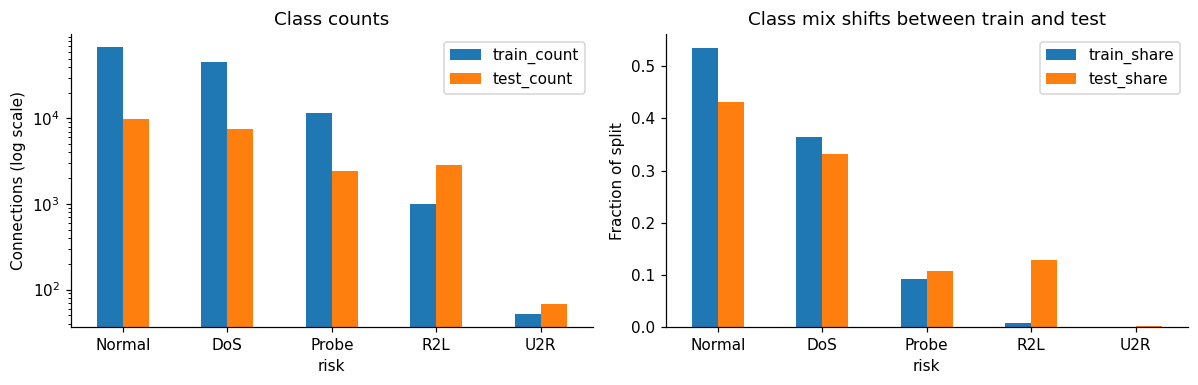

R2L and U2R techniques in each split (the main source of difficulty):


,family,train_rows,test_rows,test_only
attack,,,,
guess_passwd,R2L,53,1231,False
warezmaster,R2L,20,944,False
snmpguess,R2L,0,331,True
snmpgetattack,R2L,0,178,True
httptunnel,R2L,0,133,True
multihop,R2L,7,18,False
named,R2L,0,17,True
sendmail,R2L,0,14,True
xlock,R2L,0,9,True


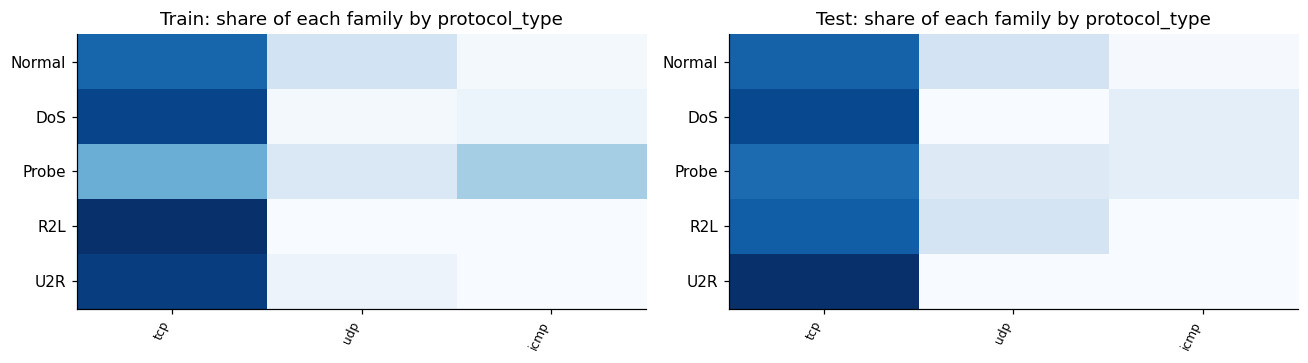

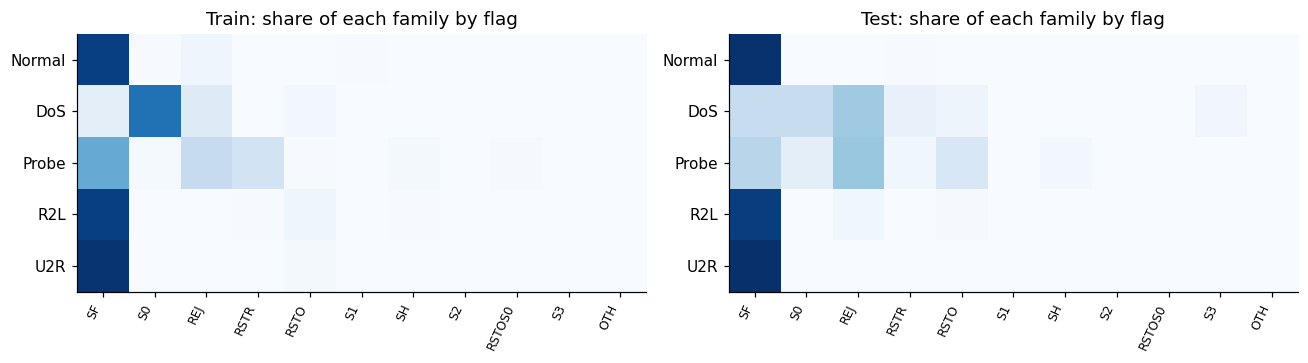

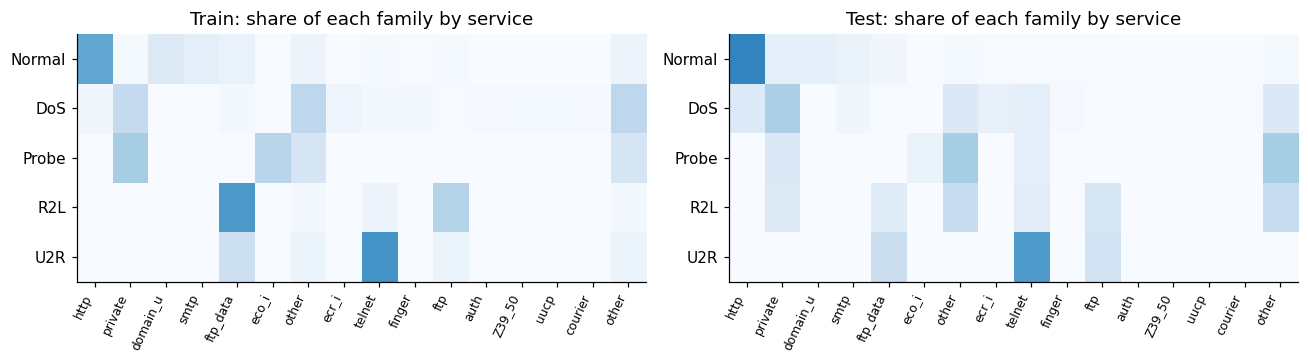

Family x protocol (train counts):


protocol_type,tcp,udp,icmp
risk,,,
Normal,53600,12434,1309
DoS,42188,892,2847
Probe,5857,1664,4135
R2L,995,0,0
U2R,49,3,0


Family x connection flag (train counts):


flag,SF,S0,REJ,RSTR,RSTO,S1,SH,S2,RSTOS0,S3,OTH
risk,,,,,,,,,,,
Normal,63393,354,2693,146,219,361,2,119,0,45,11
DoS,4599,34344,5671,90,1216,2,0,5,0,0,0
Probe,5967,153,2869,2180,80,1,265,2,103,1,35
R2L,935,0,0,5,46,1,4,1,0,3,0
U2R,51,0,0,0,1,0,0,0,0,0,0


In [3]:
class_distribution = pd.DataFrame({
    'train_count': train.risk.value_counts().reindex(CLASSES, fill_value=0),
    'test_count': test.risk.value_counts().reindex(CLASSES, fill_value=0),
})
class_distribution['train_share'] = class_distribution.train_count / len(train)
class_distribution['test_share'] = class_distribution.test_count / len(test)
class_distribution['share_change'] = class_distribution.test_share - class_distribution.train_share
display(class_distribution.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
class_distribution[['train_count', 'test_count']].plot.bar(ax=axes[0], logy=True, rot=0)
axes[0].set_ylabel('Connections (log scale)')
axes[0].set_title('Class counts')
class_distribution[['train_share', 'test_share']].plot.bar(ax=axes[1], rot=0)
axes[1].set_ylabel('Fraction of split')
axes[1].set_title('Class mix shifts between train and test')
plt.tight_layout(); plt.show()

# Attack techniques per family: which ones the model can learn, and which ones it will face.
attack_counts = pd.DataFrame({
    'family': pd.concat([train, test]).groupby('attack').risk.first(),
    'train_rows': train.attack.value_counts(),
    'test_rows': test.attack.value_counts(),
}).fillna(0)
attack_counts[['train_rows', 'test_rows']] = attack_counts[['train_rows', 'test_rows']].astype(int)
attack_counts['test_only'] = attack_counts.train_rows.eq(0)
print('R2L and U2R techniques in each split (the main source of difficulty):')
display(attack_counts[attack_counts.family.isin(['R2L', 'U2R'])]
        .sort_values(['family', 'test_rows'], ascending=[True, False]))

traffic_tables = {}
for feature, top in [('protocol_type', None), ('flag', None), ('service', 15)]:
    levels = train[feature].value_counts().index
    levels = levels if top is None else levels[:top]
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
    traffic_tables[feature] = {}
    for axis, frame, label in zip(axes, [train, test], ['Train', 'Test']):
        category = frame[feature].where(frame[feature].isin(levels), 'other')
        table = pd.crosstab(frame.risk, category).reindex(index=CLASSES, fill_value=0)
        table = table.reindex(columns=[*levels, 'other'], fill_value=0)
        table = table.loc[:, table.sum(axis=0) > 0]
        traffic_tables[feature][label] = table
        shares = table.div(table.sum(axis=1), axis=0).fillna(0)
        axis.imshow(shares, cmap='Blues', aspect='auto', vmin=0, vmax=1)
        axis.set(yticks=range(len(CLASSES)), yticklabels=CLASSES,
                 xticks=range(len(shares.columns)), title=f'{label}: share of each family by {feature}')
        axis.set_xticklabels(shares.columns, rotation=65, ha='right', fontsize=8)
    plt.tight_layout(); plt.show()

print('Family x protocol (train counts):')
display(traffic_tables['protocol_type']['Train'])
print('Family x connection flag (train counts):')
display(traffic_tables['flag']['Train'])

**What the exploratory analysis tells us, and how it shapes the models**

- **Severe imbalance.** U2R is 52 of 125,973 training rows and R2L is under 1%. Plain accuracy would hide failures on these classes, so every model below is also judged on macro F1 and per-class recall, and the main model uses class weighting.
- **The test set is harder by design.** R2L rises from under 1% of training to about 13% of test, and its make-up changes: training R2L is dominated by `warezclient`, which never appears in test, while test R2L is dominated by `guess_passwd`, `warezmaster` and test-only SNMP attacks. A model can only do well here if it generalises beyond the exact attacks it was trained on. This motivates the validation design in §4 and the anomaly detector in §7.
- **Traffic categories separate some families.** DoS concentrates in `S0`/`REJ` flags and the `private` service, Probe is over-represented in `REJ`/`RSTR` flags and ICMP, while R2L and U2R mostly sit on normal-looking `SF` TCP sessions. That last point explains why R2L and U2R are the hardest families to detect from connection-level features.

## 3. Train-fitted preprocessing

Categorical vocabularies (protocol, service, flag) are learned from training data; a test category never seen in training becomes an all-zero row. Byte, count and duration features are log-transformed because they span several orders of magnitude, and constant columns are dropped. The difficulty column, attack names and labels are never features.

In [4]:
ytr = train.risk.to_numpy()
yte = test.risk.to_numpy()
base_numeric = [c for c in COLUMNS if c not in CAT + ['label', 'difficulty']]
engineered = ['log_src_bytes', 'log_dst_bytes', 'log_count', 'log_srv_count', 'log_duration', 'byte_ratio']
numeric_cols = [c for c in base_numeric + engineered if train[c].nunique() > 1]
cat_levels = {c: sorted(train[c].astype(str).unique()) for c in CAT}
Xtr = encode_matrix(train, numeric_cols, cat_levels)
Xte = encode_matrix(test, numeric_cols, cat_levels)
assert np.isfinite(Xtr).all() and np.isfinite(Xte).all()
assert not {'difficulty', 'label', 'attack', 'risk'} & set(numeric_cols)
print('Encoded feature matrix:', Xtr.shape, '| test:', Xte.shape)
print('Dropped constant columns:', [c for c in base_numeric + engineered if c not in numeric_cols])
print('Unseen test categories:', {c: sorted(set(test[c].astype(str)) - set(cat_levels[c])) for c in CAT})

Encoded feature matrix: (125973, 127) | test: (22544, 127)
Dropped constant columns: ['num_outbound_cmds']
Unseen test categories: {'protocol_type': [], 'service': [], 'flag': []}


## 4. Model selection with leave-attack-type-out validation

**Why not a random validation split?** A random 20% slice of `KDDTrain+` contains the same attack techniques as the training rows. It rewards models that memorise those techniques, which then fail on the official test set (the comparison at the end of this section shows how misleading it is). The real task is to recognise attacks that look different from training.

**Design.** Within each family, attack *names* are shuffled and spread over three folds, so every validation fold contains attack techniques its training fold has never seen, while every training fold still contains every family. Normal rows are split randomly. The official test set is not touched until selection is frozen.

**Candidates** (the standard algorithms in the intrusion-detection literature):
logistic regression, linear SVM, decision tree, random forest, Extra Trees, gradient boosting (unweighted, class-weighted, and with random oversampling of R2L/U2R), and a soft-voting ensemble of class-weighted boosting and random forest. Linear models are trained with stochastic gradient descent (log loss for logistic regression, modified-Huber loss for the SVM) so they scale to 126k rows and give probability scores. Gradient boosting is scikit-learn's histogram implementation, the same algorithm family as XGBoost and LightGBM.

**Selection rule, fixed in advance:** highest validation accuracy among models whose validation Normal false-alarm rate is at most 3%; ties are broken by macro F1.

In [5]:
HGB_PARAMETERS = dict(learning_rate=0.06, max_iter=280, max_depth=10, min_samples_leaf=12, random_state=SEED)


def new_classifier(name):
    if name == 'Logistic regression':
        return make_pipeline(StandardScaler(), SGDClassifier(
            loss='log_loss', alpha=1e-4, class_weight='balanced', early_stopping=True,
            n_iter_no_change=10, max_iter=1000, tol=1e-3, random_state=SEED))
    if name == 'Linear SVM':
        return make_pipeline(StandardScaler(), SGDClassifier(
            loss='modified_huber', alpha=1e-4, class_weight='balanced', early_stopping=True,
            n_iter_no_change=10, max_iter=1000, tol=1e-3, random_state=SEED))
    if name == 'Decision tree':
        return DecisionTreeClassifier(max_depth=20, min_samples_leaf=5, class_weight='balanced',
                                      random_state=SEED)
    if name == 'Random forest':
        return RandomForestClassifier(n_estimators=150, min_samples_leaf=2, max_features='sqrt',
                                      class_weight='balanced_subsample', n_jobs=CPU_THREADS,
                                      random_state=SEED)
    if name == 'Extra trees':
        return ExtraTreesClassifier(n_estimators=150, max_depth=32, min_samples_leaf=2,
                                    class_weight='balanced', n_jobs=CPU_THREADS, random_state=SEED)
    if name == 'Gradient boosting (unweighted)':
        return HistGradientBoostingClassifier(**HGB_PARAMETERS)
    if name == 'Gradient boosting (class-weighted)':
        return HistGradientBoostingClassifier(class_weight='balanced', **HGB_PARAMETERS)
    if name == 'Gradient boosting (oversampled)':
        return HistGradientBoostingClassifier(**HGB_PARAMETERS)
    raise KeyError(name)


MODEL_NAMES = ['Logistic regression', 'Linear SVM', 'Decision tree', 'Random forest', 'Extra trees',
               'Gradient boosting (unweighted)', 'Gradient boosting (class-weighted)',
               'Gradient boosting (oversampled)']
ENSEMBLE = 'Soft vote (boosting + random forest)'


def oversample_indices(labels, seed):
    """Random oversampling: repeat real R2L/U2R rows (no synthetic one-hot values)."""
    rng = np.random.default_rng(seed)
    parts = [np.arange(len(labels))]
    for label, target in [('R2L', 8000), ('U2R', 2000)]:
        pool = np.flatnonzero(labels == label)
        parts.append(rng.choice(pool, size=max(0, target - len(pool)), replace=True))
    return rng.permutation(np.concatenate(parts))


def fit_classifier(name, matrix, labels):
    model = new_classifier(name)
    if name == 'Gradient boosting (oversampled)':
        rows = oversample_indices(labels, SEED)
        return model.fit(matrix[rows], labels[rows])
    return model.fit(matrix, labels)


def predict_scores(model, matrix):
    return align_proba(list(model.classes_), model.predict_proba(matrix))


def soft_vote(scores):
    return 0.5 * scores['Gradient boosting (class-weighted)'] + 0.5 * scores['Random forest']


def fit_predict_primary(train_matrix, labels, other_matrix):
    """Fit the selected primary model (or both ensemble members) and score other_matrix."""
    if SELECTED_NAME == ENSEMBLE:
        return soft_vote({n: predict_scores(fit_classifier(n, train_matrix, labels), other_matrix)
                          for n in ['Gradient boosting (class-weighted)', 'Random forest']})
    return predict_scores(fit_classifier(SELECTED_NAME, train_matrix, labels), other_matrix)


def to_family(scores):
    return np.asarray(CLASSES)[np.asarray(scores).argmax(axis=1)]


def normal_fpr(truth, predicted):
    truth, predicted = np.asarray(truth), np.asarray(predicted)
    return float(np.mean(predicted[truth == 'Normal'] != 'Normal'))


def leave_attack_type_out_folds(frame, n_folds, seed):
    rng = np.random.default_rng(seed)
    fold = np.empty(len(frame), dtype=np.int64)
    is_normal = (frame.risk == 'Normal').to_numpy()
    fold[is_normal] = rng.integers(0, n_folds, is_normal.sum())
    assignment = {}
    for fam in ['DoS', 'Probe', 'R2L', 'U2R']:
        names = sorted(frame.loc[frame.risk == fam, 'attack'].unique())
        names = list(rng.permutation(names))
        for i, name in enumerate(names):
            assignment[name] = i % n_folds
    fold[~is_normal] = frame.attack[~is_normal].map(assignment).to_numpy()
    return fold, assignment


fold_id, fold_assignment = leave_attack_type_out_folds(train, FOLDS, SEED)
for f in range(FOLDS):
    fit_rows, val_rows = fold_id != f, fold_id == f
    assert set(ytr[fit_rows]) == set(CLASSES), 'every training fold must contain every family'
    assert set(train.attack[val_rows]) - {'normal'} <= {n for n, k in fold_assignment.items() if k == f}
held_out = pd.DataFrame([(fam, f, ', '.join(sorted(n for n, k in fold_assignment.items()
                                                  if k == f and family(n) == fam)))
                         for f in range(FOLDS) for fam in ['DoS', 'Probe', 'R2L', 'U2R']],
                        columns=['family', 'fold', 'attack types held out of training'])
display(held_out.pivot(index='fold', columns='family', values='attack types held out of training'))

oof_scores = {name: np.zeros((len(train), len(CLASSES))) for name in MODEL_NAMES}
fit_seconds = {name: 0.0 for name in MODEL_NAMES}
for f in range(FOLDS):
    fit_rows, val_rows = fold_id != f, fold_id == f
    for name in MODEL_NAMES:
        start = time.perf_counter()
        model = fit_classifier(name, Xtr[fit_rows], ytr[fit_rows])
        oof_scores[name][val_rows] = predict_scores(model, Xtr[val_rows])
        fit_seconds[name] += time.perf_counter() - start
    print(f'fold {f + 1}/{FOLDS} done', flush=True)
oof_scores[ENSEMBLE] = soft_vote(oof_scores)


def summary_row(name, truth, predicted, scores):
    truth = np.asarray(truth)
    _, recall, _, _ = precision_recall_fscore_support(truth, predicted, labels=CLASSES, zero_division=0)
    return dict(model=name,
                accuracy=accuracy_score(truth, predicted),
                macro_f1=f1_score(truth, predicted, average='macro', zero_division=0),
                attack_detection=float(np.mean(predicted[truth != 'Normal'] != 'Normal')),
                normal_fpr=normal_fpr(truth, predicted),
                R2L_recall=recall[3], U2R_recall=recall[4],
                binary_auc=roc_auc_score(truth != 'Normal', 1 - scores[:, 0]))


validation_table = pd.DataFrame([summary_row(name, ytr, to_family(s), s) for name, s in oof_scores.items()])
eligible = validation_table[validation_table.normal_fpr <= 0.03]
SELECTED_NAME = eligible.sort_values(['accuracy', 'macro_f1'], ascending=False).iloc[0]['model']
print('Leave-attack-type-out validation (attack rows are always unseen techniques):')
display(validation_table.sort_values('accuracy', ascending=False).round(4))
print('FROZEN SELECTION:', SELECTED_NAME)

# How misleading a random split would have been: same models, random stratified 80/20 split.
rand_fit, rand_val = train_test_split(np.arange(len(train)), test_size=0.2, stratify=ytr, random_state=SEED)
random_split_rows = []
for name in ['Gradient boosting (class-weighted)', 'Gradient boosting (oversampled)']:
    model = fit_classifier(name, Xtr[rand_fit], ytr[rand_fit])
    predicted = to_family(predict_scores(model, Xtr[rand_val]))
    random_split_rows.append(dict(model=name,
                                  random_split_macro_f1=f1_score(ytr[rand_val], predicted, average='macro')))
random_split_table = pd.DataFrame(random_split_rows)

family,DoS,Probe,R2L,U2R
fold,,,,
0,"smurf, teardrop","ipsweep, nmap","guess_passwd, imap, multihop","buffer_overflow, rootkit"
1,"land, neptune",portsweep,"ftp_write, phf, spy",perl
2,"back, pod",satan,"warezclient, warezmaster",loadmodule


fold 1/3 done


fold 2/3 done


fold 3/3 done


Leave-attack-type-out validation (attack rows are always unseen techniques):


,model,accuracy,macro_f1,attack_detection,normal_fpr,R2L_recall,U2R_recall,binary_auc
6,Gradient boosting (class-weighted),0.6099,0.2945,0.8609,0.0023,0.0080,0.1923,0.9914
8,Soft vote (boosting + random forest),0.6039,0.3012,0.8434,0.0013,0.0080,0.1731,0.9968
2,Decision tree,0.5876,0.2895,0.7833,0.0054,0.0291,0.2500,0.8934
7,Gradient boosting (oversampled),0.5864,0.2905,0.7546,0.0006,0.0141,0.1731,0.9920
5,Gradient boosting (unweighted),0.5829,0.2490,0.7933,0.0041,0.0442,0.0769,0.9540
4,Extra trees,0.5747,0.3049,0.4998,0.0034,0.0261,0.5000,0.9891
3,Random forest,0.5742,0.2802,0.7258,0.0006,0.0121,0.1923,0.9962
1,Linear SVM,0.5692,0.2284,0.3766,0.0111,0.0020,0.0962,0.7427
0,Logistic regression,0.5676,0.2889,0.4691,0.0274,0.5759,0.4615,0.7347


FROZEN SELECTION: Gradient boosting (class-weighted)


## 5. Official test evaluation under class imbalance

Every candidate is refitted on the full `KDDTrain+` file and scored once on `KDDTest+`. The primary model is the one frozen in §4, whatever the test table shows. Reported for each model: accuracy, macro F1 (all five classes weighted equally), weighted F1, R2L/U2R recall, the false-alarm rate on Normal traffic, and the attack-vs-normal ROC AUC. For the primary model: per-class precision/recall/F1, the confusion matrix, one-vs-rest ROC and precision–recall curves (PR curves are more informative than ROC for rare classes), Wilson 95% intervals for R2L/U2R recall, and recall for every individual R2L/U2R attack technique.

refitted Logistic regression (2.1s)


refitted Linear SVM (1.4s)


refitted Decision tree (1.0s)


refitted Random forest (6.8s)


refitted Extra trees (8.1s)


refitted Gradient boosting (unweighted) (4.6s)


... (6 outputs left out)

PRIMARY MODEL: Gradient boosting (class-weighted)
Five-class test accuracy: 80.24% | macro F1: 0.6861


,precision,recall,f1,support
Normal,0.7142,0.9704,0.8228,9711
DoS,0.9629,0.7862,0.8656,7460
Probe,0.8195,0.8141,0.8168,2421
R2L,0.9877,0.2787,0.4347,2885
U2R,0.6667,0.3881,0.4906,67


Attack vs normal (primary model): {'accuracy': 0.82, 'precision': 0.9693, 'recall': 0.7061, 'f1': 0.8171, 'normal_fpr': 0.0296, 'roc_auc': 0.9458}


,family,training_rows,test_rows,correct_family,flagged_as_some_attack,predicted_normal,recall_ci_low,recall_ci_high
0,R2L,995,2885,804,851,2034,0.2626,0.2953
1,U2R,52,67,26,31,36,0.2805,0.5078


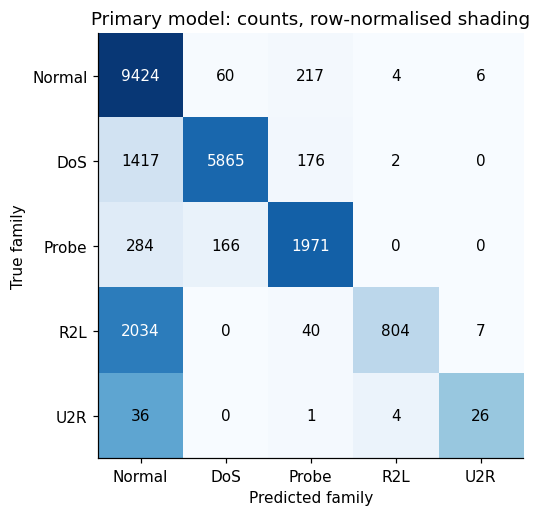

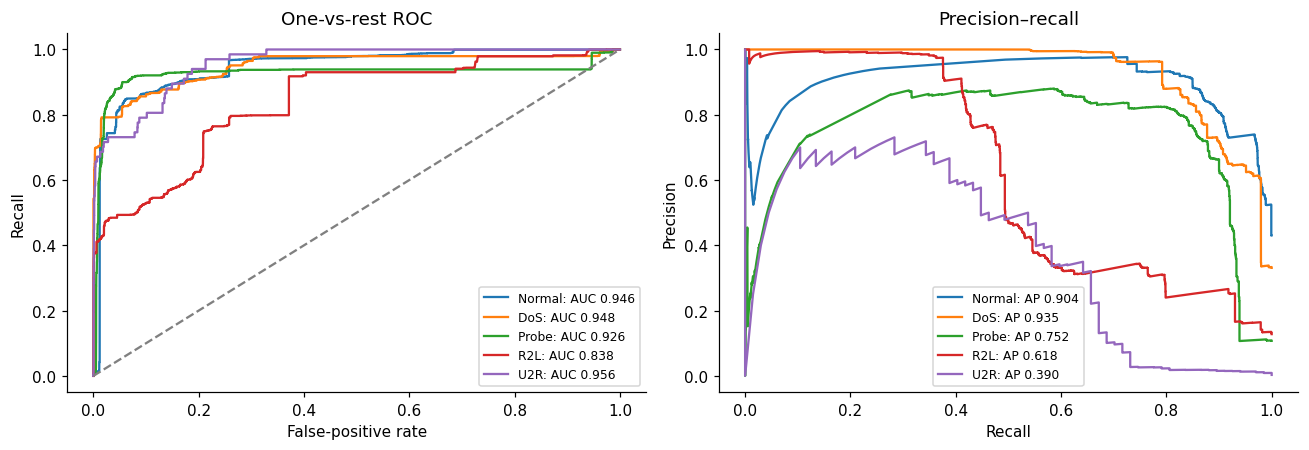

,family,roc_auc,average_precision,prevalence
0,Normal,0.9458,0.9041,0.4308
1,DoS,0.9478,0.9345,0.3309
2,Probe,0.9259,0.7524,0.1074
3,R2L,0.8381,0.6183,0.1280
4,U2R,0.9562,0.3897,0.0030


Per-technique results for R2L and U2R (train_rows = examples available for learning):


,attack,risk,test_only,support,family_recall,detected_as_attack,train_rows
4,guess_passwd,R2L,False,1231,0.0512,0.0512,53
33,warezmaster,R2L,False,944,0.7786,0.7786,20
29,snmpguess,R2L,True,331,0.0000,0.0030,0
28,snmpgetattack,R2L,True,178,0.0000,0.0000,0
5,httptunnel,R2L,True,133,0.0000,0.2556,0
12,multihop,R2L,False,18,0.1111,0.3889,7
13,named,R2L,True,17,0.0588,0.3529,0
26,sendmail,R2L,True,14,0.0000,0.0714,0
35,xlock,R2L,True,9,0.0000,0.0000,0
36,xsnoop,R2L,True,4,0.0000,0.2500,0


In [6]:
final_models, test_scores = {}, {}
for name in MODEL_NAMES:
    start = time.perf_counter()
    final_models[name] = fit_classifier(name, Xtr, ytr)
    test_scores[name] = predict_scores(final_models[name], Xte)
    print(f'refitted {name} ({time.perf_counter() - start:.1f}s)', flush=True)
test_scores[ENSEMBLE] = soft_vote(test_scores)

def primary_scores_for(matrix):
    """Scores from the frozen primary model (already fitted on all of KDDTrain+)."""
    if SELECTED_NAME == ENSEMBLE:
        return soft_vote({n: predict_scores(final_models[n], matrix)
                          for n in ['Gradient boosting (class-weighted)', 'Random forest']})
    return predict_scores(final_models[SELECTED_NAME], matrix)


primary_scores = test_scores[SELECTED_NAME]
primary_prediction = to_family(primary_scores)


def test_row(name, scores):
    predicted = to_family(scores)
    row = summary_row(name, yte, predicted, scores)
    row['weighted_f1'] = f1_score(yte, predicted, average='weighted')
    return row


comparison = pd.DataFrame([test_row(name, s) for name, s in test_scores.items()])
comparison['selected'] = comparison.model.eq(SELECTED_NAME)
comparison = comparison[['model', 'selected', 'accuracy', 'macro_f1', 'weighted_f1', 'R2L_recall',
                         'U2R_recall', 'attack_detection', 'normal_fpr', 'binary_auc']]
print('Official KDDTest+ results (all candidates):')
display(comparison.sort_values('accuracy', ascending=False).round(4))

gap = validation_table[['model', 'macro_f1']].rename(columns={'macro_f1': 'leave_attack_out_macro_f1'})
gap = gap.merge(comparison[['model', 'macro_f1']].rename(columns={'macro_f1': 'test_macro_f1'}), on='model')
gap = gap.merge(random_split_table, on='model', how='left')
print('Validation design check: a random split rates the oversampled model highly, the test set does not.')
display(gap[gap.model.isin(random_split_table.model)].round(4))


def family_metrics(truth, predicted):
    p, r, f, n = precision_recall_fscore_support(truth, predicted, labels=CLASSES, zero_division=0)
    return pd.DataFrame({'precision': p, 'recall': r, 'f1': f, 'support': n}, index=CLASSES)


primary_per_class = family_metrics(yte, primary_prediction)
PRIMARY_ACCURACY = accuracy_score(yte, primary_prediction)
PRIMARY_MACRO_F1 = f1_score(yte, primary_prediction, average='macro')
print(f'PRIMARY MODEL: {SELECTED_NAME}')
print(f'Five-class test accuracy: {PRIMARY_ACCURACY:.2%} | macro F1: {PRIMARY_MACRO_F1:.4f}')
display(primary_per_class.round(4))

binary_truth = yte != 'Normal'
binary_pred = primary_prediction != 'Normal'
bp, br, bf, _ = precision_recall_fscore_support(binary_truth, binary_pred, average='binary')
PRIMARY_BINARY = dict(accuracy=float(np.mean(binary_truth == binary_pred)), precision=float(bp),
                      recall=float(br), f1=float(bf), normal_fpr=normal_fpr(yte, primary_prediction),
                      roc_auc=float(roc_auc_score(binary_truth, 1 - primary_scores[:, 0])))
print('Attack vs normal (primary model):', {k: round(v, 4) for k, v in PRIMARY_BINARY.items()})


def wilson_interval(successes, total, z=1.96):
    rate = successes / total
    denominator = 1 + z * z / total
    center = (rate + z * z / (2 * total)) / denominator
    width = z * np.sqrt(rate * (1 - rate) / total + z * z / (4 * total * total)) / denominator
    return center - width, center + width


minority_rows = []
for label in ['R2L', 'U2R']:
    mask = yte == label
    correct = int((primary_prediction[mask] == label).sum())
    low, high = wilson_interval(correct, int(mask.sum()))
    minority_rows.append(dict(family=label, training_rows=int((ytr == label).sum()), test_rows=int(mask.sum()),
                              correct_family=correct,
                              flagged_as_some_attack=int((primary_prediction[mask] != 'Normal').sum()),
                              predicted_normal=int((primary_prediction[mask] == 'Normal').sum()),
                              recall_ci_low=low, recall_ci_high=high))
display(pd.DataFrame(minority_rows).round(4))

matrix = confusion_matrix(yte, primary_prediction, labels=CLASSES)
fig, ax = plt.subplots(figsize=(6.2, 4.8))
ax.imshow(matrix / matrix.sum(axis=1, keepdims=True), cmap='Blues', vmin=0, vmax=1)
for i in range(5):
    for j in range(5):
        ax.text(j, i, str(matrix[i, j]), ha='center', va='center',
                color='white' if matrix[i, j] / matrix[i].sum() > .6 else 'black')
ax.set(xticks=range(5), yticks=range(5), xticklabels=CLASSES, yticklabels=CLASSES,
       xlabel='Predicted family', ylabel='True family', title='Primary model: counts, row-normalised shading')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
curve_metrics = []
for column, label in enumerate(CLASSES):
    is_label = yte == label
    fpr, tpr, _ = roc_curve(is_label, primary_scores[:, column])
    precision, recall, _ = precision_recall_curve(is_label, primary_scores[:, column])
    auc = roc_auc_score(is_label, primary_scores[:, column])
    ap = average_precision_score(is_label, primary_scores[:, column])
    axes[0].plot(fpr, tpr, label=f'{label}: AUC {auc:.3f}')
    axes[1].plot(recall, precision, label=f'{label}: AP {ap:.3f}')
    curve_metrics.append(dict(family=label, roc_auc=auc, average_precision=ap, prevalence=is_label.mean()))
axes[0].plot([0, 1], [0, 1], '--', color='grey')
axes[0].set(xlabel='False-positive rate', ylabel='Recall', title='One-vs-rest ROC')
axes[1].set(xlabel='Recall', ylabel='Precision', title='Precision–recall')
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
display(pd.DataFrame(curve_metrics).round(4))

breakdown = test[['attack', 'risk']].copy()
breakdown['correct_family'] = primary_prediction == yte
breakdown['detected_as_attack'] = primary_prediction != 'Normal'
breakdown['test_only'] = novel_mask
attack_name_results = breakdown.groupby(['attack', 'risk', 'test_only']).agg(
    support=('correct_family', 'size'), family_recall=('correct_family', 'mean'),
    detected_as_attack=('detected_as_attack', 'mean')).reset_index()
attack_name_results = attack_name_results.merge(
    attack_counts[['train_rows']], left_on='attack', right_index=True, how='left')
print('Per-technique results for R2L and U2R (train_rows = examples available for learning):')
display(attack_name_results[attack_name_results.risk.isin(['R2L', 'U2R'])]
        .sort_values(['risk', 'support'], ascending=[True, False]).round(4))

**Reading the R2L / U2R results.** When the model predicts R2L it is almost always right (high precision), but it misses most R2L traffic, labelling it Normal. The per-technique table shows why: the test set is dominated by techniques that were rare (`guess_passwd`, `warezmaster`) or absent (`snmpguess`, `snmpgetattack`, `httptunnel`) in training, and these attacks are single, normal-looking sessions at the connection level. Oversampling makes this worse because repeating the same training examples teaches the model those exact examples more firmly. The remedy explored next is not another classifier but a detector that models *normal* traffic and flags what does not fit.

## 6. Unsupervised structure: clustering

Mini-batch k-means groups connections without using labels. Inputs are the log-transformed, standardised numeric traffic features (scaler fitted on training data). The number of clusters is chosen by the silhouette score on a fixed training sample over k = 4…20. Labels are used only afterwards, to measure purity, ARI and NMI on the full official test set and to see where the 17 test-only attack types land. PCA is used only for the 2-D picture.

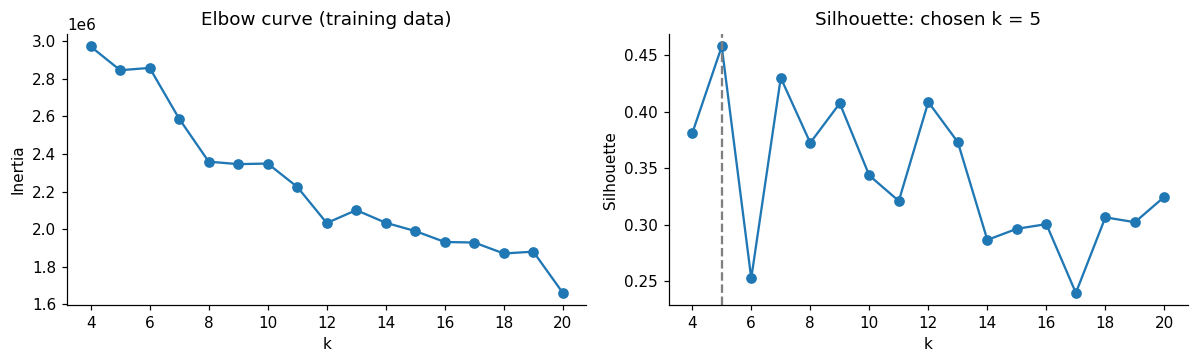

Cluster quality on the full official test set: {'k': 5, 'purity': 0.7302, 'ARI': 0.3719, 'NMI': 0.4058}


family,Normal,DoS,Probe,R2L,U2R,training_majority
cluster,,,,,,
0,153,12,1521,28,0,Probe
1,9164,2026,30,2309,48,Normal
2,2,1891,221,1,0,DoS
3,67,3457,384,118,0,DoS
4,325,74,265,429,19,Probe


Where the 17 test-only attack types fall (clusters were fitted without them):


,attack,family,rows,main_cluster,share_in_main_cluster,cluster_training_majority
0,apache2,DoS,737,3,0.427,DoS
1,httptunnel,R2L,133,3,0.729,DoS
2,mailbomb,DoS,293,1,1.000,Normal
3,mscan,Probe,996,0,0.514,Probe
4,named,R2L,17,4,0.588,Probe
5,processtable,DoS,685,1,0.629,Normal
6,ps,U2R,15,1,0.800,Normal
7,saint,Probe,319,0,0.665,Probe
8,sendmail,R2L,14,1,0.786,Normal
9,snmpgetattack,R2L,178,1,0.949,Normal


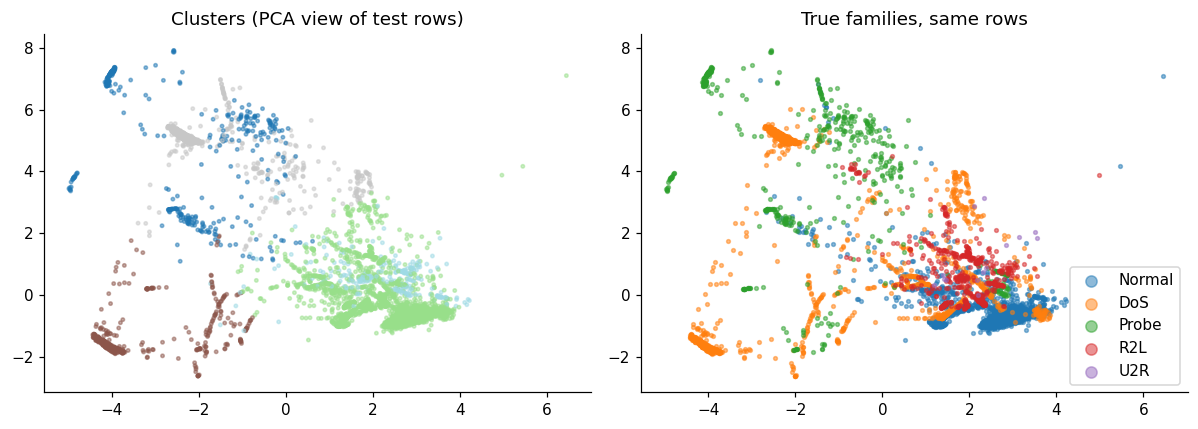

In [7]:
TRAFFIC_COLUMNS = [c for c in base_numeric if train[c].nunique() > 1]


def traffic_space(frame):
    return np.log1p(np.clip(frame[TRAFFIC_COLUMNS].to_numpy(dtype=np.float64), 0, None))


traffic_scaler = StandardScaler().fit(traffic_space(train))
Ztr = traffic_scaler.transform(traffic_space(train)).astype(np.float32)
Zte = traffic_scaler.transform(traffic_space(test)).astype(np.float32)

silhouette_rows = np.random.default_rng(SEED).choice(len(train), size=4000, replace=False)
cluster_candidates, cluster_selection = {}, []
for k in range(4, 21):
    km = MiniBatchKMeans(n_clusters=k, batch_size=4096, n_init=3, random_state=SEED).fit(Ztr)
    score = silhouette_score(Ztr[silhouette_rows], km.predict(Ztr[silhouette_rows]))
    cluster_candidates[k] = km
    cluster_selection.append(dict(k=k, inertia=float(km.inertia_), silhouette=float(score)))
cluster_selection = pd.DataFrame(cluster_selection)
chosen_k = int(cluster_selection.loc[cluster_selection.silhouette.idxmax(), 'k'])
cluster_model = cluster_candidates[chosen_k]
cluster_tr = cluster_model.predict(Ztr)
cluster_te = cluster_model.predict(Zte)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(cluster_selection.k, cluster_selection.inertia, marker='o')
axes[0].set(xlabel='k', ylabel='Inertia', title='Elbow curve (training data)')
axes[1].plot(cluster_selection.k, cluster_selection.silhouette, marker='o')
axes[1].axvline(chosen_k, ls='--', color='grey')
axes[1].set(xlabel='k', ylabel='Silhouette', title=f'Silhouette: chosen k = {chosen_k}')
plt.tight_layout(); plt.show()

composition = pd.crosstab(pd.Series(cluster_te, name='cluster'), pd.Series(yte, name='family'))
composition = composition.reindex(columns=CLASSES, fill_value=0)
train_majority = (pd.crosstab(pd.Series(cluster_tr, name='cluster'), pd.Series(ytr, name='family'))
                  .reindex(columns=CLASSES, fill_value=0).idxmax(axis=1))
composition['training_majority'] = train_majority.reindex(composition.index)
cluster_metrics = dict(k=chosen_k,
                       purity=float(composition[CLASSES].max(axis=1).sum() / len(test)),
                       ARI=float(adjusted_rand_score(yte, cluster_te)),
                       NMI=float(normalized_mutual_info_score(yte, cluster_te)))
print('Cluster quality on the full official test set:', {k: round(v, 4) for k, v in cluster_metrics.items()})
display(composition)

novel_rows = []
for name in sorted(test.attack[novel_mask].unique()):
    members = cluster_te[(test.attack == name).to_numpy()]
    top = int(np.bincount(members).argmax())
    novel_rows.append(dict(attack=name, family=family(name), rows=len(members), main_cluster=top,
                           share_in_main_cluster=float(np.mean(members == top)),
                           cluster_training_majority=train_majority.get(top, 'none')))
novel_clusters = pd.DataFrame(novel_rows)
print('Where the 17 test-only attack types fall (clusters were fitted without them):')
display(novel_clusters.round(3))

pca = PCA(n_components=2, random_state=SEED).fit(Ztr[silhouette_rows])
view = np.random.default_rng(SEED).choice(len(test), 5000, replace=False)
xy = pca.transform(Zte[view])
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(xy[:, 0], xy[:, 1], c=cluster_te[view], s=5, cmap='tab20', alpha=.5)
axes[0].set_title('Clusters (PCA view of test rows)')
for label in CLASSES:
    mask = yte[view] == label
    axes[1].scatter(xy[mask, 0], xy[mask, 1], s=6, alpha=.5, label=label)
axes[1].set_title('True families, same rows')
axes[1].legend(markerscale=3)
plt.tight_layout(); plt.show()

## 7. Normal-only anomaly detection and the hybrid detector

The supervised model can only recognise attacks resembling its training data. Two detectors instead learn what **normal** traffic looks like and flag anything far from it, so they need no attack labels:

- **Isolation Forest:** random trees isolate unusual points in few splits; a short path means an anomaly.
- **Centroid distance:** k-means (with the k chosen in §6) fitted on Normal traffic only; the score is the distance to the nearest Normal centroid.

**Hybrid rule.** The classifier keeps every attack it predicts. When it predicts Normal and the detector's score exceeds its threshold, the connection is labelled **`Unknown attack`** (the detector cannot say which family). Thresholds are the 95th percentile of scores on 15% of training Normal rows held out from fitting, a 5% false-alarm budget declared before testing.

**Choosing the detector without the test set.** On each leave-attack-type-out fold, detectors are fitted on that fold's training Normal rows and combined with the classifier's out-of-fold predictions; the detector with the better mean attack-detection F1 on the unseen-technique validation rows is used. A threshold sweep (90th–99th percentile) shows the recall/false-alarm trade-off on test.

Hybrid on unseen-technique validation folds (mean over folds):


,attack_recall,normal_fpr,f1
system,,,
Centroid distance,0.7772,0.0522,0.8139
Isolation forest,0.7332,0.0525,0.7804


FROZEN DETECTOR: Centroid distance


Official test set, threshold = 95th percentile of held-out training Normal:


,system,attack_recall,precision,f1,normal_fpr,binary_accuracy,new_alerts,new_alerts_that_are_attacks,novel_attack_detection
0,Classifier alone,0.7061,0.9693,0.8171,0.0296,0.8200,NaN,NaN,0.3808
1,Isolation forest alone,0.6559,0.9716,0.7831,0.0253,0.7932,NaN,NaN,0.6773
2,Hybrid: classifier + Isolation forest,0.8088,0.9686,0.8815,0.0347,0.8762,1367.0,0.9634,0.7179
3,Centroid distance alone,0.3976,0.9468,0.5601,0.0296,0.6444,NaN,NaN,0.4856
4,Hybrid: classifier + Centroid distance,0.7998,0.9618,0.8733,0.0420,0.8679,1323.0,0.9085,0.5848


Attacks the classifier labelled Normal, and how many Centroid distance recovers:


,family,missed_by_classifier,recovered_by_hybrid,recovered_share
0,DoS,1417,708,0.500
1,Probe,284,27,0.095
2,R2L,2034,445,0.219
3,U2R,36,22,0.611


Test-only attack types:


,missed,recovered,test_rows
attack,,,
mscan,280,27,996
apache2,532,283,737
processtable,552,423,685
snmpguess,330,0,331
saint,4,0,319
mailbomb,293,0,293
snmpgetattack,178,2,178
httptunnel,99,1,133
named,11,4,17


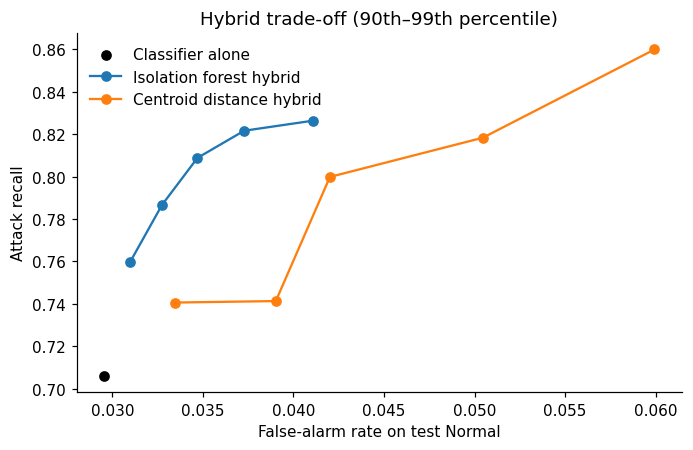

attack_recall                                       normal_fpr                        
system     Centroid distance hybrid Isolation forest hybrid Centroid distance hybrid Isolation forest hybrid
percentile                                                                                                  
90.0                         0.8598                  0.8263                   0.0599                  0.0411
92.5                         0.8183                  0.8216                   0.0505                  0.0373
95.0                         0.7998                  0.8088                   0.0420                  0.0347
97.5                         0.7414                  0.7866                   0.0390                  0.0327
99.0                         0.7407                  0.7599                   0.0335                  0.0310

In [8]:
DETECTORS = ['Isolation forest', 'Centroid distance']


def fit_detectors(normal_rows_space, seed):
    iso = IsolationForest(n_estimators=200, n_jobs=CPU_THREADS, random_state=seed).fit(normal_rows_space)
    cen = MiniBatchKMeans(n_clusters=chosen_k, n_init=3, batch_size=4096, random_state=seed).fit(normal_rows_space)
    return {'Isolation forest': lambda Z: -iso.score_samples(Z),
            'Centroid distance': lambda Z: cen.transform(Z).min(axis=1)}


def split_normal(rows, seed, holdout=0.15):
    rows = np.random.default_rng(seed).permutation(rows)
    cut = int(round(holdout * len(rows)))
    return rows[cut:], rows[:cut]


def detection_summary(name, truth, alerts, base_alerts=None):
    truth = np.asarray(truth)
    attack = truth != 'Normal'
    p, r, f, _ = precision_recall_fscore_support(attack, alerts, average='binary', zero_division=0)
    row = dict(system=name, attack_recall=float(r), precision=float(p), f1=float(f),
               normal_fpr=float(np.mean(alerts[~attack])), binary_accuracy=float(np.mean(alerts == attack)))
    if base_alerts is not None:
        new = alerts & ~base_alerts
        row['new_alerts'] = int(new.sum())
        row['new_alerts_that_are_attacks'] = float(np.mean(attack[new])) if new.any() else float('nan')
    return row


# --- detector choice on leave-attack-type-out folds (no test data) ---
oof_primary = to_family(oof_scores[SELECTED_NAME])
choice_rows = []
for f in range(FOLDS):
    fit_rows, val_rows = np.flatnonzero(fold_id != f), np.flatnonzero(fold_id == f)
    normal_fit, normal_hold = split_normal(fit_rows[ytr[fit_rows] == 'Normal'], SEED + f)
    scorers = fit_detectors(Ztr[normal_fit], SEED + f)
    base = oof_primary[val_rows] != 'Normal'
    for name in DETECTORS:
        threshold = np.percentile(scorers[name](Ztr[normal_hold]), ANOMALY_PERCENTILE)
        alerts = base | (scorers[name](Ztr[val_rows]) > threshold)
        row = detection_summary(name, ytr[val_rows], alerts)
        row['fold'] = f
        choice_rows.append(row)
detector_choice = pd.DataFrame(choice_rows).groupby('system')[['attack_recall', 'normal_fpr', 'f1']].mean()
SELECTED_DETECTOR = detector_choice.f1.idxmax()
print('Hybrid on unseen-technique validation folds (mean over folds):')
display(detector_choice.round(4))
print('FROZEN DETECTOR:', SELECTED_DETECTOR)

# --- final detectors: fitted on training Normal, thresholds from held-out training Normal ---
normal_fit, normal_hold = split_normal(np.flatnonzero(ytr == 'Normal'), SEED)
scorers = fit_detectors(Ztr[normal_fit], SEED)
holdout_scores = {name: scorers[name](Ztr[normal_hold]) for name in DETECTORS}
test_anomaly = {name: scorers[name](Zte) for name in DETECTORS}
thresholds = {name: float(np.percentile(holdout_scores[name], ANOMALY_PERCENTILE)) for name in DETECTORS}
flags = {name: test_anomaly[name] > thresholds[name] for name in DETECTORS}

base_alerts = primary_prediction != 'Normal'
hybrid_rows = [detection_summary('Classifier alone', yte, base_alerts)]
for name in DETECTORS:
    hybrid_rows.append(detection_summary(f'{name} alone', yte, flags[name]))
    hybrid_rows.append(detection_summary(f'Hybrid: classifier + {name}', yte, base_alerts | flags[name], base_alerts))
hybrid_table = pd.DataFrame(hybrid_rows)
hybrid_table['novel_attack_detection'] = [
    float(np.mean(a[novel_mask])) for a in
    [base_alerts] + [x for name in DETECTORS for x in (flags[name], base_alerts | flags[name])]]
print(f'Official test set, threshold = {ANOMALY_PERCENTILE:g}th percentile of held-out training Normal:')
display(hybrid_table.round(4))

hybrid_prediction = primary_prediction.astype(object).copy()
hybrid_prediction[(primary_prediction == 'Normal') & flags[SELECTED_DETECTOR]] = 'Unknown attack'
hybrid_alerts = hybrid_prediction != 'Normal'
HYBRID = detection_summary('Hybrid (selected)', yte, hybrid_alerts, base_alerts)
HYBRID['novel_attack_detection'] = float(np.mean(hybrid_alerts[novel_mask]))
HYBRID['five_class_accuracy_unknown_counted_wrong'] = float(np.mean(hybrid_prediction == yte))

missed = (primary_prediction == 'Normal') & (yte != 'Normal')
recovered = missed & flags[SELECTED_DETECTOR]
by_family = pd.DataFrame([dict(family=fam, missed_by_classifier=int((missed & (yte == fam)).sum()),
                               recovered_by_hybrid=int((recovered & (yte == fam)).sum()))
                          for fam in ['DoS', 'Probe', 'R2L', 'U2R']])
by_family['recovered_share'] = by_family.recovered_by_hybrid / by_family.missed_by_classifier.clip(lower=1)
print(f'Attacks the classifier labelled Normal, and how many {SELECTED_DETECTOR} recovers:')
display(by_family.round(3))
by_novel = (pd.DataFrame({'attack': test.attack, 'missed': missed, 'recovered': recovered})[novel_mask]
            .groupby('attack')[['missed', 'recovered']].sum())
by_novel['test_rows'] = test.attack[novel_mask].value_counts()
print('Test-only attack types:')
display(by_novel.sort_values('test_rows', ascending=False))

sweep_rows = []
for pct in [90.0, 92.5, 95.0, 97.5, 99.0]:
    for name in DETECTORS:
        flag = test_anomaly[name] > np.percentile(holdout_scores[name], pct)
        row = detection_summary(f'{name} hybrid', yte, base_alerts | flag)
        row['percentile'] = pct
        sweep_rows.append(row)
sweep = pd.DataFrame(sweep_rows)
fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.scatter([PRIMARY_BINARY['normal_fpr']], [PRIMARY_BINARY['recall']], color='black', zorder=3, label='Classifier alone')
for name in DETECTORS:
    part = sweep[sweep.system == f'{name} hybrid']
    ax.plot(part.normal_fpr, part.attack_recall, marker='o', label=f'{name} hybrid')
ax.set(xlabel='False-alarm rate on test Normal', ylabel='Attack recall', title='Hybrid trade-off (90th–99th percentile)')
ax.legend(frameon=False)
plt.tight_layout(); plt.show()
display(sweep.pivot(index='percentile', columns='system', values=['attack_recall', 'normal_fpr']).round(4))

### Feature-level alternative: feeding unsupervised outputs into the classifier

A second way to let the unsupervised analysis inform the supervised model is to add its outputs as features: the cluster id, the Isolation Forest score and the centroid distance. To avoid optimistic scores, training Normal rows are scored out-of-fold (5 folds); attack rows and test rows are scored by detectors fitted on all training Normal rows. The classifier is otherwise identical to the primary model.

In [9]:
normal_rows = np.flatnonzero(ytr == 'Normal')
train_unsup = np.zeros((len(train), 2))
full_scorers = fit_detectors(Ztr[normal_rows], SEED)
for d, name in enumerate(DETECTORS):
    train_unsup[:, d] = full_scorers[name](Ztr)
for part, chunk in enumerate(np.array_split(np.random.default_rng(SEED).permutation(normal_rows), 5)):
    rest = np.setdiff1d(normal_rows, chunk)
    fold_scorers = fit_detectors(Ztr[rest], SEED + 100 + part)
    for d, name in enumerate(DETECTORS):
        train_unsup[chunk, d] = fold_scorers[name](Ztr[chunk])
test_unsup = np.column_stack([full_scorers[name](Zte) for name in DETECTORS])


def with_unsupervised(matrix, unsup, clusters):
    return np.hstack([matrix, unsup, np.eye(chosen_k, dtype=np.float32)[clusters]]).astype(np.float32)


augmented_scores = fit_predict_primary(with_unsupervised(Xtr, train_unsup, cluster_tr), ytr,
                                       with_unsupervised(Xte, test_unsup, cluster_te))
ablation = pd.DataFrame([test_row(SELECTED_NAME + ' (primary)', primary_scores),
                         test_row(SELECTED_NAME + ' + unsupervised features', augmented_scores)])
display(ablation[['model', 'accuracy', 'macro_f1', 'R2L_recall', 'U2R_recall', 'normal_fpr']].round(4))

,model,accuracy,macro_f1,R2L_recall,U2R_recall,normal_fpr
0,Gradient boosting (class-weighted) (primary),0.8024,0.6861,0.2787,0.3881,0.0296
1,Gradient boosting (class-weighted) + unsupervi...,0.8050,0.6530,0.2159,0.3134,0.0295


## 8. Hidden Markov Models for multi-stage behaviour

**Idea.** A multi-stage attack moves through hidden stages (for example reconnaissance → exploitation → privilege escalation). Each connection only gives an observable clue. An HMM learns which clues each hidden stage emits and how likely each stage is to follow another (the transition matrix). Viterbi decoding then recovers the most likely sequence of stages; comparing likelihoods under an "attack" HMM and a "benign" HMM turns it into a detector.

**Implementation.** A categorical HMM is written below: log-space forward/backward, Baum–Welch training, supervised (counted) training, Viterbi decoding, and an emission-only classifier that ignores transitions (used as a control). It is checked against brute-force enumeration of every state path, so the likelihood and Viterbi results are verified rather than assumed.

**The key test throughout:** does the HMM do better when the order of events is kept than when it is shuffled? If not, the model is only reacting to *which* events occur, and order adds nothing.

In [10]:
class CategoricalSequenceHMM:
    """Categorical HMM for batches of independent, equal-length sequences.

    Log-space forward/backward, Baum-Welch, and Viterbi are implemented here
    so the notebook needs no unavailable binary HMM package. Sequence
    boundaries are explicit: transitions never join different batch rows.
    """

    def __init__(self, n_states, n_symbols, seed=42, smoothing=1e-6):
        self.n_states = int(n_states)
        self.n_symbols = int(n_symbols)
        self.seed = seed
        self.smoothing = smoothing

    @staticmethod
    def normalize(values):
        return values / values.sum(axis=-1, keepdims=True)

    def _validate(self, observations):
        x = np.asarray(observations, dtype=np.int64)
        if x.ndim != 2 or min(x.shape) == 0:
            raise ValueError("Expected a nonempty (sequences, time) observation matrix.")
        if x.min() < 0 or x.max() >= self.n_symbols:
            raise ValueError("Observation symbol outside the fitted vocabulary.")
        return x

    def _forward(self, observations):
        x = self._validate(observations)
        emissions = np.log(self.emission_[:, x]).transpose(1, 2, 0)
        alpha = np.empty_like(emissions)
        log_transition = np.log(self.transition_)
        alpha[:, 0] = np.log(self.start_) + emissions[:, 0]
        for t in range(1, x.shape[1]):
            alpha[:, t] = emissions[:, t] + logsumexp(
                alpha[:, t - 1, :, None] + log_transition[None], axis=1
            )
        return alpha, emissions, logsumexp(alpha[:, -1], axis=1)

    def score(self, observations):
        return self._forward(observations)[2]

    def fit(self, observations, max_iter=30, tolerance=1e-4):
        x = self._validate(observations)
        rng = np.random.default_rng(self.seed)
        k = self.n_states
        self.start_ = rng.dirichlet(np.ones(k))
        self.transition_ = np.vstack([
            rng.dirichlet(np.ones(k) + 3 * np.eye(k)[j]) for j in range(k)
        ])
        self.emission_ = rng.dirichlet(np.ones(self.n_symbols), size=k)
        self.history_ = [float(self.score(x).sum())]
        self.converged_ = False
        for iteration in range(max_iter):
            alpha, emissions, likelihood = self._forward(x)
            beta = np.zeros_like(alpha)
            log_transition = np.log(self.transition_)
            for t in range(x.shape[1] - 2, -1, -1):
                beta[:, t] = logsumexp(
                    log_transition[None] + emissions[:, t + 1, None, :]
                    + beta[:, t + 1, None, :], axis=2
                )
            gamma = np.exp(alpha + beta - likelihood[:, None, None])
            transitions = np.full((k, k), self.smoothing)
            for t in range(x.shape[1] - 1):
                transitions += np.exp(
                    alpha[:, t, :, None] + log_transition[None]
                    + emissions[:, t + 1, None, :] + beta[:, t + 1, None, :]
                    - likelihood[:, None, None]
                ).sum(axis=0)
            emissions_count = np.vstack([
                np.bincount(x.ravel(), weights=gamma[:, :, j].ravel(),
                            minlength=self.n_symbols) for j in range(k)
            ]) + self.smoothing
            self.start_ = self.normalize(gamma[:, 0].sum(axis=0) + self.smoothing)
            self.transition_ = self.normalize(transitions)
            self.emission_ = self.normalize(emissions_count)
            new_likelihood = float(self.score(x).sum())
            self.history_.append(new_likelihood)
            per_observation_change = (new_likelihood - self.history_[-2]) / x.size
            if -1e-8 <= per_observation_change < tolerance:
                self.converged_ = True
                break
        self.iterations_ = iteration + 1
        return self

    def fit_supervised(self, observations, states):
        x = self._validate(observations)
        z = np.asarray(states, dtype=np.int64)
        if z.shape != x.shape or z.min() < 0 or z.max() >= self.n_states:
            raise ValueError("States must match observations and the state vocabulary.")
        k, s, smooth = self.n_states, self.n_symbols, self.smoothing
        self.start_ = self.normalize(np.bincount(z[:, 0], minlength=k) + smooth)
        transitions = np.full((k, k), smooth)
        np.add.at(transitions, (z[:, :-1].ravel(), z[:, 1:].ravel()), 1)
        emissions = np.full((k, s), smooth)
        np.add.at(emissions, (z.ravel(), x.ravel()), 1)
        self.transition_ = self.normalize(transitions)
        self.emission_ = self.normalize(emissions)
        self.state_prior_ = self.normalize(np.bincount(z.ravel(), minlength=k) + smooth)
        return self

    def decode(self, observations):
        x = self._validate(observations)
        emissions = np.log(self.emission_[:, x]).transpose(1, 2, 0)
        n, length = x.shape
        delta = np.log(self.start_) + emissions[:, 0]
        previous = np.zeros((n, length, self.n_states), dtype=np.int64)
        for t in range(1, length):
            scores = delta[:, :, None] + np.log(self.transition_)[None]
            previous[:, t] = scores.argmax(axis=1)
            delta = scores.max(axis=1) + emissions[:, t]
        path = np.empty((n, length), dtype=np.int64)
        path[:, -1] = delta.argmax(axis=1)
        for t in range(length - 1, 0, -1):
            path[:, t - 1] = previous[np.arange(n), t, path[:, t]]
        return path

    def emission_only(self, observations):
        x = self._validate(observations)
        return (np.log(self.emission_[:, x])
                + np.log(self.state_prior_)[:, None, None]).argmax(axis=0)


def best_hmm(observations, n_states, n_symbols, seed):
    """Choose a restart by training likelihood only; no test-set selection."""
    candidates = [CategoricalSequenceHMM(n_states, n_symbols, seed + offset).fit(
        observations, max_iter=HMM_ITERATIONS
    ) for offset in (0, 101)]
    return max(candidates, key=lambda model: model.history_[-1])


def check_hmm_math():
    import itertools
    model = CategoricalSequenceHMM(2, 2)
    model.start_ = np.array([0.6, 0.4])
    model.transition_ = np.array([[0.7, 0.3], [0.2, 0.8]])
    model.emission_ = np.array([[0.9, 0.1], [0.3, 0.7]])
    x = np.array([[0, 1, 1], [1, 0, 1]])
    for sequence, computed, decoded in zip(x, np.exp(model.score(x)), model.decode(x)):
        paths, probabilities = [], []
        for states in itertools.product(range(2), repeat=len(sequence)):
            probability = model.start_[states[0]] * model.emission_[states[0], sequence[0]]
            for t in range(1, len(sequence)):
                probability *= model.transition_[states[t - 1], states[t]]
                probability *= model.emission_[states[t], sequence[t]]
            paths.append(states)
            probabilities.append(probability)
        assert np.isclose(computed, sum(probabilities), atol=1e-12)
        assert tuple(decoded) == paths[int(np.argmax(probabilities))]
    assert np.allclose(model.score(x), [model.score(row[None])[0] for row in x])
    rng = np.random.default_rng(42)
    toy = rng.integers(0, 3, size=(25, 12))
    fitted = CategoricalSequenceHMM(2, 3).fit(toy, max_iter=12)
    assert np.diff(fitted.history_).min() >= -1e-6
    assert np.allclose(fitted.transition_.sum(axis=1), 1)
    assert np.allclose(fitted.emission_.sum(axis=1), 1)
    print("HMM checks passed: exhaustive likelihood/Viterbi, sequence boundaries, EM, normalization.")


check_hmm_math()

HMM checks passed: exhaustive likelihood/Viterbi, sequence boundaries, EM, normalization.


### 8a. Does NSL-KDD contain attack sequences?

NSL-KDD has no timestamps or host addresses. The only possible order is the order of rows in the file. A supervised HMM is fitted on 20-row windows of the training file (states = the five families, observations = the §6 cluster ids) and decoded on test windows in three ways: file order, shuffled order, and emission-only (no transitions). If the three scores match and the rows of the transition matrix are nearly identical, consecutive rows carry no sequence information.

In [11]:
state_index = {label: i for i, label in enumerate(CLASSES)}


def to_windows(values, length=SEQUENCE_LENGTH):
    values = np.asarray(values)
    usable = len(values) // length * length
    return values[:usable].reshape(-1, length)


nsl_states_tr = to_windows(pd.Series(ytr).map(state_index).to_numpy())
nsl_states_te = to_windows(pd.Series(yte).map(state_index).to_numpy())
nsl_hmm = CategoricalSequenceHMM(len(CLASSES), chosen_k, smoothing=.5).fit_supervised(
    to_windows(cluster_tr), nsl_states_tr)
shuffle_order = np.random.default_rng(SEED).permutation(len(test))
nsl_diagnostic = dict(
    file_order_accuracy=accuracy_score(nsl_states_te.ravel(), nsl_hmm.decode(to_windows(cluster_te)).ravel()),
    shuffled_order_accuracy=accuracy_score(to_windows(pd.Series(yte[shuffle_order]).map(state_index).to_numpy()).ravel(),
                                           nsl_hmm.decode(to_windows(cluster_te[shuffle_order])).ravel()),
    emission_only_accuracy=accuracy_score(nsl_states_te.ravel(), nsl_hmm.emission_only(to_windows(cluster_te)).ravel()),
)
rows = nsl_hmm.transition_
nsl_diagnostic['mean_row_L1_distance'] = float(np.mean([np.abs(rows[i] - rows[j]).sum()
                                                         for i in range(len(rows)) for j in range(i + 1, len(rows))]))
print({k: round(v, 4) for k, v in nsl_diagnostic.items()})
display(pd.DataFrame(rows, index=CLASSES, columns=CLASSES).round(3))
print('Each row is P(next family | current family) in file order. Near-identical rows mean the next row '
      'does not depend on the current one: NSL-KDD file order is not an attack sequence.')

{'file_order_accuracy': 0.7229, 'shuffled_order_accuracy': 0.7229, 'emission_only_accuracy': 0.7229, 'mean_row_L1_distance': 0.0438}


,Normal,DoS,Probe,R2L,U2R
Normal,0.534,0.366,0.092,0.008,0.000
DoS,0.535,0.363,0.093,0.008,0.000
Probe,0.534,0.365,0.093,0.008,0.000
R2L,0.512,0.380,0.091,0.015,0.001
U2R,0.495,0.379,0.107,0.010,0.010


Each row is P(next family | current family) in file order. Near-identical rows mean the next row does not depend on the current one: NSL-KDD file order is not an attack sequence.


## 9. Real sequences: UNSW-NB15 raw flows

NSL-KDD cannot answer the multi-stage question, so the second public dataset is integrated here. The raw UNSW-NB15 shard (`UNSW-NB15_1.csv`) records source/destination addresses and start times, which makes real time-ordered sequences possible. (The reduced UNSW train/test CSVs lack these fields.)

Sequences are non-overlapping 20-flow windows within one **source/destination pair**, ordered by start time, and split when consecutive flows start more than 60 seconds apart. Addresses, timestamps, attack categories and labels are never model features.

In [12]:
# UNSW-NB15 raw shard: looked for next to the notebook first, then in archive/unsw/
UNSW_CANDIDATES = [Path.cwd() / 'UNSW' / 'UNSW-NB15_1.csv', Path.cwd() / 'UNSW-NB15_1.csv',
                   PROJECT / 'UNSW' / 'UNSW-NB15_1.csv', ARCHIVE / 'unsw' / 'UNSW-NB15_1.csv']
RAW_PATH = next((p for p in UNSW_CANDIDATES if p.is_file()), UNSW_CANDIDATES[-1])
print('UNSW-NB15 file:', RAW_PATH)
if not RAW_PATH.is_file():
    member = 'ml/data/unsw/UNSW-NB15_1.csv'
    for bundle_path in sorted(PROJECT.glob('*-grok-workspace.zip')):
        with zipfile.ZipFile(bundle_path) as bundle:
            if member not in bundle.namelist():
                continue
            RAW_PATH.parent.mkdir(parents=True, exist_ok=True)
            temporary_path = RAW_PATH.with_suffix('.csv.partial')
            with bundle.open(member) as source_file, temporary_path.open('wb') as destination:
                shutil.copyfileobj(source_file, destination)
            temporary_path.replace(RAW_PATH)
            print('Copied UNSW-NB15_1.csv from', bundle_path.name)
            break

UNSW_AVAILABLE = RAW_PATH.is_file()
RAW_COLUMNS = ['srcip', 'sport', 'dstip', 'dsport', 'proto', 'state', 'dur', 'sbytes', 'dbytes',
    'sttl', 'dttl', 'sloss', 'dloss', 'service', 'sload', 'dload', 'spkts', 'dpkts',
    'swin', 'dwin', 'stcpb', 'dtcpb', 'smeansz', 'dmeansz', 'trans_depth', 'res_bdy_len',
    'sjit', 'djit', 'stime', 'ltime', 'sintpkt', 'dintpkt', 'tcprtt', 'synack', 'ackdat',
    'is_sm_ips_ports', 'ct_state_ttl', 'ct_flw_http_mthd', 'is_ftp_login', 'ct_ftp_cmd',
    'ct_srv_src', 'ct_srv_dst', 'ct_dst_ltm', 'ct_src_ltm', 'ct_src_dport_ltm',
    'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'attack_cat', 'label']
UNSW_NUMERIC = ['dur', 'sbytes', 'dbytes', 'spkts', 'dpkts', 'sttl', 'dttl', 'sload', 'dload',
                'smeansz', 'dmeansz', 'sloss', 'dloss']

if not UNSW_AVAILABLE:
    raw = None
    print(f'SKIPPED: {RAW_PATH} not found. Put UNSW-NB15_1.csv in archive/unsw/ to run sections 9 and 11.')
else:
    needed = ['srcip', 'dstip', 'proto', 'state', 'service', 'stime', 'attack_cat', 'label'] + UNSW_NUMERIC
    raw = pd.read_csv(RAW_PATH, header=None, names=RAW_COLUMNS, usecols=needed,
                      encoding='utf-8-sig', low_memory=False)
    raw['attack_cat'] = raw.attack_cat.fillna('Normal').astype(str).str.strip().replace('', 'Normal')
    raw['attack_cat'] = raw.attack_cat.replace({'Backdoor': 'Backdoors'})
    raw.loc[raw.label == 0, 'attack_cat'] = 'Normal'
    for column in UNSW_NUMERIC + ['stime', 'label']:
        raw[column] = pd.to_numeric(raw[column], errors='raise')
    assert not raw[UNSW_NUMERIC + ['stime', 'label', 'srcip', 'dstip']].isna().any().any()
    assert (raw[UNSW_NUMERIC].to_numpy() >= 0).all()
    assert set(raw.label.unique()) == {0, 1}
    DATA_MANIFEST['UNSW-NB15_1.csv'] = {'path': str(RAW_PATH), 'sha256': file_sha256(RAW_PATH)}

    def unsw_features(frame):
        blocks = [np.log1p(frame[UNSW_NUMERIC].to_numpy(dtype=np.float64))]
        for column, levels in [('proto', ['tcp', 'udp', 'icmp']),
                               ('state', ['CON', 'INT', 'FIN', 'REQ', 'RST'])]:
            values = frame[column].astype(str).to_numpy()
            blocks.append(np.column_stack([values == value for value in levels] + [~np.isin(values, levels)]))
        return np.column_stack(blocks).astype(np.float32)

    unsw_X = unsw_features(raw)
    UNSW_FAMILIES = ['Normal'] + sorted(set(raw.attack_cat) - {'Normal'})
    unsw_y = pd.Categorical(raw.attack_cat, categories=UNSW_FAMILIES).codes
    windows, window_hosts, tied_steps = [], [], 0
    ordered = raw.sort_values(['srcip', 'dstip', 'stime'], kind='stable')
    for (source_host, destination_host), group in ordered.groupby(['srcip', 'dstip'], sort=False):
        indices = group.index.to_numpy()
        times = group.stime.to_numpy()
        gaps = np.diff(times)
        tied_steps += int((gaps == 0).sum())
        boundaries = np.r_[0, np.flatnonzero(gaps > SESSION_GAP_SECONDS) + 1, len(indices)]
        for start, stop in zip(boundaries[:-1], boundaries[1:]):
            usable = (stop - start) // SEQUENCE_LENGTH * SEQUENCE_LENGTH
            if usable:
                block = indices[start:start + usable].reshape(-1, SEQUENCE_LENGTH)
                windows.extend(block)
                window_hosts.extend([source_host] * len(block))
    windows = np.asarray(windows, dtype=np.int64)
    window_hosts = np.asarray(window_hosts)
    window_attack = raw.label.to_numpy()[windows].any(axis=1).astype(int)
    window_states = unsw_y[windows]
    assert np.unique(windows).size == windows.size
    assert np.all(np.diff(raw.stime.to_numpy()[windows], axis=1) >= 0)
    attack_hosts = sorted(raw.loc[raw.label == 1, 'srcip'].unique())
    usable_hosts = sorted(np.unique(window_hosts))
    benign_hosts = sorted(set(usable_hosts) - set(attack_hosts))
    sequence_data_audit = dict(raw_rows=len(raw), retained_rows=int(windows.size), windows=len(windows),
                               attack_windows=int(window_attack.sum()),
                               benign_windows=int((window_attack == 0).sum()),
                               source_hosts=len(usable_hosts), attack_source_hosts=len(attack_hosts),
                               retained_fraction=float(windows.size / len(raw)),
                               tied_adjacent_timestamps=tied_steps)
    print(sequence_data_audit)
    display(raw.attack_cat.value_counts().rename('raw_flows').to_frame())
    print('The raw shard gives attack categories per flow, not campaign IDs or verified stage chains.')

UNSW-NB15 file: /home/bhavyam/Semester 5/Machine Learning /ML_Project/UNSW/UNSW-NB15_1.csv


{'raw_rows': 700001, 'retained_rows': 685420, 'windows': 34271, 'attack_windows': 906, 'benign_windows': 33365, 'source_hosts': 19, 'attack_source_hosts': 4, 'retained_fraction': 0.9791700297571003, 'tied_adjacent_timestamps': 244863}


,raw_flows
attack_cat,
Normal,677786
Generic,7522
Exploits,5409
Fuzzers,5051
Reconnaissance,1759
DoS,1167
Backdoors,534
Analysis,526
Shellcode,223


The raw shard gives attack categories per flow, not campaign IDs or verified stage chains.


### 9a. HMM detection on held-out attacker hosts, with order controls

Each of the attack source hosts is held out once as the test attacker; the next one is used for validation and the rest for training. Benign hosts are rotated into disjoint train/validation/test groups. Flows are turned into 20 discrete symbols by train-only scaling and k-means. Two four-state HMMs (benign windows, attack-containing windows) are trained with Baum–Welch; the detection score is their length-normalised log-likelihood ratio. Thresholds maximise validation F1 with validation false alarms ≤ 5%.

Controls on the same partitions:
1. **Shuffled order:** the same fitted HMMs score each test window with its flows randomly permuted (5 seeds), using the original threshold.
2. **No transitions:** a symbol-frequency likelihood ratio that ignores order entirely.
3. **Per-flow classifier:** gradient boosting on individual flows, taking the maximum attack score in each window.

A separate supervised HMM labels each flow with its UNSW attack category using neighbouring flows as context, compared with an emission-only classifier that labels each flow alone. These categories are dataset annotations, not verified campaign stages.

Fold 1/4: HMM AUC 0.998, F1 0.785, Normal FPR 0.007; flow AUC 0.999


Fold 2/4: HMM AUC 1.000, F1 0.958, Normal FPR 0.005; flow AUC 0.999


Fold 3/4: HMM AUC 0.957, F1 0.239, Normal FPR 0.044; flow AUC 0.979


Fold 4/4: HMM AUC 0.997, F1 0.812, Normal FPR 0.005; flow AUC 0.999


,fold,model,support,attack_windows,roc_auc,average_precision,precision,recall,f1,normal_fpr
0,0,HMM,10190.0,124.0,0.9981,0.7853,0.6458,1.0000,0.7848,0.0068
1,0,HMM shuffled (5-seed mean),10190.0,124.0,0.9981,0.7846,0.6421,0.9984,0.7816,0.0069
2,0,IID symbols (no transitions),10190.0,124.0,0.9988,0.8180,0.8273,0.9274,0.8745,0.0024
3,0,Independent-flow booster,10190.0,124.0,0.9994,0.9357,0.9145,0.8629,0.8880,0.0010
4,1,HMM,10425.0,606.0,0.9996,0.9867,0.9209,0.9983,0.9580,0.0053
5,1,HMM shuffled (5-seed mean),10425.0,606.0,0.9996,0.9867,0.9209,0.9983,0.9580,0.0053
6,1,IID symbols (no transitions),10425.0,606.0,0.9996,0.9864,0.9210,1.0000,0.9589,0.0053
7,1,Independent-flow booster,10425.0,606.0,0.9990,0.9725,0.9635,0.4785,0.6395,0.0011
8,2,HMM,6925.0,64.0,0.9569,0.1032,0.1408,0.7812,0.2387,0.0445
9,2,HMM shuffled (5-seed mean),6925.0,64.0,0.9569,0.1031,0.1394,0.7719,0.2361,0.0445


roc_auc         average_precision         precision          recall              f1         normal_fpr        
                                mean     std              mean     std      mean     std    mean     std    mean     std       mean     std
model                                                                                                                                      
HMM                           0.9880  0.0207            0.6634  0.3858    0.6178  0.3374  0.9114  0.1071  0.6983  0.3157     0.0153  0.0195
HMM shuffled (5-seed mean)    0.9880  0.0207            0.6614  0.3850    0.6170  0.3382  0.9109  0.1094  0.6981  0.3173     0.0153  0.0195
IID symbols (no transitions)  0.9881  0.0209            0.6669  0.3878    0.6642  0.3574  0.8814  0.1073  0.7180  0.3310     0.0141  0.0203
Independent-flow booster      0.9939  0.0103            0.8803  0.1127    0.7165  0.3710  0.8192  0.2327  0.6765  0.2871     0.0125  0.0212

,fold,model,accuracy,macro_f1
0,0,Category HMM,0.9873,0.2375
1,0,Category emission-only,0.9923,0.0996
2,1,Category HMM,0.9463,0.1347
3,1,Category emission-only,0.9444,0.0971
4,2,Category HMM,0.9447,0.1685
5,2,Category emission-only,0.9483,0.1411
6,3,Category HMM,0.9772,0.1694
7,3,Category emission-only,0.9857,0.1597


,fold,train_windows,validation_windows,test_windows,em_normal_windows,em_attack_windows,normal_hmm_converged,attack_hmm_converged,normal_iterations,attack_iterations
0,0,13656,10425,10190,1500,176,True,True,25,12
1,1,16921,6925,10425,1500,236,False,True,30,11
2,2,20615,6731,6925,1500,730,True,True,27,10
3,3,17350,10190,6731,1500,670,False,True,30,13


Every retained window was evaluated exactly once on held-out source hosts.


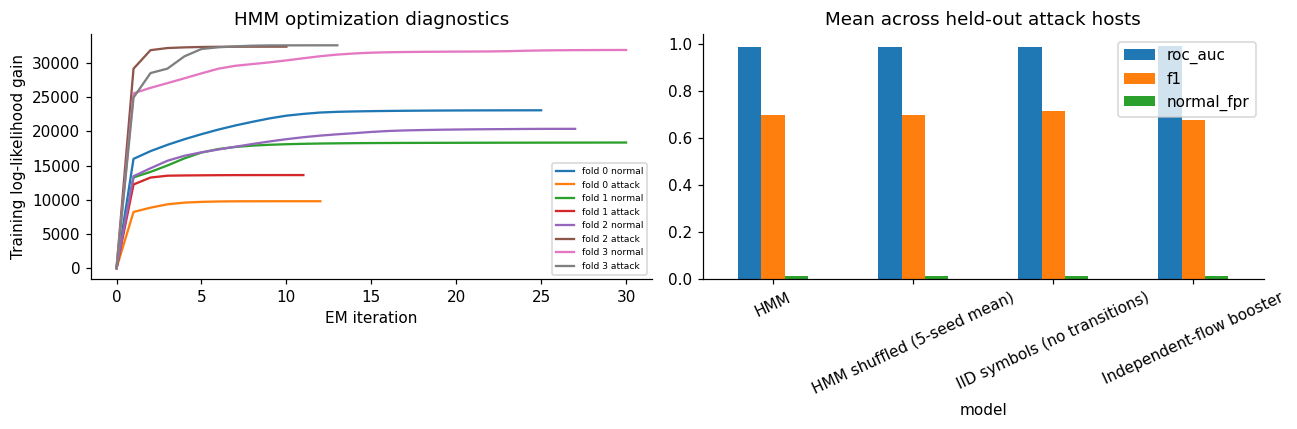

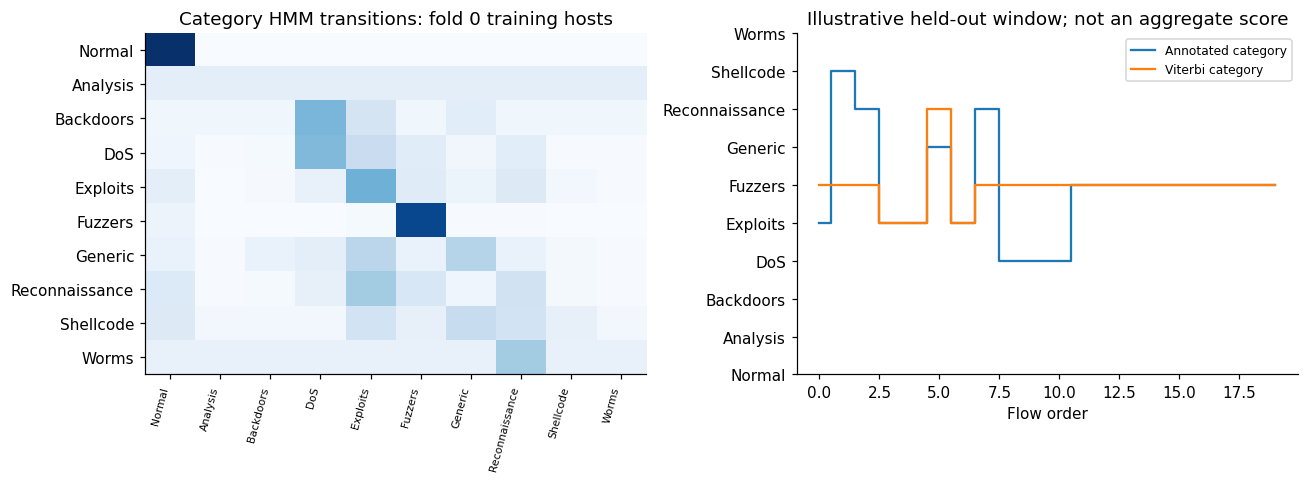

The illustrated window was chosen to contain many distinct attack categories. It is not proof of a linked campaign.


,Normal,Analysis,Backdoors,DoS,Exploits,Fuzzers,Generic,Reconnaissance,Shellcode,Worms
Normal,636155,8,0,11,84,116,8,23,3,0
Analysis,7,53,427,1,4,4,0,1,0,0
Backdoors,0,4,4,6,445,4,2,0,0,0
DoS,11,5,2,69,474,25,6,16,0,0
Exploits,80,18,7,464,363,517,58,81,14,1
Fuzzers,161,406,13,23,76,3858,28,34,3,1
Generic,8,0,7,11,57,25,6534,35,3,0
Reconnaissance,28,2,1,16,84,47,30,43,3,0
Shellcode,3,0,0,2,7,3,7,5,1,0
Worms,0,0,0,0,0,1,0,2,0,0


Counts show adjacent categories within windows; repeated categories and coincident activities are not necessarily attack stages.
{'hmm_auc': 0.988, 'shuffled_auc': 0.988, 'no_transition_auc': 0.9881, 'flow_baseline_auc': 0.9939, 'category_hmm_macro_f1': 0.1775, 'category_emission_only_macro_f1': 0.1244, 'hmm_minus_shuffled_auc': 0.0, 'hmm_minus_no_transition_auc': -0.0001, 'category_folds_hmm_better': 4}


In [13]:
sequence_results = stage_results = order_effect = None
if not UNSW_AVAILABLE:
    print('SKIPPED: UNSW-NB15_1.csv is not available.')
else:
    def binary_summary(truth, score, threshold):
        truth = np.asarray(truth, dtype=int)
        predicted = np.asarray(score) >= threshold
        p, r, f, _ = precision_recall_fscore_support(truth, predicted, average='binary', zero_division=0)
        return dict(precision=float(p), recall=float(r), f1=float(f),
            accuracy=float(accuracy_score(truth, predicted)),
            normal_fpr=float(predicted[truth == 0].mean()),
            roc_auc=float(roc_auc_score(truth, score)), average_precision=float(average_precision_score(truth, score)),
            support=len(truth), attack_windows=int(truth.sum()), threshold=float(threshold))

    def validation_threshold(truth, score, max_fpr=.05):
        truth = np.asarray(truth, dtype=int)
        score = np.asarray(score)
        assert set(np.unique(truth)) == {0, 1}
        candidates = np.unique(np.r_[np.quantile(score, np.linspace(0, 1, 151)), np.nextafter(score.max(), np.inf)])
        candidates_metrics = [(float(f1_score(truth, score >= threshold, zero_division=0)),
                               float(np.mean(score[truth == 0] >= threshold)), float(threshold))
                              for threshold in candidates]
        eligible = [item for item in candidates_metrics if item[1] <= max_fpr]
        return max(eligible, key=lambda item: (item[0], -item[1], item[2]))[2]

    def shuffle_observations(observations, seed):
        rng = np.random.default_rng(seed)
        permutation = np.argsort(rng.random(observations.shape), axis=1)
        return np.take_along_axis(observations, permutation, axis=1)

    assert len(attack_hosts) >= 3, 'At least three attack source hosts are required for disjoint host partitions.'
    benign_order = np.random.default_rng(SEED).permutation(benign_hosts)
    benign_groups = np.array_split(benign_order, len(attack_hosts))
    sequence_rows, stage_rows, fold_audits, sequence_predictions, hmm_histories = [], [], [], [], []
    transition_counts = np.zeros((len(UNSW_FAMILIES), len(UNSW_FAMILIES)), dtype=np.int64)
    for sequence in window_states:
        np.add.at(transition_counts, (sequence[:-1], sequence[1:]), 1)

    for fold, held_out_host in enumerate(attack_hosts):
        validation_host = attack_hosts[(fold + 1) % len(attack_hosts)]
        test_hosts = set(benign_groups[fold]) | {held_out_host}
        validation_hosts = set(benign_groups[(fold + 1) % len(attack_hosts)]) | {validation_host}
        training_hosts = set(usable_hosts) - test_hosts - validation_hosts
        assert training_hosts.isdisjoint(test_hosts | validation_hosts)
        assert test_hosts.isdisjoint(validation_hosts)
        tr_w = np.flatnonzero(np.isin(window_hosts, list(training_hosts)))
        va_w = np.flatnonzero(np.isin(window_hosts, list(validation_hosts)))
        te_w = np.flatnonzero(np.isin(window_hosts, list(test_hosts)))
        for ids in [tr_w, va_w, te_w]:
            assert set(window_attack[ids]) == {0, 1}
        rng = np.random.default_rng(SEED + fold)
        train_flows = windows[tr_w].ravel()
        fit_flows = rng.choice(train_flows, size=min(60000, len(train_flows)), replace=False)
        symbol_scaler = StandardScaler().fit(unsw_X[fit_flows])
        symbol_cluster = MiniBatchKMeans(n_clusters=HMM_SYMBOLS, batch_size=4096, n_init=3, random_state=SEED + fold)
        symbol_cluster.fit(symbol_scaler.transform(unsw_X[fit_flows]))
        symbols = symbol_cluster.predict(symbol_scaler.transform(unsw_X))
        observations = symbols[windows]
        sampled_training = {}
        for label in [0, 1]:
            ids = tr_w[window_attack[tr_w] == label]
            sampled_training[label] = rng.choice(ids, size=min(MAX_HMM_SEQUENCES_PER_CLASS, len(ids)), replace=False)
        normal_hmm = best_hmm(observations[sampled_training[0]], HMM_STATES, HMM_SYMBOLS, SEED + 10 * fold)
        attack_hmm = best_hmm(observations[sampled_training[1]], HMM_STATES, HMM_SYMBOLS, SEED + 10 * fold + 1)
        def hmm_score(ids, obs=observations):
            return (attack_hmm.score(obs[ids]) - normal_hmm.score(obs[ids])) / SEQUENCE_LENGTH
        hmm_validation = hmm_score(va_w)
        hmm_test = hmm_score(te_w)
        threshold = validation_threshold(window_attack[va_w], hmm_validation)
        row = binary_summary(window_attack[te_w], hmm_test, threshold)
        row.update(fold=fold, model='HMM', test_attack_host=held_out_host)
        sequence_rows.append(row)
        sequence_predictions.append(pd.DataFrame(dict(fold=fold, window_id=te_w,
            truth=window_attack[te_w], score=hmm_test, threshold=threshold, prediction=(hmm_test >= threshold).astype(int))))
        shuffle_metrics = []
        for shuffle_seed in [42, 43, 44, 45, 46]:
            shuffled = shuffle_observations(observations[te_w], shuffle_seed)
            score = (attack_hmm.score(shuffled) - normal_hmm.score(shuffled)) / SEQUENCE_LENGTH
            metrics = binary_summary(window_attack[te_w], score, threshold)
            shuffle_metrics.append(metrics)
        shuffled_row = {key: float(np.mean([item[key] for item in shuffle_metrics])) for key in shuffle_metrics[0]}
        shuffled_row.update(fold=fold, model='HMM shuffled (5-seed mean)', test_attack_host=held_out_host)
        sequence_rows.append(shuffled_row)

        iid_distributions = {}
        for label in [0, 1]:
            counts = np.bincount(observations[sampled_training[label]].ravel(), minlength=HMM_SYMBOLS) + 1
            iid_distributions[label] = counts / counts.sum()
        log_ratio = np.log(iid_distributions[1]) - np.log(iid_distributions[0])
        iid_validation = log_ratio[observations[va_w]].mean(axis=1)
        iid_test = log_ratio[observations[te_w]].mean(axis=1)
        assert np.allclose(iid_test, log_ratio[shuffle_observations(observations[te_w], 42)].mean(axis=1))
        iid_threshold = validation_threshold(window_attack[va_w], iid_validation)
        iid_row = binary_summary(window_attack[te_w], iid_test, iid_threshold)
        iid_row.update(fold=fold, model='IID symbols (no transitions)', test_attack_host=held_out_host)
        sequence_rows.append(iid_row)

        flow_model = HistGradientBoostingClassifier(max_iter=120, max_leaf_nodes=15, learning_rate=.08,
                        class_weight='balanced', random_state=SEED + fold)
        flow_model.fit(unsw_X[fit_flows], raw.label.to_numpy()[fit_flows])
        flow_va = flow_model.predict_proba(unsw_X[windows[va_w].ravel()])[:, 1].reshape(-1, SEQUENCE_LENGTH).max(axis=1)
        flow_te = flow_model.predict_proba(unsw_X[windows[te_w].ravel()])[:, 1].reshape(-1, SEQUENCE_LENGTH).max(axis=1)
        flow_threshold = validation_threshold(window_attack[va_w], flow_va)
        flow_row = binary_summary(window_attack[te_w], flow_te, flow_threshold)
        flow_row.update(fold=fold, model='Independent-flow booster', test_attack_host=held_out_host)
        sequence_rows.append(flow_row)

        stage_hmm = CategoricalSequenceHMM(len(UNSW_FAMILIES), HMM_SYMBOLS, smoothing=.5)
        stage_hmm.fit_supervised(observations[tr_w], window_states[tr_w])
        decoded = stage_hmm.decode(observations[te_w])
        emission = stage_hmm.emission_only(observations[te_w])
        for name, prediction in [('Category HMM', decoded), ('Category emission-only', emission)]:
            stage_rows.append(dict(fold=fold, model=name,
                accuracy=float(accuracy_score(window_states[te_w].ravel(), prediction.ravel())),
                macro_f1=float(f1_score(window_states[te_w].ravel(), prediction.ravel(),
                                      labels=np.arange(len(UNSW_FAMILIES)), average='macro', zero_division=0))))
        audit = dict(fold=fold, train_hosts=sorted(training_hosts), validation_hosts=sorted(validation_hosts),
            test_hosts=sorted(test_hosts), train_windows=len(tr_w), validation_windows=len(va_w), test_windows=len(te_w),
            em_normal_windows=len(sampled_training[0]), em_attack_windows=len(sampled_training[1]),
            normal_hmm_converged=normal_hmm.converged_, attack_hmm_converged=attack_hmm.converged_,
            normal_iterations=normal_hmm.iterations_, attack_iterations=attack_hmm.iterations_)
        fold_audits.append(audit)
        hmm_histories.append(dict(fold=fold, normal=normal_hmm.history_, attack=attack_hmm.history_))
        if fold == 0:
            first_fold_stage_transition = stage_hmm.transition_.copy()
            sample_local = max(range(len(te_w)), key=lambda i: len(set(window_states[te_w[i]]) - {0}))
            sample_true = window_states[te_w[sample_local]].copy()
            sample_decoded = decoded[sample_local].copy()
        print(f'Fold {fold + 1}/{len(attack_hosts)}: HMM AUC {row["roc_auc"]:.3f}, F1 {row["f1"]:.3f}, '
              f'Normal FPR {row["normal_fpr"]:.3f}; flow AUC {flow_row["roc_auc"]:.3f}', flush=True)

    sequence_results = pd.DataFrame(sequence_rows)
    stage_results = pd.DataFrame(stage_rows)
    display(sequence_results[['fold', 'model', 'support', 'attack_windows', 'roc_auc', 'average_precision',
                              'precision', 'recall', 'f1', 'normal_fpr']].round(4))
    sequence_mean = sequence_results.groupby('model')[['roc_auc', 'average_precision', 'precision', 'recall', 'f1', 'normal_fpr']].agg(['mean', 'std'])
    display(sequence_mean.round(4)); display(stage_results.round(4))
    display(pd.DataFrame(fold_audits).drop(columns=['train_hosts', 'validation_hosts', 'test_hosts']))
    sequence_predictions = pd.concat(sequence_predictions, ignore_index=True)
    assert sequence_predictions.window_id.nunique() == len(windows)
    assert len(sequence_predictions) == len(windows)
    print('Every retained window was evaluated exactly once on held-out source hosts.')

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for record in hmm_histories:
        for label in ['normal', 'attack']:
            history = np.asarray(record[label])
            axes[0].plot(history - history[0], label=f'fold {record["fold"]} {label}')
    axes[0].set(xlabel='EM iteration', ylabel='Training log-likelihood gain', title='HMM optimization diagnostics')
    axes[0].legend(fontsize=6)
    means = sequence_results.groupby('model')[['roc_auc', 'f1', 'normal_fpr']].mean()
    means.plot.bar(ax=axes[1], rot=25)
    axes[1].set_title('Mean across held-out attack hosts')
    plt.tight_layout(); plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].imshow(first_fold_stage_transition, cmap='Blues', aspect='auto', vmin=0, vmax=1)
    axes[0].set(xticks=range(len(UNSW_FAMILIES)), yticks=range(len(UNSW_FAMILIES)),
                yticklabels=UNSW_FAMILIES, title='Category HMM transitions: fold 0 training hosts')
    axes[0].set_xticklabels(UNSW_FAMILIES, rotation=75, ha='right', fontsize=7)
    axes[1].step(range(SEQUENCE_LENGTH), sample_true, where='mid', label='Annotated category')
    axes[1].step(range(SEQUENCE_LENGTH), sample_decoded, where='mid', label='Viterbi category')
    axes[1].set(yticks=range(len(UNSW_FAMILIES)), yticklabels=UNSW_FAMILIES,
                xlabel='Flow order', title='Illustrative held-out window; not an aggregate score')
    axes[1].legend(fontsize=8)
    plt.tight_layout(); plt.show()
    print('The illustrated window was chosen to contain many distinct attack categories. It is not proof of a linked campaign.')

    transition_table = pd.DataFrame(transition_counts, index=UNSW_FAMILIES, columns=UNSW_FAMILIES)
    display(transition_table)
    print('Counts show adjacent categories within windows; repeated categories and coincident activities are not necessarily attack stages.')
    hmm_means = sequence_results.groupby('model')[['roc_auc', 'average_precision', 'f1']].mean()
    order_effect = dict(
        hmm_auc=float(hmm_means.loc['HMM', 'roc_auc']),
        shuffled_auc=float(hmm_means.loc['HMM shuffled (5-seed mean)', 'roc_auc']),
        no_transition_auc=float(hmm_means.loc['IID symbols (no transitions)', 'roc_auc']),
        flow_baseline_auc=float(hmm_means.loc['Independent-flow booster', 'roc_auc']),
        category_hmm_macro_f1=float(stage_results[stage_results.model == 'Category HMM'].macro_f1.mean()),
        category_emission_only_macro_f1=float(stage_results[stage_results.model == 'Category emission-only'].macro_f1.mean()),
    )
    order_effect['hmm_minus_shuffled_auc'] = order_effect['hmm_auc'] - order_effect['shuffled_auc']
    order_effect['hmm_minus_no_transition_auc'] = order_effect['hmm_auc'] - order_effect['no_transition_auc']
    order_effect['category_folds_hmm_better'] = int((
        stage_results[stage_results.model == 'Category HMM'].macro_f1.to_numpy()
        > stage_results[stage_results.model == 'Category emission-only'].macro_f1.to_numpy()).sum())
    print({k: round(v, 4) if isinstance(v, float) else v for k, v in order_effect.items()})

## 10. Controlled multi-stage demonstration (simulated)

**SIMULATED SEQUENCES — not real sessions.** To test whether the HMM can exploit stage order when it genuinely exists, sequences are constructed with a known kill chain: Normal → Probe → R2L → U2R, with random stage lengths; half the sequences stay Normal throughout. Each step is a real NSL-KDD record of that family, represented by its §6 cluster id. Training chains use `KDDTrain+` records; test chains use `KDDTest+` records only. Rare records are reused, so prevalence is artificial.

A supervised HMM decodes the stage of every step. It is compared with an emission-only classifier (each step judged alone) and with the same HMM on sequences whose order has been shuffled. A clear gap between ordered and shuffled decoding means the HMM is using stage order.

,experiment,model,accuracy,macro_f1,simulated_R2L_recall,simulated_U2R_recall
0,SIMULATED,HMM ordered,0.8702,0.7223,0.1764,0.8196
1,SIMULATED,Emission only,0.7035,0.4510,0.1610,0.0000
2,SIMULATED,HMM shuffled,0.6410,0.2695,0.0188,0.0154


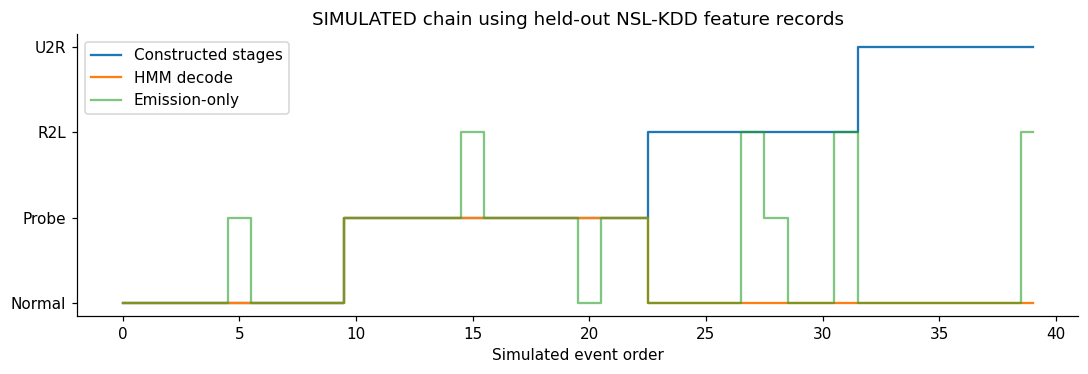

{'HMM ordered': 0.8702, 'Emission only': 0.7035, 'HMM shuffled': 0.641}


In [14]:
SIMULATED_STAGES = ['Normal', 'Probe', 'R2L', 'U2R']
def simulated_sequences(labels, symbols, available, count, seed):
    rng = np.random.default_rng(seed)
    pools = {label: available[np.asarray(labels)[available] == label] for label in SIMULATED_STAGES}
    observation_rows, state_rows = [], []
    for i in range(count):
        if i % 2 == 0:
            states = np.zeros(40, dtype=np.int64)
        else:
            durations = 5 + rng.multinomial(20, np.full(4, .25))
            states = np.repeat(np.arange(4), durations)
        sampled_rows = np.array([rng.choice(pools[SIMULATED_STAGES[state]]) for state in states])
        observation_rows.append(symbols[sampled_rows])
        state_rows.append(states)
    return np.asarray(observation_rows), np.asarray(state_rows)

sim_train_x, sim_train_y = simulated_sequences(ytr, cluster_tr, np.arange(len(train)), 300, SEED)
sim_test_x, sim_test_y = simulated_sequences(yte, cluster_te, np.arange(len(test)), 300, SEED + 1)
sim_hmm = CategoricalSequenceHMM(4, chosen_k, smoothing=.1).fit_supervised(sim_train_x, sim_train_y)
sim_pred = sim_hmm.decode(sim_test_x)
sim_emission = sim_hmm.emission_only(sim_test_x)
permutation = np.argsort(np.random.default_rng(SEED).random(sim_test_x.shape), axis=1)
sim_shuffled_x = np.take_along_axis(sim_test_x, permutation, axis=1)
sim_shuffled_y = np.take_along_axis(sim_test_y, permutation, axis=1)
sim_shuffled_pred = sim_hmm.decode(sim_shuffled_x)
simulation_rows = []
for name, truth, prediction in [('HMM ordered', sim_test_y, sim_pred),
                               ('Emission only', sim_test_y, sim_emission),
                               ('HMM shuffled', sim_shuffled_y, sim_shuffled_pred)]:
    _, recall, _, _ = precision_recall_fscore_support(truth.ravel(), prediction.ravel(), labels=range(4), zero_division=0)
    simulation_rows.append(dict(experiment='SIMULATED', model=name,
        accuracy=float(accuracy_score(truth.ravel(), prediction.ravel())),
        macro_f1=float(f1_score(truth.ravel(), prediction.ravel(), average='macro')),
        simulated_R2L_recall=float(recall[2]), simulated_U2R_recall=float(recall[3])))
simulation_results = pd.DataFrame(simulation_rows)
display(simulation_results.round(4))
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.step(range(40), sim_test_y[1], where='mid', label='Constructed stages')
ax.step(range(40), sim_pred[1], where='mid', label='HMM decode')
ax.step(range(40), sim_emission[1], where='mid', label='Emission-only', alpha=.6)
ax.set(yticks=range(4), yticklabels=SIMULATED_STAGES, xlabel='Simulated event order',
       title='SIMULATED chain using held-out NSL-KDD feature records')
ax.legend(); plt.tight_layout(); plt.show()
SIMULATION = dict(zip(simulation_results.model, simulation_results.accuracy))
print({k: round(v, 4) for k, v in SIMULATION.items()})

## 11. Unified schema across datasets: cross-dataset generalisation

To integrate the two public datasets in one analytical pipeline, both are mapped to the fields they share: duration, source bytes, destination bytes, transport protocol and service (common services kept, the rest grouped as `other`), with a binary attack/normal label. A class-weighted gradient booster is trained on one dataset and tested on the other, alongside an in-domain reference and a majority-class baseline. Because UNSW-NB15 is about 97% normal traffic, balanced accuracy, attack recall and false-alarm rate are reported rather than plain accuracy alone.

This asks a deployment question: does a detector trained on one network's traffic transfer to another network?

In [15]:
from sklearn.metrics import balanced_accuracy_score

transfer_table = None
if not UNSW_AVAILABLE:
    print('SKIPPED: UNSW-NB15_1.csv is not available.')
else:
    SHARED_SERVICES = ['http', 'ftp', 'ftp_data', 'smtp', 'domain_u', 'ssh', 'pop_3', 'IRC']
    UNSW_SERVICE_MAP = {'http': 'http', 'ftp': 'ftp', 'ftp-data': 'ftp_data', 'smtp': 'smtp',
                        'dns': 'domain_u', 'ssh': 'ssh', 'pop3': 'pop_3', 'irc': 'IRC'}

    def shared_matrix(duration, src, dst, proto, service):
        proto = pd.Series(proto).astype(str).str.lower().to_numpy()
        service = pd.Series(service).astype(str).to_numpy()
        blocks = [np.log1p(np.column_stack([duration, src, dst]).astype(np.float64))]
        blocks.append(np.column_stack([proto == p for p in ['tcp', 'udp', 'icmp']] + [~np.isin(proto, ['tcp', 'udp', 'icmp'])]))
        blocks.append(np.column_stack([service == s for s in SHARED_SERVICES] + [~np.isin(service, SHARED_SERVICES)]))
        return np.column_stack(blocks).astype(np.float32)

    def nsl_shared(frame):
        return shared_matrix(frame.duration, frame.src_bytes, frame.dst_bytes, frame.protocol_type, frame.service)

    unsw_service = raw.service.astype(str).str.strip().map(UNSW_SERVICE_MAP).fillna('other')
    unsw_shared = shared_matrix(raw.dur, raw.sbytes, raw.dbytes, raw.proto, unsw_service)
    unsw_label = raw.label.to_numpy().astype(bool)
    nsl_tr_shared, nsl_te_shared = nsl_shared(train), nsl_shared(test)
    nsl_tr_label, nsl_te_label = ytr != 'Normal', yte != 'Normal'
    u_fit, u_eval = train_test_split(np.arange(len(raw)), test_size=0.3, stratify=unsw_label, random_state=SEED)

    def shared_model(matrix, labels):
        return HistGradientBoostingClassifier(class_weight='balanced', max_iter=200, learning_rate=0.08,
                                              random_state=SEED).fit(matrix, labels)

    def transfer_row(direction, model, matrix, truth, train_labels):
        predicted = model.predict(matrix)
        return dict(direction=direction, accuracy=accuracy_score(truth, predicted),
                    balanced_accuracy=balanced_accuracy_score(truth, predicted),
                    attack_recall=float(np.mean(predicted[truth])), normal_fpr=float(np.mean(predicted[~truth])),
                    test_rows=len(truth))

    nsl_model = shared_model(nsl_tr_shared, nsl_tr_label)
    unsw_model = shared_model(unsw_shared[u_fit], unsw_label[u_fit])
    transfer_table = pd.DataFrame([
        transfer_row('NSL-KDD → NSL-KDD test (in-domain reference)', nsl_model, nsl_te_shared, nsl_te_label, nsl_tr_label),
        transfer_row('NSL-KDD → UNSW-NB15 (cross-dataset)', nsl_model, unsw_shared[u_eval], unsw_label[u_eval], nsl_tr_label),
        transfer_row('UNSW-NB15 → UNSW-NB15 held-out (in-domain reference)', unsw_model, unsw_shared[u_eval], unsw_label[u_eval], unsw_label[u_fit]),
        transfer_row('UNSW-NB15 → NSL-KDD test (cross-dataset)', unsw_model, nsl_te_shared, nsl_te_label, unsw_label[u_fit]),
    ])
    display(transfer_table.round(4))
    print('Balanced accuracy of 0.5 is what always predicting one class would score; values near 0.5 mean no transfer.')

,direction,accuracy,balanced_accuracy,attack_recall,normal_fpr,test_rows
0,NSL-KDD → NSL-KDD test (in-domain reference),0.8255,0.8421,0.7221,0.0379,22544
1,NSL-KDD → UNSW-NB15 (cross-dataset),0.9026,0.4965,0.0629,0.0699,210001
2,UNSW-NB15 → UNSW-NB15 held-out (in-domain refe...,0.9910,0.9919,0.9928,0.0091,210001
3,UNSW-NB15 → NSL-KDD test (cross-dataset),0.4872,0.5388,0.1664,0.0889,22544


Balanced accuracy of 0.5 is what always predicting one class would score; values near 0.5 mean no transfer.


## 12. Risk classification, decision support and throughput

Each connection receives a risk tier from a documented policy: **Normal → Low, Probe → Medium, DoS → High, R2L/U2R → Critical, Unknown attack → High** (pending investigation). R2L and U2R are Critical because they mean unauthorised access to, or control of, a host; Probe is reconnaissance; DoS disrupts service. These tiers are an operational rule for prioritising analyst review, not a dataset label.

`classify_connections` is the end-to-end scorer: raw connection records in, family + risk tier + scores out. It is timed on batches of already-extracted records. This measures the model's own throughput; it excludes packet capture and flow extraction, so it supports but does not prove real-time deployment.

In [16]:
RISK_POLICY = {'Normal': 'Low', 'Probe': 'Medium', 'DoS': 'High',
               'R2L': 'Critical', 'U2R': 'Critical', 'Unknown attack': 'High'}
RISK_ORDER = ['Low', 'Medium', 'High', 'Critical']


def classify_connections(connection_frame):
    features = engineer(connection_frame)
    scores = primary_scores_for(encode_matrix(features, numeric_cols, cat_levels))
    predicted = to_family(scores).astype(object)
    anomaly_score = scorers[SELECTED_DETECTOR](
        traffic_scaler.transform(traffic_space(features)).astype(np.float32))
    predicted[(predicted == 'Normal') & (anomaly_score > thresholds[SELECTED_DETECTOR])] = 'Unknown attack'
    return pd.DataFrame({'predicted_family': predicted,
                         'risk_tier': [RISK_POLICY[label] for label in predicted],
                         'attack_probability': 1 - scores[:, 0],
                         'anomaly_score': anomaly_score}, index=connection_frame.index)


risk_output = classify_connections(test[COLUMNS])
assert np.array_equal(risk_output.predicted_family.to_numpy(), hybrid_prediction)
risk_table = pd.crosstab(pd.Series(yte, name='true family'),
                         pd.Categorical(risk_output.risk_tier, categories=RISK_ORDER, ordered=True)
                         ).reindex(index=CLASSES)
risk_table.columns.name = 'assigned risk tier'
print('Risk tiers assigned on the official test set:')
display(risk_table)
critical_or_high = risk_output.risk_tier.isin(['High', 'Critical']).to_numpy()
RISK_SUMMARY = dict(
    attacks_in_high_or_critical=float(np.mean(critical_or_high[yte != 'Normal'])),
    normal_in_high_or_critical=float(np.mean(critical_or_high[yte == 'Normal'])),
    r2l_u2r_reaching_review=float(np.mean(risk_output.risk_tier.to_numpy()[np.isin(yte, ['R2L', 'U2R'])] != 'Low')),
)
print({k: round(v, 4) for k, v in RISK_SUMMARY.items()})

batch = test[COLUMNS].iloc[:5000]
classify_connections(batch)
timings = []
for _ in range(5):
    start = time.perf_counter()
    classify_connections(batch)
    timings.append(time.perf_counter() - start)
LATENCY = dict(batch_size=len(batch), median_batch_seconds=float(np.median(timings)),
               ms_per_connection=float(1000 * np.median(timings) / len(batch)),
               connections_per_second=float(len(batch) / np.median(timings)))
print('Offline throughput:', {k: round(v, 4) for k, v in LATENCY.items()})
display(risk_output.head(10))

Risk tiers assigned on the official test set:


assigned risk tier,Low,Medium,High,Critical
true family,,,,
Normal,9303,217,181,10
DoS,709,176,6573,2
Probe,257,1971,193,0
R2L,1589,40,445,811
U2R,14,1,22,30


{'attacks_in_high_or_critical': 0.6293, 'normal_in_high_or_critical': 0.0197, 'r2l_u2r_reaching_review': 0.457}


Offline throughput: {'batch_size': 5000, 'median_batch_seconds': 0.0259, 'ms_per_connection': 0.0052, 'connections_per_second': 193279.3074}


,predicted_family,risk_tier,attack_probability,anomaly_score
0,DoS,High,0.998159,5.109796
1,DoS,High,0.998160,5.341410
2,Normal,Low,0.006714,3.007440
3,Probe,Medium,0.984931,6.211475
4,Probe,Medium,0.653414,3.540233
5,Normal,Low,0.006635,1.168557
6,Normal,Low,0.049425,5.268358
7,Unknown attack,High,0.304857,27.354273
8,Normal,Low,0.006641,1.051059
9,Unknown attack,High,0.495595,28.732069


## 12A. Anomaly-first detection on NSL-KDD (primary goal)

The real goal of an intrusion detector is to catch attacks it has **never seen**. A classifier can only name attacks that look like its training data, so here detection comes first and naming comes second.

**Step 1: is this connection Not normal?** Three detectors learn only from Normal training traffic, so they need no attack labels:
- **Isolation Forest** and **centroid distance**: the two detectors from §7.
- **kNN distance** (new): the average distance to the 5 closest Normal connections in a reference sample of 20,000 training Normal rows. A connection unlike any normal one is far from all of them.

Each raw score is turned into a **normal percentile** using training Normal rows held out from fitting (0.97 means "more unusual than 97% of normal traffic"), so the scores are comparable and can be averaged (**Mean of three**).

**Step 2: anomaly OR classifier.** A connection is Not normal if the classifier already calls it an attack, *or* its anomaly percentile is high. One threshold on held-out training Normal sets the total false-alarm budget: **2%, 5% and 10%** are reported; 5% (declared in §7) is the main operating point.

**Step 3: name it, or say Unknown.** For an alert, the classifier names the family only if it is confident (top probability at or above a cutoff). Otherwise the output is **`Unknown attack`**, which the §12 policy treats as High risk.

**No test leakage.** The anomaly score, the naming cutoff and every threshold are chosen on `KDDTrain+` only: the score and cutoff on the leave-attack-type-out folds of §4 (validation attacks are always techniques the fold never trained on), the thresholds on held-out training Normal. `KDDTest+` is scored once, at the end, for reporting. Because the budget is set on *training* Normal, the false-alarm rate on *test* Normal is reported separately; it can be higher if test Normal traffic looks different.

In [17]:
from sklearn.neighbors import NearestNeighbors

FA_BUDGETS = [0.02, 0.05, 0.10]          # false-alarm budgets, fixed before testing
KNN_REFERENCE = 20000                    # Normal rows kept as the kNN reference set
ATTACK_FAMILIES = ['DoS', 'Probe', 'R2L', 'U2R']
SINGLE_DETECTORS = DETECTORS + ['kNN distance']
ANOMALY_CANDIDATES = SINGLE_DETECTORS + ['Mean of three']


def fit_anomaly_scorers(normal_space, seed):
    """The two §7 detectors plus a kNN distance; all are fitted on Normal rows only."""
    scorers_ = fit_detectors(normal_space, seed)
    reference = normal_space[np.random.default_rng(seed).choice(
        len(normal_space), min(KNN_REFERENCE, len(normal_space)), replace=False)]
    knn = NearestNeighbors(n_neighbors=5, n_jobs=CPU_THREADS).fit(reference)
    scorers_['kNN distance'] = lambda Z: knn.kneighbors(Z)[0].mean(axis=1)
    return scorers_


def normal_percentile(reference, values):
    """Share of held-out Normal scores at or below each value (0 = very normal, 1 = beyond all Normal)."""
    return np.searchsorted(np.sort(reference), values, side='right') / len(reference)


def anomaly_percentiles(scorers_, Z_reference, Z_target):
    """For each candidate: (percentiles of the reference Normal rows, percentiles of the target rows)."""
    out = {}
    for name in SINGLE_DETECTORS:
        ref = scorers_[name](Z_reference)
        out[name] = (normal_percentile(ref, ref), normal_percentile(ref, scorers_[name](Z_target)))
    out['Mean of three'] = tuple(np.mean([out[n][i] for n in SINGLE_DETECTORS], axis=0) for i in (0, 1))
    return out


def fuse_with_classifier(anomaly_ref, anomaly_target, alarm_ref, alarm_target):
    """Anomaly-first fusion: a connection is Not normal if the classifier already calls it an attack
    OR its anomaly percentile is high. Classifier alarms are ranked above every anomaly score (1 + score),
    so one threshold on held-out Normal sets the false-alarm budget for the combined system."""
    return (np.where(alarm_ref, 1 + anomaly_ref, anomaly_ref),
            np.where(alarm_target, 1 + anomaly_target, anomaly_target))


def budget_threshold(reference_scores, budget):
    return float(np.quantile(reference_scores, 1 - budget))


def detection_rates(truth, alerts, unseen=None):
    truth = np.asarray(truth)
    attack = truth != 'Normal'
    p, r, f, _ = precision_recall_fscore_support(attack, alerts, average='binary', zero_division=0)
    row = dict(attack_detection=float(r), precision=float(p), f1=float(f),
               normal_fpr=float(np.mean(alerts[~attack])), binary_accuracy=float(np.mean(alerts == attack)))
    if unseen is not None:
        row['unseen_technique_detection'] = float(np.mean(alerts[unseen]))
    for fam in ATTACK_FAMILIES:
        row[f'{fam}_detection'] = float(np.mean(alerts[truth == fam]))
    return row


oof_family = to_family(oof_scores[SELECTED_NAME])          # out-of-fold classifier decisions

# --- 1. choose the anomaly score on leave-attack-type-out folds (validation attacks are unseen techniques) ---
af_choice_rows, af_fold_cache = [], []
for f in range(FOLDS):
    fit_rows, val_rows = np.flatnonzero(fold_id != f), np.flatnonzero(fold_id == f)
    nf, nh = split_normal(fit_rows[ytr[fit_rows] == 'Normal'], SEED + f)
    pct = anomaly_percentiles(fit_anomaly_scorers(Ztr[nf], SEED + f), Ztr[nh], Ztr[val_rows])
    af_fold_cache.append((val_rows, nh, pct))
    for name in ANOMALY_CANDIDATES:
        for budget in FA_BUDGETS:
            alerts = pct[name][1] > budget_threshold(pct[name][0], budget)
            row = detection_rates(ytr[val_rows], alerts)
            af_choice_rows.append(dict(score=name, fold=f, budget=budget, **row))
    print(f'fold {f + 1}/{FOLDS}: classifier false alarms on held-out Normal {np.mean(oof_family[nh] != "Normal"):.4f}')
af_choice = (pd.DataFrame(af_choice_rows).groupby(['score', 'budget'])
             [['attack_detection', 'normal_fpr', 'R2L_detection', 'U2R_detection']].mean().unstack('budget'))
AF_SCORE = af_choice['attack_detection'].mean(axis=1).idxmax()
print('Normal-only scores on unseen-technique validation folds (mean of 3 folds):')
display(af_choice.round(4))
print('FROZEN ANOMALY SCORE:', AF_SCORE)

# --- 2. choose the "name it or call it Unknown" cutoff on the same folds (5% budget, fused system) ---
CUTOFF_GRID = np.round(np.arange(0.40, 0.96, 0.05), 2)
oof_confidence = oof_scores[SELECTED_NAME].max(axis=1)
cutoff_rows = []
for val_rows, nh, pct in af_fold_cache:
    fused_ref, fused_val = fuse_with_classifier(pct[AF_SCORE][0], pct[AF_SCORE][1],
                                                oof_family[nh] != 'Normal', oof_family[val_rows] != 'Normal')
    alerts = fused_val > budget_threshold(fused_ref, 0.05)
    named = alerts & (oof_family[val_rows] != 'Normal') & (ytr[val_rows] != 'Normal')
    for cutoff in CUTOFF_GRID:
        keep = named & (oof_confidence[val_rows] >= cutoff)
        right = int((oof_family[val_rows][keep] == ytr[val_rows][keep]).sum())
        cutoff_rows.append(dict(cutoff=cutoff, right=right, wrong=int(keep.sum()) - right))
cutoff_table = pd.DataFrame(cutoff_rows).groupby('cutoff').sum()
cutoff_table['net'] = cutoff_table.right - cutoff_table.wrong
UNKNOWN_CUTOFF = float(cutoff_table.net.idxmax())
print('FROZEN NAMING CUTOFF (classifier confidence needed to name a family):', UNKNOWN_CUTOFF)

# --- 3. final detectors: fitted on training Normal, thresholds from held-out training Normal ---
af_fit, af_hold = split_normal(np.flatnonzero(ytr == 'Normal'), SEED)
af_pct = anomaly_percentiles(fit_anomaly_scorers(Ztr[af_fit], SEED), Ztr[af_hold], Zte)
anomaly_ref, anomaly_test = af_pct[AF_SCORE]
fused_ref, fused_test = fuse_with_classifier(anomaly_ref, anomaly_test,
                                             oof_family[af_hold] != 'Normal', primary_prediction != 'Normal')
AF_THRESHOLDS = {b: dict(anomaly=budget_threshold(anomaly_ref, b), fused=budget_threshold(fused_ref, b))
                 for b in FA_BUDGETS}

score_quality = pd.DataFrame([dict(score=name, roc_auc=roc_auc_score(yte != 'Normal', af_pct[name][1]),
                                   pr_auc=average_precision_score(yte != 'Normal', af_pct[name][1]),
                                   unseen_vs_normal_auc=roc_auc_score(novel_mask[novel_mask | (yte == 'Normal')],
                                                                      af_pct[name][1][novel_mask | (yte == 'Normal')]))
                              for name in ANOMALY_CANDIDATES]
                             + [dict(score='Anomaly-first fused score', roc_auc=roc_auc_score(yte != 'Normal', fused_test),
                                     pr_auc=average_precision_score(yte != 'Normal', fused_test),
                                     unseen_vs_normal_auc=roc_auc_score(novel_mask[novel_mask | (yte == 'Normal')],
                                                                        fused_test[novel_mask | (yte == 'Normal')]))])
print('Ranking quality on KDDTest+ (the official test set is used here once):')
display(score_quality.round(4))

operating_rows = [dict(system='Classifier alone (§5)', budget=np.nan,
                       **detection_rates(yte, primary_prediction != 'Normal', novel_mask)),
                  dict(system='Hybrid (§7, selected)', budget=0.05,
                       **detection_rates(yte, hybrid_prediction != 'Normal', novel_mask))]
for b in FA_BUDGETS:
    operating_rows.append(dict(system=f'Normal-only anomaly score ({AF_SCORE})', budget=b,
                               **detection_rates(yte, anomaly_test > AF_THRESHOLDS[b]['anomaly'], novel_mask)))
    operating_rows.append(dict(system='Anomaly-first system (anomaly OR classifier)', budget=b,
                               **detection_rates(yte, fused_test > AF_THRESHOLDS[b]['fused'], novel_mask)))
anomaly_operating = pd.DataFrame(operating_rows)
print('KDDTest+ at false-alarm budgets set on held-out TRAINING Normal (2%, 5%, 10%):')
with pd.option_context('display.max_columns', None):
    display(anomaly_operating.round(4))

fold 1/3: classifier false alarms on held-out Normal 0.0025


fold 2/3: classifier false alarms on held-out Normal 0.0012


fold 3/3: classifier false alarms on held-out Normal 0.0033
Normal-only scores on unseen-technique validation folds (mean of 3 folds):


attack_detection                 normal_fpr                 R2L_detection                 U2R_detection                
budget                        0.02    0.05    0.10       0.02    0.05    0.10          0.02    0.05    0.10          0.02    0.05    0.10
score                                                                                                                                    
Centroid distance           0.1987  0.6336  0.7641     0.0199  0.0507  0.1006        0.4973  0.5580  0.6466        0.8056  0.8426  0.9296
Isolation forest            0.5086  0.6352  0.7357     0.0204  0.0511  0.0979        0.1644  0.3906  0.5840        0.1324  0.3222  0.5250
Mean of three               0.6906  0.8094  0.8924     0.0202  0.0486  0.0984        0.5174  0.6755  0.8509        0.8093  0.8963  0.9917
kNN distance                0.8189  0.8998  0.9367     0.0202  0.0493  0.0994        0.6737  0.8744  0.9517        0.9167  0.9667  0.9917

FROZEN ANOMALY SCORE: kNN distance
FROZEN NAMING CUTOFF (classifier confidence needed to name a family): 0.85


Ranking quality on KDDTest+ (the official test set is used here once):


,score,roc_auc,pr_auc,unseen_vs_normal_auc
0,Isolation forest,0.9437,0.9579,0.9302
1,Centroid distance,0.9340,0.9203,0.9215
2,kNN distance,0.9552,0.9505,0.9254
3,Mean of three,0.9532,0.9550,0.9385
4,Anomaly-first fused score,0.9623,0.9571,0.9217


KDDTest+ at false-alarm budgets set on held-out TRAINING Normal (2%, 5%, 10%):


,system,budget,attack_detection,precision,f1,normal_fpr,binary_accuracy,unseen_technique_detection,DoS_detection,Probe_detection,R2L_detection,U2R_detection
0,Classifier alone (§5),NaN,0.7061,0.9693,0.8171,0.0296,0.8200,0.3808,0.8101,0.8827,0.2950,0.4627
1,"Hybrid (§7, selected)",0.05,0.7998,0.9618,0.8733,0.0420,0.8679,0.5848,0.9050,0.8938,0.4492,0.7910
2,Normal-only anomaly score (kNN distance),0.02,0.7189,0.9669,0.8247,0.0325,0.8260,0.6560,0.8269,0.8963,0.2901,0.7463
3,Anomaly-first system (anomaly OR classifier),0.02,0.7944,0.9663,0.8720,0.0367,0.8672,0.6245,0.9098,0.9467,0.3685,0.7910
4,Normal-only anomaly score (kNN distance),0.05,0.8359,0.9453,0.8872,0.0639,0.8790,0.7896,0.9001,0.9942,0.5366,0.8507
5,Anomaly-first system (anomaly OR classifier),0.05,0.8809,0.9481,0.9133,0.0637,0.9048,0.7925,0.9727,0.9988,0.5456,0.8507
6,Normal-only anomaly score (kNN distance),0.10,0.9126,0.9020,0.9073,0.1311,0.8938,0.8432,0.9303,0.9971,0.7958,0.9254
7,Anomaly-first system (anomaly OR classifier),0.10,0.9509,0.9053,0.9276,0.1314,0.9155,0.8469,0.9928,0.9992,0.8028,0.9254


### 12A (continued). What the system outputs at the 5% budget

The table shows, for every true family, how many connections the anomaly-first system called Normal, named as a family, or flagged as `Unknown attack`. The curves compare the normal-only score, the combined score and the classifier alone, and show how detection grows with the false-alarm budget.

Anomaly-first system at the 5% budget: true family x output


system output,Normal,DoS,Probe,R2L,U2R,Unknown attack
true family,,,,,,
Normal,9092,54,202,2,2,359
DoS,204,5770,61,0,0,1425
Probe,3,165,1559,0,0,694
R2L,1311,0,10,132,3,1429
U2R,10,0,0,0,9,48


{'budget': 0.05, 'anomaly_score': 'kNN distance', 'naming_cutoff': 0.85, 'attack_detection': 0.8809, 'precision': 0.9481, 'f1': 0.9133, 'normal_fpr': 0.0637, 'binary_accuracy': 0.9048, 'unseen_technique_detection': 0.7925, 'DoS_detection': 0.9727, 'Probe_detection': 0.9988, 'R2L_detection': 0.5456, 'U2R_detection': 0.8507, 'unknown_share_of_alerts': 0.3317, 'named_family_precision': 0.9374, 'five_class_accuracy_unknown_counted_wrong': 0.7347, 'attack_rows_reaching_high_or_critical': 0.7539}


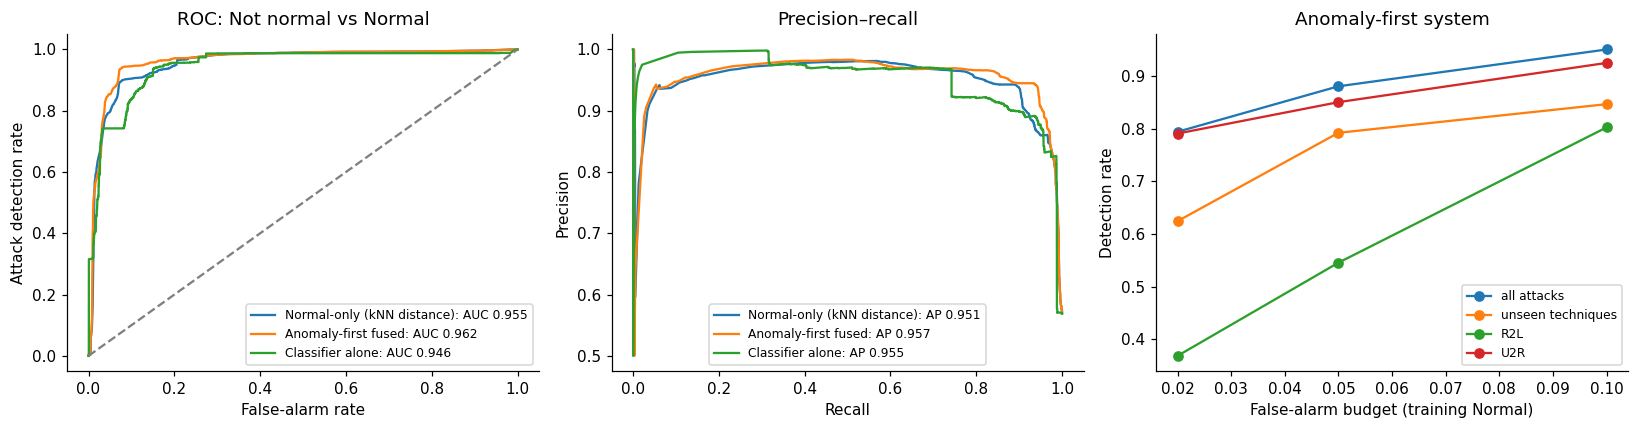

In [18]:
def anomaly_first_labels(alerts, scores, cutoff=None):
    """Stage 1 decides Normal / Not normal. Stage 2 names a family only when the classifier is confident."""
    cutoff = UNKNOWN_CUTOFF if cutoff is None else cutoff
    family_ = to_family(scores).astype(object)
    named = alerts & (family_ != 'Normal') & (scores.max(axis=1) >= cutoff)
    return np.where(~alerts, 'Normal', np.where(named, family_, 'Unknown attack')).astype(object)


AF_BUDGET = 0.05                      # main operating point = the 5% budget already declared in §7
af_alerts = fused_test > AF_THRESHOLDS[AF_BUDGET]['fused']
af_prediction = anomaly_first_labels(af_alerts, primary_scores)
OUTPUT_LABELS = CLASSES + ['Unknown attack']
af_confusion = pd.crosstab(pd.Series(yte, name='true family'),
                           pd.Series(pd.Categorical(af_prediction, categories=OUTPUT_LABELS), name='system output'),
                           dropna=False).reindex(index=CLASSES)
print('Anomaly-first system at the 5% budget: true family x output')
display(af_confusion)
named_rows = np.isin(af_prediction, ATTACK_FAMILIES)
AF_SUMMARY = dict(
    budget=AF_BUDGET, anomaly_score=AF_SCORE, naming_cutoff=UNKNOWN_CUTOFF,
    **detection_rates(yte, af_alerts, novel_mask),
    unknown_share_of_alerts=float(np.mean(af_prediction[af_alerts] == 'Unknown attack')),
    named_family_precision=float(np.mean(af_prediction[named_rows] == yte[named_rows])),
    five_class_accuracy_unknown_counted_wrong=float(np.mean(af_prediction == yte)),
    attack_rows_reaching_high_or_critical=float(np.mean(np.isin(
        [RISK_POLICY[x] for x in af_prediction[yte != 'Normal']], ['High', 'Critical']))),
)
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in AF_SUMMARY.items()})

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
attack_truth = yte != 'Normal'
for name, score in [(f'Normal-only ({AF_SCORE})', anomaly_test), ('Anomaly-first fused', fused_test),
                    ('Classifier alone', 1 - primary_scores[:, 0])]:
    fpr, tpr, _ = roc_curve(attack_truth, score)
    precision, recall, _ = precision_recall_curve(attack_truth, score)
    axes[0].plot(fpr, tpr, label=f'{name}: AUC {roc_auc_score(attack_truth, score):.3f}')
    axes[1].plot(recall, precision, label=f'{name}: AP {average_precision_score(attack_truth, score):.3f}')
axes[0].plot([0, 1], [0, 1], '--', color='grey')
axes[0].set(xlabel='False-alarm rate', ylabel='Attack detection rate', title='ROC: Not normal vs Normal')
axes[1].set(xlabel='Recall', ylabel='Precision', title='Precision–recall')
fused_rows = anomaly_operating[anomaly_operating.system.str.startswith('Anomaly-first')]
axes[2].plot(fused_rows.budget, fused_rows.attack_detection, marker='o', label='all attacks')
axes[2].plot(fused_rows.budget, fused_rows.unseen_technique_detection, marker='o', label='unseen techniques')
for fam in ['R2L', 'U2R']:
    axes[2].plot(fused_rows.budget, fused_rows[f'{fam}_detection'], marker='o', label=fam)
axes[2].set(xlabel='False-alarm budget (training Normal)', ylabel='Detection rate', title='Anomaly-first system')
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 12B. Second stage for R2L and U2R

R2L and U2R connections mostly look like ordinary logins, so the main classifier calls most of them Normal (§5). A small second model looks again **only at rows the classifier calls Normal**, using *behaviour* features that describe what the session did rather than which exact technique it is: failed logins, guest login, logged in, `hot` indicators, root shell, `su` attempts, compromised conditions, file creations, shells, file accesses, bytes in each direction and in total, duration, connection counts, plus service, flag and protocol.

- Model: class-weighted gradient boosting (shallow, 150 trees) trained on Normal, R2L and U2R training rows.
- Its R2L+U2R probability must reach a threshold. The threshold is chosen on the leave-attack-type-out folds (so validation R2L/U2R techniques are unseen) to maximise F1, with at most **2% extra false alarms** on validation Normal, a limit fixed in advance.
- When it fires, the row is relabelled R2L or U2R, whichever is more likely.

In [19]:
BEHAVIOUR_NUMERIC = [c for c in [
    'num_failed_logins', 'is_guest_login', 'logged_in', 'hot', 'root_shell', 'su_attempted',
    'num_compromised', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files',
    'log_src_bytes', 'log_dst_bytes', 'log_total_bytes', 'log_duration', 'byte_ratio',
    'log_count', 'log_srv_count', 'dst_host_count', 'dst_host_srv_count',
    'dst_host_same_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate']
    if c == 'log_total_bytes' or train[c].nunique() > 1]
STAGE2_MAX_EXTRA_FPR = 0.02     # stage 2 may add at most 2% false alarms on validation Normal (fixed in advance)
STAGE2_CLASSES = ['Normal', 'R2L', 'U2R']


def behaviour_matrix(frame):
    frame = frame.assign(log_total_bytes=np.log1p(frame.src_bytes.astype(float) + frame.dst_bytes.astype(float)))
    return encode_matrix(frame, BEHAVIOUR_NUMERIC, cat_levels)


def fit_stage2(matrix, labels):
    keep = np.isin(labels, STAGE2_CLASSES)
    model = HistGradientBoostingClassifier(class_weight='balanced', max_iter=150, max_depth=4,
                                           learning_rate=0.08, min_samples_leaf=10, random_state=SEED)
    return model.fit(matrix[keep], labels[keep])


def stage2_scores(model, matrix):
    proba = model.predict_proba(matrix)
    columns = [list(model.classes_).index(c) for c in ['R2L', 'U2R']]
    return proba[:, columns].sum(axis=1), np.asarray(['R2L', 'U2R'])[proba[:, columns].argmax(axis=1)]


Btr, Bte = behaviour_matrix(train), behaviour_matrix(test)

# --- threshold chosen on leave-attack-type-out folds: validation R2L/U2R techniques are unseen ---
s2_oof = np.full(len(train), np.nan)
for f in range(FOLDS):
    fit_rows, val_rows = fold_id != f, fold_id == f
    s2_oof[val_rows] = stage2_scores(fit_stage2(Btr[fit_rows], ytr[fit_rows]), Btr[val_rows])[0]
reach = oof_family == 'Normal'                       # rows the primary model calls Normal reach stage 2
target = np.isin(ytr, ['R2L', 'U2R'])
n_normal = int((ytr == 'Normal').sum())
s2_grid = []
for threshold in np.unique(np.quantile(s2_oof[reach], np.linspace(0.5, 0.9999, 300))):
    fire = reach & (s2_oof >= threshold)
    p, r, f1_, _ = precision_recall_fscore_support(target[reach], fire[reach], average='binary', zero_division=0)
    s2_grid.append(dict(threshold=float(threshold), precision=p, recall=r, f1=f1_,
                        extra_normal_fpr=float((fire & (ytr == 'Normal')).sum() / n_normal)))
s2_grid = pd.DataFrame(s2_grid)
eligible_s2 = s2_grid[s2_grid.extra_normal_fpr <= STAGE2_MAX_EXTRA_FPR]
STAGE2_THRESHOLD = float(eligible_s2.sort_values(['f1', 'recall'], ascending=False).iloc[0].threshold)
print('Stage-2 threshold frozen on validation:', round(STAGE2_THRESHOLD, 4))
display(eligible_s2.sort_values('f1', ascending=False).head(1).round(4))

# --- final stage-2 model on all of KDDTrain+, applied once to KDDTest+ ---
stage2_model = fit_stage2(Btr, ytr)
s2_test, s2_family = stage2_scores(stage2_model, Bte)
stage2_fire = (primary_prediction == 'Normal') & (s2_test >= STAGE2_THRESHOLD)
stage2_prediction = primary_prediction.astype(object).copy()
stage2_prediction[stage2_fire] = s2_family[stage2_fire]

stage2_rows = []
for name, pred in [('Primary classifier (§5)', primary_prediction), ('Primary + R2L/U2R second stage', stage2_prediction)]:
    pc = family_metrics(yte, pred)
    stage2_rows.append(dict(system=name, accuracy=accuracy_score(yte, pred),
                            macro_f1=f1_score(yte, pred, average='macro'),
                            R2L_precision=pc.loc['R2L', 'precision'], R2L_recall=pc.loc['R2L', 'recall'],
                            U2R_precision=pc.loc['U2R', 'precision'], U2R_recall=pc.loc['U2R', 'recall'],
                            attack_detection=float(np.mean(pred[yte != 'Normal'] != 'Normal')),
                            normal_fpr=normal_fpr(yte, pred)))
stage2_table = pd.DataFrame(stage2_rows)
display(stage2_table.round(4))
s2_tech = (pd.DataFrame({'attack': test.attack, 'family': yte, 'before': primary_prediction == yte,
                         'after': stage2_prediction == yte})[np.isin(yte, ['R2L', 'U2R'])]
           .groupby(['family', 'attack']).agg(rows=('before', 'size'), recall_before=('before', 'mean'),
                                              recall_after=('after', 'mean')))
s2_tech['train_rows'] = attack_counts.train_rows.reindex(s2_tech.index.get_level_values('attack')).to_numpy()
print('R2L/U2R recall per technique, before and after stage 2:')
display(s2_tech.sort_values('rows', ascending=False).round(3))

Stage-2 threshold frozen on validation: 0.5069


,threshold,precision,recall,f1,extra_normal_fpr
213,0.5069,0.194,0.0256,0.0453,0.0015


,system,accuracy,macro_f1,R2L_precision,R2L_recall,U2R_precision,U2R_recall,attack_detection,normal_fpr
0,Primary classifier (§5),0.8024,0.6861,0.9877,0.2787,0.6667,0.3881,0.7061,0.0296
1,Primary + R2L/U2R second stage,0.8091,0.6957,0.9786,0.3328,0.5385,0.4179,0.7196,0.0304


R2L/U2R recall per technique, before and after stage 2:


rows  recall_before  recall_after  train_rows
family attack                                                        
R2L    guess_passwd     1231          0.051         0.116          53
       warezmaster       944          0.779         0.854          20
       snmpguess         331          0.000         0.000           0
       snmpgetattack     178          0.000         0.000           0
       httptunnel        133          0.000         0.000           0
U2R    buffer_overflow    20          0.450         0.500          30
R2L    multihop           18          0.111         0.111           7
       named              17          0.059         0.235           0
U2R    ps                 15          0.333         0.333           0
R2L    sendmail           14          0.000         0.143           0
U2R    rootkit            13          0.308         0.308          10
       xterm              13          0.385         0.385           0
R2L    xlock               9          0.000         0.000           0
       xsnoop              4          0.000         0.000           0
       ftp_write           3          0.333         0.333           8
       phf                 2          0.500         0.500           4
U2R    perl                2          1.000         1.000           3
       loadmodule          2          0.000         0.500           9
       sqlattack           2          0.500         0.500           0
R2L    imap                1          1.000         1.000          11

## 12C. UNSW-NB15: anomaly detection using host and time

NSL-KDD has no addresses or timestamps; UNSW-NB15 does. This section uses them directly: every **source host** is described **minute by minute**.

**Host-minute window features:** number of flows, distinct destination hosts and ports, total bytes each way, mean log bytes, mean and maximum duration, mean source/destination TTL, mean inter-packet time, share of TCP/UDP, share of each connection state, share of flows with no recognised service, and mean gap between flow starts. A window is an attack window if it contains any attack flow (labels are used only for scoring).

**Normal-only training on held-out hosts.** The same four host partitions as §9a are reused: each attacker host is held out once as the test attacker, the next attacker plus a group of benign hosts form the validation set, and a different group of benign hosts is in the test set. Detectors (Isolation Forest and kNN distance, and their mean) are fitted **only on benign hosts outside the validation and test sets**. On each fold the score with the best validation PR AUC is used, and the alarm threshold is the 95th percentile of the **validation benign hosts** (a 5% budget). Test hosts are never used for fitting or thresholds.

**Comparisons.** (1) Host-minute results per fold. (2) The same §9a test windows (20-flow host pairs), each scored by its most unusual host-minute, compared with the supervised HMM and the supervised per-flow booster from §9a. (3) **Extra unseen data:** shards 2–4 of UNSW-NB15 (later capture days, never used for anything else) are scored by a detector fitted on shard-1 benign hosts only, with its 5% threshold from held-out shard-1 benign windows. Set `USE_EXTRA_SHARDS = False` to skip them.

*Caveat:* the attacker machines in UNSW-NB15 use very different TTL values from the benign machines, a known artefact of the testbed, so TTL features make this dataset easier than a real network.

In [20]:
HOST_WINDOW_SECONDS = 60            # one window = everything one source host did in one minute
HOST_COLUMNS = ['srcip', 'dstip', 'dsport', 'proto', 'state', 'service', 'dur', 'sbytes', 'dbytes',
                'sttl', 'dttl', 'sintpkt', 'stime', 'attack_cat', 'label']
UNSW_EXTRA_SHARDS = ['UNSW-NB15_2.csv', 'UNSW-NB15_3.csv', 'UNSW-NB15_4.csv']
USE_EXTRA_SHARDS = True             # set False to skip the extra unseen shards (saves ~1-2 minutes)


def load_host_flows(path):
    flows = pd.read_csv(path, header=None, names=RAW_COLUMNS, usecols=HOST_COLUMNS, encoding='utf-8-sig',
                        dtype={'srcip': str, 'dstip': str, 'dsport': str}, low_memory=False)
    for column in ['dur', 'sbytes', 'dbytes', 'sttl', 'dttl', 'sintpkt', 'stime', 'label']:
        flows[column] = pd.to_numeric(flows[column], errors='coerce').fillna(0)
    return flows


def host_time_windows(flows):
    """Aggregate flows into (source host, minute) windows. Returns the window table and each flow's window id."""
    f = flows.assign(minute=(flows.stime // HOST_WINDOW_SECONDS).astype(np.int64),
                     tcp=flows.proto.eq('tcp'), udp=flows.proto.eq('udp'),
                     st_fin=flows.state.eq('FIN'), st_con=flows.state.eq('CON'), st_int=flows.state.eq('INT'),
                     st_req=flows.state.eq('REQ'), no_service=flows.service.astype(str).str.strip().eq('-'),
                     log_sbytes=np.log1p(flows.sbytes), log_dbytes=np.log1p(flows.dbytes))
    keys = ['srcip', 'minute']
    grouped = f.groupby(keys, sort=True)
    table = grouped.agg(flows=('stime', 'size'), dst_hosts=('dstip', 'nunique'), dst_ports=('dsport', 'nunique'),
                        sbytes=('sbytes', 'sum'), dbytes=('dbytes', 'sum'), mean_log_sbytes=('log_sbytes', 'mean'),
                        mean_log_dbytes=('log_dbytes', 'mean'), mean_dur=('dur', 'mean'), max_dur=('dur', 'max'),
                        mean_sttl=('sttl', 'mean'), mean_dttl=('dttl', 'mean'), mean_sintpkt=('sintpkt', 'mean'),
                        tcp=('tcp', 'mean'), udp=('udp', 'mean'), st_fin=('st_fin', 'mean'), st_con=('st_con', 'mean'),
                        st_int=('st_int', 'mean'), st_req=('st_req', 'mean'), no_service=('no_service', 'mean'),
                        first=('stime', 'min'), last=('stime', 'max'),
                        attack=('label', 'max'), attack_flows=('label', 'sum')).reset_index()
    table['mean_gap'] = (table['last'] - table['first']) / (table.flows - 1).clip(lower=1)
    flow_window = grouped.ngroup().to_numpy()
    return table, flow_window


HOST_FEATURES = ['flows', 'dst_hosts', 'dst_ports', 'sbytes', 'dbytes', 'mean_log_sbytes', 'mean_log_dbytes',
                 'mean_dur', 'max_dur', 'mean_sttl', 'mean_dttl', 'mean_sintpkt', 'tcp', 'udp', 'st_fin',
                 'st_con', 'st_int', 'st_req', 'no_service', 'mean_gap']
LOG_FEATURES = ['flows', 'dst_hosts', 'dst_ports', 'sbytes', 'dbytes', 'mean_dur', 'max_dur', 'mean_sintpkt', 'mean_gap']


def host_matrix(table):
    m = table[HOST_FEATURES].astype(float).copy()
    m[LOG_FEATURES] = np.log1p(m[LOG_FEATURES].clip(lower=0))
    return m.to_numpy(np.float64)


HOST_CANDIDATES = ['Isolation forest', 'kNN distance', 'Mean of two']


def fit_host_scorers(normal_matrix, seed):
    scaler = StandardScaler().fit(normal_matrix)
    Zn = scaler.transform(normal_matrix)
    iso = IsolationForest(n_estimators=200, n_jobs=CPU_THREADS, random_state=seed).fit(Zn)
    reference = Zn[np.random.default_rng(seed).choice(len(Zn), min(KNN_REFERENCE, len(Zn)), replace=False)]
    knn = NearestNeighbors(n_neighbors=5, n_jobs=CPU_THREADS).fit(reference)
    return {'Isolation forest': lambda M: -iso.score_samples(scaler.transform(M)),
            'kNN distance': lambda M: knn.kneighbors(scaler.transform(M))[0].mean(axis=1)}


def host_percentiles(scorers_, M_reference, M_target):
    out = {}
    for name in ['Isolation forest', 'kNN distance']:
        ref = scorers_[name](M_reference)
        out[name] = (normal_percentile(ref, ref), normal_percentile(ref, scorers_[name](M_target)))
    out['Mean of two'] = tuple((out['Isolation forest'][i] + out['kNN distance'][i]) / 2 for i in (0, 1))
    return out


host_results = host_pair_results = host_shard_results = None
if not UNSW_AVAILABLE:
    print('SKIPPED: UNSW-NB15_1.csv is not available.')
else:
    start_c = time.perf_counter()
    host_flows = load_host_flows(RAW_PATH)
    assert len(host_flows) == len(raw) and (host_flows.label.to_numpy() == raw.label.to_numpy()).all()
    hw, flow_hw = host_time_windows(host_flows)
    HW = host_matrix(hw)
    hw_attack = hw.attack.to_numpy().astype(int)
    hw_host = hw.srcip.to_numpy()
    print({'host_time_windows': len(hw), 'attack_windows': int(hw_attack.sum()), 'source_hosts': hw.srcip.nunique(),
           'median_flows_per_window': float(hw.flows.median())})

    host_rows, pair_rows, chosen_scores = [], [], []
    n_folds = len(attack_hosts)
    for fold, held_out_host in enumerate(attack_hosts):          # the same host partitions as §9a
        validation_host = attack_hosts[(fold + 1) % n_folds]
        test_hosts = set(benign_groups[fold]) | {held_out_host}
        validation_hosts = set(benign_groups[(fold + 1) % n_folds]) | {validation_host}
        training_hosts = set(usable_hosts) - test_hosts - validation_hosts
        # normal-only training: every benign host outside this fold's validation/test hosts
        # (including low-volume hosts that §9 could not turn into 20-flow windows)
        fit_w = np.flatnonzero(~np.isin(hw_host, list(test_hosts | validation_hosts | set(attack_hosts))))
        val_w = np.flatnonzero(np.isin(hw_host, list(validation_hosts)))
        val_benign = val_w[np.isin(hw_host[val_w], benign_hosts)]
        test_w = np.flatnonzero(np.isin(hw_host, list(test_hosts)))
        assert hw_attack[fit_w].sum() == 0 and set(hw_attack[test_w]) == {0, 1}
        host_scorers = fit_host_scorers(HW[fit_w], SEED + fold)
        pct_all = host_percentiles(host_scorers, HW[val_benign], HW)   # reference = held-out benign hosts
        # pick the score with the best PR AUC on the validation hosts (they include one attacker)
        best = max(HOST_CANDIDATES, key=lambda n: average_precision_score(hw_attack[val_w], pct_all[n][1][val_w]))
        chosen_scores.append(best)
        ref, score = pct_all[best]
        threshold = budget_threshold(ref, 0.05)                 # 5% budget on validation benign hosts
        row = binary_summary(hw_attack[test_w], score[test_w], np.nextafter(threshold, np.inf))
        row.update(fold=fold, test_attack_host=held_out_host, score_used=best)
        host_rows.append(row)
        # like-for-like with §9a: score each 20-flow pair window by its most anomalous host-minute
        te_pairs = np.flatnonzero(np.isin(window_hosts, list(test_hosts)))
        pair_score = score[flow_hw[windows[te_pairs]]].max(axis=1)
        pair_rows.append(dict(fold=fold, model='Host-time anomaly (normal-only)',
                              roc_auc=roc_auc_score(window_attack[te_pairs], pair_score),
                              average_precision=average_precision_score(window_attack[te_pairs], pair_score)))
        print(f'Fold {fold + 1}/{n_folds} (attacker {held_out_host}, score {best}): host-minute AUC {row["roc_auc"]:.3f}, '
              f'recall {row["recall"]:.3f}, FPR {row["normal_fpr"]:.3f}', flush=True)

    host_results = pd.DataFrame(host_rows)
    display(host_results[['fold', 'test_attack_host', 'score_used', 'support', 'attack_windows', 'roc_auc',
                          'average_precision', 'precision', 'recall', 'f1', 'normal_fpr']].round(4))
    host_mean = host_results[['roc_auc', 'average_precision', 'precision', 'recall', 'f1', 'normal_fpr']].agg(['mean', 'std'])
    print('Host-minute windows, mean over held-out attacker hosts:')
    display(host_mean.round(4))
    reference_models = sequence_results[sequence_results.model.isin(['HMM', 'Independent-flow booster'])][
        ['fold', 'model', 'roc_auc', 'average_precision']]
    host_pair_results = pd.concat([pd.DataFrame(pair_rows), reference_models], ignore_index=True)
    print('Same §9a test windows and folds: normal-only host-time detector vs the supervised HMM and flow booster')
    display(host_pair_results.groupby('model')[['roc_auc', 'average_precision']].agg(['mean', 'std']).round(4))
    HOST_SUMMARY = dict(host_minute_auc=float(host_results.roc_auc.mean()),
                        host_minute_pr_auc=float(host_results.average_precision.mean()),
                        host_minute_recall=float(host_results.recall.mean()),
                        host_minute_precision=float(host_results.precision.mean()),
                        host_minute_fpr=float(host_results.normal_fpr.mean()),
                        pair_window_auc=float(pd.DataFrame(pair_rows).roc_auc.mean()),
                        pair_window_pr_auc=float(pd.DataFrame(pair_rows).average_precision.mean()))

    # --- extra unseen data: shards 2-4, scored by a detector fitted on shard-1 benign hosts only ---
    if USE_EXTRA_SHARDS:
        final_score = pd.Series(chosen_scores).mode().iloc[0]
        benign_w = np.flatnonzero(~np.isin(hw_host, attack_hosts))
        fit_part, ref_part = split_normal(benign_w, SEED)
        shard_scorers = fit_host_scorers(HW[fit_part], SEED)
        shard_rows = []
        for shard in UNSW_EXTRA_SHARDS:
            path = RAW_PATH.parent / shard
            if not path.is_file():
                print('missing', shard); continue
            table, _ = host_time_windows(load_host_flows(path))
            truth = table.attack.to_numpy().astype(int)
            ref, score = host_percentiles(shard_scorers, HW[ref_part], host_matrix(table))[final_score]
            row = binary_summary(truth, score, np.nextafter(budget_threshold(ref, 0.05), np.inf))
            row.update(shard=shard, score_used=final_score, attack_hosts=int(table.loc[truth == 1, 'srcip'].nunique()))
            shard_rows.append(row)
        host_shard_results = pd.DataFrame(shard_rows)
        print('Shards 2-4 (never used for fitting or thresholds), 5% budget from shard-1 benign hosts:')
        display(host_shard_results[['shard', 'score_used', 'support', 'attack_windows', 'attack_hosts', 'roc_auc',
                                    'average_precision', 'precision', 'recall', 'f1', 'normal_fpr']].round(4))
    print(f'§12C runtime {time.perf_counter() - start_c:.0f}s')

{'host_time_windows': 8632, 'attack_windows': 469, 'source_hosts': 40, 'median_flows_per_window': 104.0}


Fold 1/4 (attacker 175.45.176.0, score Mean of two): host-minute AUC 1.000, recall 1.000, FPR 0.076


Fold 2/4 (attacker 175.45.176.1, score kNN distance): host-minute AUC 0.998, recall 0.992, FPR 0.026


Fold 3/4 (attacker 175.45.176.2, score kNN distance): host-minute AUC 0.999, recall 1.000, FPR 0.062


Fold 4/4 (attacker 175.45.176.3, score Isolation forest): host-minute AUC 0.810, recall 0.256, FPR 0.112


,fold,test_attack_host,score_used,support,attack_windows,roc_auc,average_precision,precision,recall,f1,normal_fpr
0,0,175.45.176.0,Mean of two,1961,117,0.9999,0.9969,0.4535,1.0000,0.6240,0.0765
1,1,175.45.176.1,kNN distance,1939,118,0.9981,0.9934,0.7134,0.9915,0.8298,0.0258
2,2,175.45.176.2,kNN distance,1530,117,0.9993,0.9832,0.5735,1.0000,0.7290,0.0616
3,3,175.45.176.3,Isolation forest,1501,117,0.8096,0.2298,0.1622,0.2564,0.1987,0.1120


... (3 outputs left out)

roc_auc         average_precision        
                                   mean     std              mean     std
model                                                                    
HMM                              0.9880  0.0207            0.6634  0.3858
Host-time anomaly (normal-only)  0.9968  0.0038            0.7685  0.1879
Independent-flow booster         0.9939  0.0103            0.8803  0.1127

Shards 2-4 (never used for fitting or thresholds), 5% budget from shard-1 benign hosts:


,shard,score_used,support,attack_windows,attack_hosts,roc_auc,average_precision,precision,recall,f1,normal_fpr
0,UNSW-NB15_2.csv,kNN distance,8046,690,4,0.9979,0.9568,0.6473,1.0,0.7859,0.0511
1,UNSW-NB15_3.csv,kNN distance,6403,1263,4,0.9926,0.9429,0.6947,1.0,0.8199,0.1080
2,UNSW-NB15_4.csv,kNN distance,4037,792,4,0.9907,0.9294,0.7021,1.0,0.8250,0.1035


§12C runtime 8s


## 12D. Anomaly-first system: claims vs evidence

The full system on `KDDTest+` is §12A at the 5% budget plus the §12B second stage for rows the classifier calls Normal. The table then checks every claim of the problem statement against this run's numbers, with an honest status. All numbers are generated in this run.

*§12E below improves several of these results and appends its rows to this table.*

In [21]:
# Full anomaly-first system on KDDTest+: §12A decides Normal / Not normal and names confident families,
# §12B re-checks the rows the classifier calls Normal for R2L/U2R behaviour.
full_prediction = af_prediction.copy()
full_prediction[stage2_fire] = s2_family[stage2_fire]
full_alerts = full_prediction != 'Normal'
full_classes = family_metrics(yte, np.where(full_prediction == 'Unknown attack', 'Unknown', full_prediction))
FULL_SYSTEM = dict(**detection_rates(yte, full_alerts, novel_mask),
                   R2L_named_precision=full_classes.loc['R2L', 'precision'], R2L_named_recall=full_classes.loc['R2L', 'recall'],
                   U2R_named_precision=full_classes.loc['U2R', 'precision'], U2R_named_recall=full_classes.loc['U2R', 'recall'],
                   unknown_share_of_alerts=float(np.mean(full_prediction[full_alerts] == 'Unknown attack')),
                   attacks_high_or_critical=float(np.mean(np.isin([RISK_POLICY[x] for x in full_prediction[yte != 'Normal']],
                                                                   ['High', 'Critical']))),
                   normal_high_or_critical=float(np.mean(np.isin([RISK_POLICY[x] for x in full_prediction[yte == 'Normal']],
                                                                  ['High', 'Critical']))))
print('Full anomaly-first system (5% budget + R2L/U2R second stage) on KDDTest+:')
print({k: round(v, 4) for k, v in FULL_SYSTEM.items()})
display(pd.crosstab(pd.Series(yte, name='true family'),
                    pd.Series(pd.Categorical(full_prediction, categories=OUTPUT_LABELS), name='system output'),
                    dropna=False).reindex(index=CLASSES))


def af_row(budget):
    return anomaly_operating[(anomaly_operating.system.str.startswith('Anomaly-first')) & (anomaly_operating.budget == budget)].iloc[0]


a2, a5, a10 = af_row(0.02), af_row(0.05), af_row(0.10)
s2_new = stage2_table.iloc[1]
claims = [
    ('Detect anomalies and previously unseen attacks (primary goal)',
     f'Anomaly-first system at the 5% budget: attack detection {a5.attack_detection:.1%}, unseen techniques '
     f'{a5.unseen_technique_detection:.1%}, test Normal false alarms {a5.normal_fpr:.1%} (2% budget: '
     f'{a2.attack_detection:.1%} / {a2.unseen_technique_detection:.1%} / {a2.normal_fpr:.1%}; 10%: '
     f'{a10.attack_detection:.1%} / {a10.unseen_technique_detection:.1%} / {a10.normal_fpr:.1%}). '
     f'Classifier alone: {PRIMARY_BINARY["recall"]:.1%} / {np.mean(base_alerts[novel_mask]):.1%} / {PRIMARY_BINARY["normal_fpr"]:.1%}',
     'Met; test false alarms run above the training budget because KDDTest+ Normal traffic differs from training'),
    ('Normal-only anomaly score quality (no attack labels used)',
     f'{AF_SCORE} chosen on validation: ROC AUC {score_quality.set_index("score").loc[AF_SCORE, "roc_auc"]:.3f}, '
     f'PR AUC {score_quality.set_index("score").loc[AF_SCORE, "pr_auc"]:.3f}',
     'Met'),
    ('Unknown-attack output and family naming',
     f'{AF_SUMMARY["unknown_share_of_alerts"]:.1%} of alerts labelled Unknown attack; named families correct '
     f'{AF_SUMMARY["named_family_precision"]:.1%} of the time (confidence cutoff {UNKNOWN_CUTOFF:.2f} from validation)',
     'Met'),
    ('R2L / U2R detection (as Not normal)',
     f'R2L {a5.R2L_detection:.1%}, U2R {a5.U2R_detection:.1%} flagged at the 5% budget '
     f'(classifier alone {np.mean(base_alerts[yte == "R2L"]):.1%} / {np.mean(base_alerts[yte == "U2R"]):.1%})',
     'Partially met: detection improves, many still look normal'),
    ('R2L / U2R exact family (second stage)',
     f'R2L recall {stage2_table.iloc[0].R2L_recall:.1%} → {s2_new.R2L_recall:.1%}, U2R {stage2_table.iloc[0].U2R_recall:.1%} → '
     f'{s2_new.U2R_recall:.1%}; Normal false alarms {stage2_table.iloc[0].normal_fpr:.2%} → {s2_new.normal_fpr:.2%}',
     'Limitation: small gain; techniques never seen in training stay at 0% (' + ', '.join(
         s2_tech[(s2_tech.train_rows == 0) & (s2_tech.recall_after == 0) & (s2_tech.rows >= 100)]
         .index.get_level_values('attack')) + ')'),
]
if host_results is not None:
    claims.append(('Host and time based anomaly detection (UNSW-NB15)',
                   f'held-out attacker hosts: host-minute AUC {HOST_SUMMARY["host_minute_auc"]:.3f}, PR AUC '
                   f'{HOST_SUMMARY["host_minute_pr_auc"]:.3f}, recall {HOST_SUMMARY["host_minute_recall"]:.1%}, false alarms '
                   f'{HOST_SUMMARY["host_minute_fpr"]:.1%}; on §9a windows AUC {HOST_SUMMARY["pair_window_auc"]:.4f} vs HMM '
                   f'{order_effect["hmm_auc"]:.4f} and supervised flow booster {order_effect["flow_baseline_auc"]:.4f}',
                   f'Met for {int((host_results.roc_auc > 0.95).sum())} of {len(host_results)} attacker hosts; one host is hard'))
if host_shard_results is not None and len(host_shard_results):
    claims.append(('Generalisation to later UNSW-NB15 traffic (shards 2-4, never used for fitting)',
                   '; '.join(f'{r.shard}: AUC {r.roc_auc:.3f}, recall {r.recall:.1%}, false alarms {r.normal_fpr:.1%}'
                             for r in host_shard_results.itertuples()),
                   'Met for ranking; false alarms drift above the 5% budget on later shards'))
claims += [
    ('Supervised and ensemble classification (secondary goal)',
     f'{SELECTED_NAME}: accuracy {PRIMARY_ACCURACY:.2%}, macro F1 {PRIMARY_MACRO_F1:.3f}', 'Met'),
    ('Clustering for unknown patterns', f'k-means k={chosen_k}, purity {cluster_metrics["purity"]:.3f}; '
     f'normal-only scores catch {a5.unseen_technique_detection:.1%} of test-only techniques', 'Met'),
    ('HMMs for multi-stage behaviour', f'real UNSW order adds {order_effect["hmm_minus_shuffled_auc"]:+.4f} AUC; '
     f'simulated chain {SIMULATION["HMM ordered"]:.3f} ordered vs {SIMULATION["HMM shuffled"]:.3f} shuffled'
     if order_effect is not None else 'UNSW not available', 'Partially met: order only helps on simulated chains'),
    ('Risk classification and decision support',
     f'{FULL_SYSTEM["attacks_high_or_critical"]:.1%} of attacks reach High/Critical (Unknown attack = High) vs '
     f'{FULL_SYSTEM["normal_high_or_critical"]:.1%} of Normal; {LATENCY["connections_per_second"]:,.0f} connections/s offline',
     'Met (offline prototype)'),
]
claims_table = pd.DataFrame(claims, columns=['claim', 'evidence from this run', 'status'])
with pd.option_context('display.max_colwidth', None):
    display(claims_table)

Full anomaly-first system (5% budget + R2L/U2R second stage) on KDDTest+:
{'attack_detection': 0.8826, 'precision': 0.9479, 'f1': 0.9141, 'normal_fpr': 0.0642, 'binary_accuracy': 0.9056, 'unseen_technique_detection': 0.7931, 'DoS_detection': 0.9727, 'Probe_detection': 0.9988, 'R2L_detection': 0.5532, 'U2R_detection': 0.8507, 'R2L_named_precision': np.float64(0.9568), 'R2L_named_recall': np.float64(0.0998), 'U2R_named_precision': np.float64(0.4074), 'U2R_named_recall': np.float64(0.1642), 'unknown_share_of_alerts': 0.3181, 'attacks_high_or_critical': 0.7556, 'normal_high_or_critical': 0.0434}


system output,Normal,DoS,Probe,R2L,U2R,Unknown attack
true family,,,,,,
Normal,9088,54,202,8,4,355
DoS,204,5770,61,0,0,1425
Probe,3,165,1559,0,0,694
R2L,1289,0,10,288,12,1286
U2R,10,0,0,5,11,41


,claim,evidence from this run,status
0,Detect anomalies and previously unseen attacks (primary goal),"Anomaly-first system at the 5% budget: attack detection 88.1%, unseen techniques 79.3%, test Normal false alarms 6.4% (2% budget: 79.4% / 62.5% / 3.7%; 10%: 95.1% / 84.7% / 13.1%). Classifier alone: 70.6% / 38.1% / 3.0%",Met; test false alarms run above the training budget because KDDTest+ Normal traffic differs from training
1,Normal-only anomaly score quality (no attack labels used),"kNN distance chosen on validation: ROC AUC 0.955, PR AUC 0.951",Met
2,Unknown-attack output and family naming,33.2% of alerts labelled Unknown attack; named families correct 93.7% of the time (confidence cutoff 0.85 from validation),Met
3,R2L / U2R detection (as Not normal),"R2L 54.6%, U2R 85.1% flagged at the 5% budget (classifier alone 29.5% / 46.3%)","Partially met: detection improves, many still look normal"
4,R2L / U2R exact family (second stage),"R2L recall 27.9% → 33.3%, U2R 38.8% → 41.8%; Normal false alarms 2.96% → 3.04%","Limitation: small gain; techniques never seen in training stay at 0% (httptunnel, snmpgetattack, snmpguess)"
5,Host and time based anomaly detection (UNSW-NB15),"held-out attacker hosts: host-minute AUC 0.952, PR AUC 0.801, recall 81.2%, false alarms 6.9%; on §9a windows AUC 0.9968 vs HMM 0.9880 and supervised flow booster 0.9939",Met for 3 of 4 attacker hosts; one host is hard
6,"Generalisation to later UNSW-NB15 traffic (shards 2-4, never used for fitting)","UNSW-NB15_2.csv: AUC 0.998, recall 100.0%, false alarms 5.1%; UNSW-NB15_3.csv: AUC 0.993, recall 100.0%, false alarms 10.8%; UNSW-NB15_4.csv: AUC 0.991, recall 100.0%, false alarms 10.4%",Met for ranking; false alarms drift above the 5% budget on later shards
7,Supervised and ensemble classification (secondary goal),"Gradient boosting (class-weighted): accuracy 80.24%, macro F1 0.686",Met
8,Clustering for unknown patterns,"k-means k=5, purity 0.730; normal-only scores catch 79.3% of test-only techniques",Met
9,HMMs for multi-stage behaviour,real UNSW order adds +0.0000 AUC; simulated chain 0.870 ordered vs 0.641 shuffled,Partially met: order only helps on simulated chains


## 12E. Improvements and the final system

This section fixes, or honestly tests, the weak points found in §12A–12D. Every choice is still made on training data only: the leave-attack-type-out folds of §4, held-out training Normal rows, or UNSW validation hosts. `KDDTest+` and the UNSW test hosts are only scored.

### 12E-1. Normal-traffic drift and drift-robust detectors (plus a One-Class SVM)

**Problem.** In §12A the false-alarm rate on test Normal was higher than the budget set on training Normal. That happens when normal traffic itself changes between the two files.

**Diagnosis.** For every traffic feature, a Kolmogorov–Smirnov (KS) statistic measures how different two distributions are (0 = identical, 1 = completely different). It is computed (a) between the fitting part and the held-out part of *training* Normal, and (b) between training Normal and test Normal. Column (b) is a **diagnostic only**: it uses no labels for choosing and changes nothing downstream.

**Candidates**, compared on the training folds exactly as in §12A:
- three feature spaces: the standard space of §12A, a **quantile-scaled** space (each feature replaced by its rank among training Normal, which limits the effect of extreme values), and a space **without the `dst_host_*` window features**, which summarise the last 100 connections to the same host and so depend on the network's traffic mix;
- three detectors: kNN distance, a **One-Class SVM** (RBF kernel, fitted on 5,000 Normal rows), and their mean.

**Selection rule, declared before testing:** highest mean validation detection over the 2/5/10% budgets; a drift-robust space wins if it is within 1 percentage point of the best. The test table afterwards shows whether any variant would have brought test false alarms back to the budget.

In [22]:
from scipy.stats import ks_2samp
from sklearn.preprocessing import QuantileTransformer
from sklearn.svm import OneClassSVM

# ---------- E1a. Where does Normal traffic drift? ----------
tr_normal, te_normal = Ztr[ytr == 'Normal'], Zte[yte == 'Normal']
fit_normal, hold_normal = Ztr[af_fit], Ztr[af_hold]
drift_table = pd.DataFrame({
    'feature': TRAFFIC_COLUMNS,
    'KS_train_fit_vs_train_holdout': [ks_2samp(fit_normal[:, j], hold_normal[:, j]).statistic for j in range(len(TRAFFIC_COLUMNS))],
    'KS_train_vs_test_normal (diagnostic only)': [ks_2samp(tr_normal[:, j], te_normal[:, j]).statistic for j in range(len(TRAFFIC_COLUMNS))],
    'mean_shift_in_train_SDs (diagnostic only)': (te_normal.mean(axis=0) - tr_normal.mean(axis=0)) / tr_normal.std(axis=0).clip(min=1e-6),
}).sort_values('KS_train_vs_test_normal (diagnostic only)', ascending=False)
print('Normal-traffic drift per feature (test columns are diagnostic only; they choose nothing):')
display(drift_table.head(12).round(3))

# ---------- E1b/E5. drift-robust feature spaces and an extra detector, compared on training folds ----------
HOST_WINDOW_COLUMNS = [c for c in TRAFFIC_COLUMNS if c.startswith('dst_host_')]
SPACE_VARIANTS = ['Standard (§12A)', 'Quantile-scaled', 'Without dst_host window features']
OCSVM_SAMPLE = 5000


def make_space(variant, normal_space):
    if variant == 'Standard (§12A)':
        return lambda Z: Z
    if variant == 'Quantile-scaled':
        qt = QuantileTransformer(n_quantiles=1000, output_distribution='normal', subsample=200000,
                                 random_state=SEED).fit(normal_space)
        return lambda Z: qt.transform(Z)
    keep = [j for j, c in enumerate(TRAFFIC_COLUMNS) if c not in HOST_WINDOW_COLUMNS]
    return lambda Z: Z[:, keep]


def fit_extra_scorers(normal_space, seed):
    rng = np.random.default_rng(seed)
    reference = normal_space[rng.choice(len(normal_space), min(KNN_REFERENCE, len(normal_space)), replace=False)]
    knn = NearestNeighbors(n_neighbors=5, n_jobs=CPU_THREADS).fit(reference)
    svm = OneClassSVM(kernel='rbf', gamma='scale', nu=0.02).fit(
        normal_space[rng.choice(len(normal_space), min(OCSVM_SAMPLE, len(normal_space)), replace=False)])
    return {'kNN distance': lambda Z: knn.kneighbors(Z)[0].mean(axis=1),
            'One-class SVM': lambda Z: -svm.decision_function(Z)}


EXTRA_CANDIDATES = ['kNN distance', 'One-class SVM', 'Mean of kNN + OCSVM']


def extra_percentiles(variant, Z_fit, Z_ref, Z_target, seed):
    space = make_space(variant, Z_fit)
    sc = fit_extra_scorers(space(Z_fit), seed)
    out = {}
    for name in ['kNN distance', 'One-class SVM']:
        ref = sc[name](space(Z_ref))
        out[name] = (normal_percentile(ref, ref), normal_percentile(ref, sc[name](space(Z_target))))
    out['Mean of kNN + OCSVM'] = tuple((out['kNN distance'][i] + out['One-class SVM'][i]) / 2 for i in (0, 1))
    return out


robust_rows = []
start_e1 = time.perf_counter()
for f in range(FOLDS):
    fit_rows, val_rows = np.flatnonzero(fold_id != f), np.flatnonzero(fold_id == f)
    nf, nh = split_normal(fit_rows[ytr[fit_rows] == 'Normal'], SEED + f)
    for variant in SPACE_VARIANTS:
        pct = extra_percentiles(variant, Ztr[nf], Ztr[nh], Ztr[val_rows], SEED + f)
        for name in EXTRA_CANDIDATES:
            for budget in FA_BUDGETS:
                alerts = pct[name][1] > budget_threshold(pct[name][0], budget)
                robust_rows.append(dict(space=variant, detector=name, fold=f, budget=budget,
                                        **detection_rates(ytr[val_rows], alerts)))
    print(f'fold {f + 1}/{FOLDS} done ({time.perf_counter() - start_e1:.0f}s)', flush=True)
robust_val = (pd.DataFrame(robust_rows).groupby(['space', 'detector'])
              [['attack_detection', 'normal_fpr', 'R2L_detection', 'U2R_detection']].mean())
print('Validation on unseen-technique folds (mean over 3 folds and the 2/5/10% budgets):')
display(robust_val.round(4))

# Selection rule, declared before testing: highest mean validation detection; a drift-robust space is preferred
# if it is within 1 percentage point of the best (robustness tie-break).
best_detection = robust_val.attack_detection.max()
robust_candidates = robust_val[robust_val.attack_detection >= best_detection - 0.01]
non_standard = robust_candidates[robust_candidates.index.get_level_values('space') != 'Standard (§12A)']
ROBUST_CHOICE = (non_standard if len(non_standard) else robust_candidates).attack_detection.idxmax()
print('FROZEN choice for the anomaly space / detector:', ROBUST_CHOICE)

# Diagnostic only: how every variant behaves on KDDTest+ (the choice above is already frozen)
drift_test_rows = []
for variant in SPACE_VARIANTS:
    pct = extra_percentiles(variant, Ztr[af_fit], Ztr[af_hold], Zte, SEED)
    for name in EXTRA_CANDIDATES:
        for budget in FA_BUDGETS:
            alerts = pct[name][1] > budget_threshold(pct[name][0], budget)
            drift_test_rows.append(dict(space=variant, detector=name, budget=budget,
                                        **detection_rates(yte, alerts, novel_mask)))
drift_test = pd.DataFrame(drift_test_rows)
print('KDDTest+ diagnostic: does any variant bring test false alarms back to the budget?')
display(drift_test.pivot_table(index=['space', 'detector'], columns='budget',
                               values=['normal_fpr', 'attack_detection', 'unseen_technique_detection']).round(4))

Normal-traffic drift per feature (test columns are diagnostic only; they choose nothing):


,feature,KS_train_fit_vs_train_holdout,KS_train_vs_test_normal (diagnostic only),mean_shift_in_train_SDs (diagnostic only)
29,dst_host_same_srv_rate,0.010,0.159,0.252
30,dst_host_diff_srv_rate,0.009,0.159,-0.123
28,dst_host_srv_count,0.010,0.152,0.237
19,srv_count,0.004,0.138,0.192
18,count,0.007,0.110,0.185
2,dst_bytes,0.010,0.107,0.233
1,src_bytes,0.006,0.091,0.001
0,duration,0.003,0.075,-0.204
36,dst_host_srv_rerror_rate,0.002,0.061,-0.190
27,dst_host_count,0.006,0.055,0.068


fold 1/3 done (4s)


fold 2/3 done (12s)


fold 3/3 done (16s)


Validation on unseen-technique folds (mean over 3 folds and the 2/5/10% budgets):


attack_detection  normal_fpr  R2L_detection  U2R_detection
space                            detector                                                                       
Quantile-scaled                  Mean of kNN + OCSVM            0.8268      0.0568         0.7246         0.8509
                                 One-class SVM                  0.7041      0.0560         0.6336         0.7932
                                 kNN distance                   0.7626      0.0558         0.7150         0.8759
Standard (§12A)                  Mean of kNN + OCSVM            0.8507      0.0558         0.7431         0.8855
                                 One-class SVM                  0.7687      0.0561         0.6705         0.8330
                                 kNN distance                   0.8851      0.0563         0.8333         0.9583
Without dst_host window features Mean of kNN + OCSVM            0.8060      0.0566         0.7211         0.8691
                                 One-class SVM                  0.6488      0.0546         0.7026         0.8056
                                 kNN distance                   0.8363      0.0559         0.7495         0.9228

FROZEN choice for the anomaly space / detector: ('Standard (§12A)', 'kNN distance')


KDDTest+ diagnostic: does any variant bring test false alarms back to the budget?


attack_detection                 normal_fpr                 unseen_technique_detection                
budget                                                           0.02    0.05    0.10       0.02    0.05    0.10                       0.02    0.05    0.10
space                            detector                                                                                                                  
Quantile-scaled                  Mean of kNN + OCSVM           0.7439  0.8357  0.8790     0.0228  0.0895  0.1292                     0.6891  0.7909  0.8408
                                 One-class SVM                 0.6761  0.7650  0.8308     0.0373  0.0589  0.0865                     0.5331  0.6845  0.7683
                                 kNN distance                  0.7093  0.7980  0.9366     0.0231  0.0603  0.1655                     0.6896  0.7699  0.9243
Standard (§12A)                  Mean of kNN + OCSVM           0.7397  0.8067  0.8656     0.0259  0.0869  0.1171                     0.6085  0.7232  0.7768
                                 One-class SVM                 0.6868  0.7647  0.7944     0.0217  0.0741  0.0961                     0.5147  0.6125  0.6547
                                 kNN distance                  0.7189  0.8359  0.9126     0.0325  0.0639  0.1311                     0.6560  0.7896  0.8432
Without dst_host window features Mean of kNN + OCSVM           0.7296  0.8162  0.8225     0.0564  0.0854  0.1313                     0.6157  0.7165  0.7243
                                 One-class SVM                 0.6786  0.7153  0.7785     0.0523  0.0635  0.0793                     0.5123  0.5616  0.6933
                                 kNN distance                  0.7125  0.7865  0.8501     0.0277  0.0526  0.1217                     0.6328  0.7333  0.8096

### 12E-2. A better R2L/U2R second stage

**Problem.** The §12B second stage found almost nothing on validation, so its gain on test was small.

**New behaviour features** on top of §12B: connection-error rates (`serror`, `rerror` and their host versions), same/different-service rates, a **failed-login rate**, a **login-service** flag (telnet, ftp, pop3, imap, ssh, smtp…), a **small UDP to a private port** flag (what SNMP guessing looks like), and the **kNN distance to Normal traffic** from §12A (training Normal rows scored out-of-sample, so the feature is not optimistic).

The new version is kept only if it beats §12B on validation PR AUC. Its threshold uses the same rule as §12B (best validation F1 with at most 2% extra false alarms). Class weighting pushes too many rows into the tiny U2R class, so a row is called U2R only if U2R holds at least a validation-chosen share of its R2L+U2R probability (chosen to maximise validation macro F1 over R2L and U2R).

In [23]:
# ---------- E2. A better R2L/U2R second stage ----------
LOGIN_SERVICES = ['telnet', 'ftp', 'pop_3', 'imap4', 'login', 'ssh', 'klogin', 'kshell', 'smtp', 'ftp_data']
EXTRA_BEHAVIOUR = [c for c in ['serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate',
                               'diff_srv_rate', 'dst_host_serror_rate', 'dst_host_rerror_rate',
                               'dst_host_srv_rerror_rate', 'dst_host_diff_srv_rate'] if train[c].nunique() > 1]
BEHAVIOUR_V2 = BEHAVIOUR_NUMERIC + EXTRA_BEHAVIOUR + ['failed_login_rate', 'login_service', 'udp_private_small',
                                                      'log_knn_distance']


def knn_distance_feature():
    """log kNN distance to Normal for every row; training Normal rows are scored out-of-sample (5 parts)."""
    normal_idx = np.flatnonzero(ytr == 'Normal')
    knn_tr = np.zeros(len(train))
    full = fit_extra_scorers(Ztr[normal_idx], SEED)['kNN distance']
    knn_tr[:] = full(Ztr)
    for part, chunk in enumerate(np.array_split(np.random.default_rng(SEED).permutation(normal_idx), 5)):
        rest = np.setdiff1d(normal_idx, chunk)
        knn_tr[chunk] = fit_extra_scorers(Ztr[rest], SEED + 200 + part)['kNN distance'](Ztr[chunk])
    return np.log1p(knn_tr), np.log1p(full(Zte))


def behaviour_matrix_v2(frame, knn_log):
    total = frame.src_bytes.astype(float) + frame.dst_bytes.astype(float)
    frame = frame.assign(log_total_bytes=np.log1p(total),
                         failed_login_rate=frame.num_failed_logins / (1.0 + frame['count']),
                         login_service=frame.service.isin(LOGIN_SERVICES).astype(float),
                         udp_private_small=((frame.protocol_type == 'udp') & (frame.service == 'private')
                                            & (total <= 200)).astype(float),
                         log_knn_distance=knn_log)
    return encode_matrix(frame, BEHAVIOUR_V2, cat_levels)


knn_log_tr, knn_log_te = knn_distance_feature()
B2tr, B2te = behaviour_matrix_v2(train, knn_log_tr), behaviour_matrix_v2(test, knn_log_te)


def stage2_oof(matrix):
    scores = np.full(len(train), np.nan)
    for f in range(FOLDS):
        fit_rows, val_rows = fold_id != f, fold_id == f
        scores[val_rows] = stage2_scores(fit_stage2(matrix[fit_rows], ytr[fit_rows]), matrix[val_rows])[0]
    return scores


def stage2_operating_points(scores, max_extra_fpr=STAGE2_MAX_EXTRA_FPR):
    grid = []
    for threshold in np.unique(np.quantile(scores[reach], np.linspace(0.5, 0.9999, 300))):
        fire = reach & (scores >= threshold)
        p, r, f1_, _ = precision_recall_fscore_support(target[reach], fire[reach], average='binary', zero_division=0)
        grid.append(dict(threshold=float(threshold), precision=p, recall=r, f1=f1_,
                         extra_normal_fpr=float((fire & (ytr == 'Normal')).sum() / n_normal)))
    grid = pd.DataFrame(grid)
    return grid[grid.extra_normal_fpr <= max_extra_fpr]


s2v2_oof = stage2_oof(B2tr)
stage2_compare = []
for version, scores in [('Stage 2 v1 (§12B features)', s2_oof), ('Stage 2 v2 (extra behaviour + kNN distance)', s2v2_oof)]:
    ok = stage2_operating_points(scores)
    best_f1 = ok.sort_values(['f1', 'recall'], ascending=False).iloc[0]
    best_recall = ok.sort_values(['recall', 'precision'], ascending=False).iloc[0]
    stage2_compare.append(dict(version=version,
                               val_pr_auc=average_precision_score(target[reach], scores[reach]),
                               f1_rule_threshold=best_f1.threshold, f1_rule_recall=best_f1.recall,
                               f1_rule_precision=best_f1.precision, f1_rule_extra_fpr=best_f1.extra_normal_fpr,
                               recall_rule_threshold=best_recall.threshold, recall_rule_recall=best_recall.recall,
                               recall_rule_precision=best_recall.precision, recall_rule_extra_fpr=best_recall.extra_normal_fpr))
stage2_compare = pd.DataFrame(stage2_compare)
print('Second stage on leave-attack-type-out validation (rows the classifier calls Normal):')
with pd.option_context('display.max_columns', None):
    display(stage2_compare.round(4))

# Stage 2 v2 is kept only if it beats v1 on validation PR AUC; its threshold uses the same F1 rule as §12B.
S2_VERSION = stage2_compare.sort_values('val_pr_auc', ascending=False).iloc[0].version
S2V2_THRESHOLD = float(stage2_compare.set_index('version').loc[S2_VERSION, 'f1_rule_threshold'])
print('FROZEN SECOND STAGE:', S2_VERSION, '| threshold', round(S2V2_THRESHOLD, 4))


def u2r_share(model, matrix):
    """Of the R2L+U2R probability, the share that is U2R (class weighting inflates U2R, so this gets its own cutoff)."""
    proba = model.predict_proba(matrix)
    classes = list(model.classes_)
    return proba[:, classes.index('U2R')] / (proba[:, classes.index('R2L')] + proba[:, classes.index('U2R')])


share_oof = np.full(len(train), np.nan)
for f in range(FOLDS):
    fit_rows, val_rows = fold_id != f, fold_id == f
    share_oof[val_rows] = u2r_share(fit_stage2(B2tr[fit_rows], ytr[fit_rows]), B2tr[val_rows])
fire_val = reach & (s2v2_oof >= S2V2_THRESHOLD)
share_rows = []
for cutoff in np.round(np.arange(0.50, 0.96, 0.05), 2):
    predicted = np.where(fire_val, np.where(share_oof >= cutoff, 'U2R', 'R2L'), 'Normal')
    judged = fire_val | target
    share_rows.append(dict(u2r_share_cutoff=cutoff, macro_f1_R2L_U2R=f1_score(
        ytr[judged], predicted[judged], labels=['R2L', 'U2R'], average='macro', zero_division=0)))
share_table = pd.DataFrame(share_rows)
U2R_SHARE_CUTOFF = float(share_table.sort_values('macro_f1_R2L_U2R', ascending=False).iloc[0].u2r_share_cutoff)
print('FROZEN U2R share cutoff (validation macro F1 over R2L/U2R):', U2R_SHARE_CUTOFF)

stage2v2_model = fit_stage2(B2tr, ytr)
s2v2_test = stage2_scores(stage2v2_model, B2te)[0]
s2v2_family = np.where(u2r_share(stage2v2_model, B2te) >= U2R_SHARE_CUTOFF, 'U2R', 'R2L')
stage2v2_fire = (primary_prediction == 'Normal') & (s2v2_test >= S2V2_THRESHOLD)
stage2v2_prediction = primary_prediction.astype(object).copy()
stage2v2_prediction[stage2v2_fire] = s2v2_family[stage2v2_fire]
pc = family_metrics(yte, stage2v2_prediction)
stage2_table_v2 = pd.concat([stage2_table, pd.DataFrame([dict(
    system='Primary + improved second stage (§12E)', accuracy=accuracy_score(yte, stage2v2_prediction),
    macro_f1=f1_score(yte, stage2v2_prediction, average='macro'),
    R2L_precision=pc.loc['R2L', 'precision'], R2L_recall=pc.loc['R2L', 'recall'],
    U2R_precision=pc.loc['U2R', 'precision'], U2R_recall=pc.loc['U2R', 'recall'],
    attack_detection=float(np.mean(stage2v2_prediction[yte != 'Normal'] != 'Normal')),
    normal_fpr=normal_fpr(yte, stage2v2_prediction))])], ignore_index=True)
display(stage2_table_v2.round(4))
s2_tech['recall_improved'] = (pd.DataFrame({'attack': test.attack, 'family': yte, 'ok': stage2v2_prediction == yte})
                              [np.isin(yte, ['R2L', 'U2R'])].groupby(['family', 'attack']).ok.mean()).reindex(s2_tech.index)
print('Per technique (largest first):')
display(s2_tech.sort_values('rows', ascending=False).head(12).round(3))

Second stage on leave-attack-type-out validation (rows the classifier calls Normal):


,version,val_pr_auc,f1_rule_threshold,f1_rule_recall,f1_rule_precision,f1_rule_extra_fpr,recall_rule_threshold,recall_rule_recall,recall_rule_precision,recall_rule_extra_fpr
0,Stage 2 v1 (§12B features),0.0394,0.5069,0.0256,0.1940,0.0015,0.0589,0.0424,0.0363,0.0146
1,Stage 2 v2 (extra behaviour + kNN distance),0.3202,0.0369,0.4566,0.3046,0.0107,0.0174,0.5710,0.2545,0.0181


FROZEN SECOND STAGE: Stage 2 v2 (extra behaviour + kNN distance) | threshold 0.0369


FROZEN U2R share cutoff (validation macro F1 over R2L/U2R): 0.95


,system,accuracy,macro_f1,R2L_precision,R2L_recall,U2R_precision,U2R_recall,attack_detection,normal_fpr
0,Primary classifier (§5),0.8024,0.6861,0.9877,0.2787,0.6667,0.3881,0.7061,0.0296
1,Primary + R2L/U2R second stage,0.8091,0.6957,0.9786,0.3328,0.5385,0.4179,0.7196,0.0304
2,Primary + improved second stage (§12E),0.8247,0.7194,0.8718,0.4572,0.5283,0.4179,0.7605,0.0312


Per technique (largest first):


rows  recall_before  recall_after  train_rows  recall_improved
family attack                                                                         
R2L    guess_passwd     1231          0.051         0.116          53            0.358
       warezmaster       944          0.779         0.854          20            0.914
       snmpguess         331          0.000         0.000           0            0.000
       snmpgetattack     178          0.000         0.000           0            0.000
       httptunnel        133          0.000         0.000           0            0.000
U2R    buffer_overflow    20          0.450         0.500          30            0.550
R2L    multihop           18          0.111         0.111           7            0.222
       named              17          0.059         0.235           0            0.118
U2R    ps                 15          0.333         0.333           0            0.333
R2L    sendmail           14          0.000         0.143           0            0.143
U2R    rootkit            13          0.308         0.308          10            0.308
       xterm              13          0.385         0.385           0            0.385

### 12E-3. Naming cutoff tuned on validation

§12A used a confidence cutoff that maximised "right names minus wrong names". Here the cutoff is chosen for the **whole pipeline** (anomaly alert → name or Unknown → second stage) to maximise validation **macro F1 over the four attack families**, with `Unknown attack` counted as a miss. This rewards naming correctly, especially for rare families, and punishes wrong names through precision.

In [24]:
# ---------- E3. Naming cutoff tuned on validation for the whole pipeline ----------
NAMING_GRID = np.round(np.arange(0.30, 0.96, 0.05), 2)


def final_labels(alerts, scores, cutoff, s2_fire, s2_family):
    """Anomaly-first output: Normal / named family / Unknown attack, then the second stage re-checks classifier-Normal rows."""
    labels = anomaly_first_labels(alerts, scores, cutoff)
    labels[s2_fire] = s2_family[s2_fire]
    return labels


oof_s2_family = np.where(share_oof >= U2R_SHARE_CUTOFF, 'U2R', 'R2L')
naming_rows = []
for val_rows, nh, pct in af_fold_cache:
    fused_ref_v, fused_val = fuse_with_classifier(pct[AF_SCORE][0], pct[AF_SCORE][1],
                                                  oof_family[nh] != 'Normal', oof_family[val_rows] != 'Normal')
    alerts = fused_val > budget_threshold(fused_ref_v, AF_BUDGET)
    for cutoff in NAMING_GRID:
        labels = final_labels(alerts, oof_scores[SELECTED_NAME][val_rows], cutoff,
                              fire_val[val_rows], oof_s2_family[val_rows])
        naming_rows.append(dict(cutoff=cutoff, macro_f1_attack_families=f1_score(
            ytr[val_rows], labels, labels=ATTACK_FAMILIES, average='macro', zero_division=0)))
naming_table = pd.DataFrame(naming_rows).groupby('cutoff').mean()
FINAL_CUTOFF = float(naming_table.macro_f1_attack_families.idxmax())
print(f'FROZEN naming cutoff: {FINAL_CUTOFF} (was {UNKNOWN_CUTOFF}); objective = validation macro F1 over the four '
      'attack families, Unknown counted as a miss')
display(naming_table.T.round(4))

FROZEN naming cutoff: 0.3 (was 0.85); objective = validation macro F1 over the four attack families, Unknown counted as a miss


cutoff,0.30,0.35,0.40,0.45,0.50,0.55,0.60,0.65,0.70,0.75,0.80,0.85,0.90,0.95
macro_f1_attack_families,0.2849,0.2849,0.2845,0.2839,0.2828,0.2806,0.2757,0.2764,0.2752,0.253,0.2512,0.2489,0.1987,0.1336


### 12E-4. UNSW-NB15 without TTL (fairness check)

In UNSW-NB15 the attacker machines send packets with very different TTL values from the benign machines. That is a quirk of how the dataset was recorded, not real attack behaviour, so a detector that uses TTL can look better than it would on a real network. The §12C experiment is rerun on the same host partitions with `mean_sttl` and `mean_dttl` removed, including the unseen shards 2–4. **The without-TTL result is the honest headline**; the with-TTL result is kept for comparison.

In [25]:
# ---------- E4. UNSW-NB15 host-and-time detector without TTL ----------
TTL_FEATURES = ['mean_sttl', 'mean_dttl']
NO_TTL_FEATURES = [c for c in HOST_FEATURES if c not in TTL_FEATURES]


def host_detector_folds(columns):
    """Rerun the §12C host-partition experiment on a chosen feature list."""
    global HOST_FEATURES
    saved, HOST_FEATURES = HOST_FEATURES, columns
    try:
        M = host_matrix(hw)
        rows_, pair_rows_, chosen = [], [], []
        n_folds = len(attack_hosts)
        for fold, held_out_host in enumerate(attack_hosts):
            validation_host = attack_hosts[(fold + 1) % n_folds]
            test_hosts = set(benign_groups[fold]) | {held_out_host}
            validation_hosts = set(benign_groups[(fold + 1) % n_folds]) | {validation_host}
            fit_w = np.flatnonzero(~np.isin(hw_host, list(test_hosts | validation_hosts | set(attack_hosts))))
            val_w = np.flatnonzero(np.isin(hw_host, list(validation_hosts)))
            val_benign = val_w[np.isin(hw_host[val_w], benign_hosts)]
            test_w = np.flatnonzero(np.isin(hw_host, list(test_hosts)))
            pct_all = host_percentiles(fit_host_scorers(M[fit_w], SEED + fold), M[val_benign], M)
            best = max(HOST_CANDIDATES, key=lambda n: average_precision_score(hw_attack[val_w], pct_all[n][1][val_w]))
            chosen.append(best)
            ref, score = pct_all[best]
            row = binary_summary(hw_attack[test_w], score[test_w], np.nextafter(budget_threshold(ref, 0.05), np.inf))
            row.update(fold=fold, test_attack_host=held_out_host, score_used=best)
            rows_.append(row)
            te_pairs = np.flatnonzero(np.isin(window_hosts, list(test_hosts)))
            pair_score = score[flow_hw[windows[te_pairs]]].max(axis=1)
            pair_rows_.append(dict(fold=fold, roc_auc=roc_auc_score(window_attack[te_pairs], pair_score),
                                   average_precision=average_precision_score(window_attack[te_pairs], pair_score)))
        shard_rows_ = []
        if USE_EXTRA_SHARDS:
            final_name = pd.Series(chosen).mode().iloc[0]
            fit_part, ref_part = split_normal(np.flatnonzero(~np.isin(hw_host, attack_hosts)), SEED)
            shard_scorers_ = fit_host_scorers(M[fit_part], SEED)
            for shard, table in shard_tables.items():
                truth = table.attack.to_numpy().astype(int)
                ref, score = host_percentiles(shard_scorers_, M[ref_part], host_matrix(table))[final_name]
                row = binary_summary(truth, score, np.nextafter(budget_threshold(ref, 0.05), np.inf))
                row.update(shard=shard, score_used=final_name)
                shard_rows_.append(row)
        return pd.DataFrame(rows_), pd.DataFrame(pair_rows_), pd.DataFrame(shard_rows_)
    finally:
        HOST_FEATURES = saved


ttl_comparison = None
if host_results is not None:
    shard_tables = {}
    if USE_EXTRA_SHARDS:
        for shard in UNSW_EXTRA_SHARDS:
            if (RAW_PATH.parent / shard).is_file():
                shard_tables[shard] = host_time_windows(load_host_flows(RAW_PATH.parent / shard))[0]
    nottl_folds, nottl_pairs, nottl_shards = host_detector_folds(NO_TTL_FEATURES)
    print('Host-minute detector WITHOUT TTL, per held-out attacker host:')
    display(nottl_folds[['fold', 'test_attack_host', 'score_used', 'roc_auc', 'average_precision', 'precision',
                         'recall', 'f1', 'normal_fpr']].round(4))
    metric_cols = ['roc_auc', 'average_precision', 'recall', 'precision', 'normal_fpr']
    ttl_comparison = pd.DataFrame({
        'with TTL (§12C)': host_results[metric_cols].mean(),
        'without TTL': nottl_folds[metric_cols].mean()}).T
    ttl_comparison['§9a_window_auc'] = [HOST_SUMMARY['pair_window_auc'], nottl_pairs.roc_auc.mean()]
    ttl_comparison['§9a_window_pr_auc'] = [HOST_SUMMARY['pair_window_pr_auc'], nottl_pairs.average_precision.mean()]
    print('Mean over held-out attacker hosts:')
    display(ttl_comparison.round(4))
    if len(nottl_shards):
        shard_compare = pd.concat([host_shard_results.assign(features='with TTL'), nottl_shards.assign(features='without TTL')])
        print('Shards 2-4 (unseen), 5% budget:')
        display(shard_compare.pivot_table(index='shard', columns='features',
                                          values=['roc_auc', 'average_precision', 'recall', 'normal_fpr']).round(4))
    NO_TTL_SUMMARY = dict(host_minute_auc=float(nottl_folds.roc_auc.mean()),
                          host_minute_pr_auc=float(nottl_folds.average_precision.mean()),
                          host_minute_recall=float(nottl_folds.recall.mean()),
                          host_minute_fpr=float(nottl_folds.normal_fpr.mean()),
                          pair_window_auc=float(nottl_pairs.roc_auc.mean()),
                          hosts_above_095=int((nottl_folds.roc_auc > 0.95).sum()))

Host-minute detector WITHOUT TTL, per held-out attacker host:


,fold,test_attack_host,score_used,roc_auc,average_precision,precision,recall,f1,normal_fpr
0,0,175.45.176.0,Mean of two,0.9972,0.9355,0.4466,1.0000,0.6174,0.0786
1,1,175.45.176.1,Isolation forest,0.8800,0.4904,0.6842,0.3305,0.4457,0.0099
2,2,175.45.176.2,kNN distance,0.9685,0.5667,0.5735,1.0000,0.7290,0.0616
3,3,175.45.176.3,Isolation forest,0.7401,0.1416,0.0444,0.0513,0.0476,0.0932


Mean over held-out attacker hosts:


,roc_auc,average_precision,recall,precision,normal_fpr,§9a_window_auc,§9a_window_pr_auc
with TTL (§12C),0.9517,0.8008,0.8120,0.4756,0.0690,0.9968,0.7685
without TTL,0.8965,0.5336,0.5954,0.4372,0.0608,0.9838,0.5037


Shards 2-4 (unseen), 5% budget:


average_precision             normal_fpr               recall              roc_auc            
features                 with TTL without TTL   with TTL without TTL with TTL without TTL with TTL without TTL
shard                                                                                                         
UNSW-NB15_2.csv            0.9568      0.5863     0.0511      0.0470      1.0      0.7043   0.9979      0.9682
UNSW-NB15_3.csv            0.9429      0.6289     0.1080      0.0864      1.0      0.7775   0.9926      0.9362
UNSW-NB15_4.csv            0.9294      0.6148     0.1035      0.0915      1.0      0.7803   0.9907      0.9327

### 12E-5. The final system

**Final configuration** (each part chosen on training data above):
1. **Not normal?** The anomaly space and detector chosen in 12E-1, combined with the classifier (alert if the classifier says attack OR the anomaly score is high), with the 5% false-alarm budget set on held-out training Normal.
2. **Name or Unknown:** the classifier names the family if its confidence reaches the 12E-3 cutoff; otherwise `Unknown attack`.
3. **Second look for R2L/U2R:** rows the classifier calls Normal are re-checked by the 12E-2 second stage.
4. **Risk tier** from the §12 policy (`Unknown attack` = High).

The table compares it with the earlier systems on `KDDTest+`. *Exact-name rate* = share of attacks given their correct family. Five-class accuracy and macro F1 are reported with `Unknown attack` counted wrong, and separately among rows that received a family name.

In [26]:
# ---------- FINAL system on KDDTest+ (every choice above was frozen on training data) ----------
final_prediction = final_labels(af_alerts, primary_scores, FINAL_CUTOFF, stage2v2_fire, s2v2_family)
final_alerts = final_prediction != 'Normal'
final_score = np.where(stage2v2_fire, np.maximum(fused_test, 1 + s2v2_test), fused_test)   # ranking score for ROC/PR


def system_report(name, prediction, score=None):
    prediction = np.asarray(prediction, dtype=object)
    alerts = prediction != 'Normal'
    attack = yte != 'Normal'
    named = np.isin(prediction, CLASSES)
    pc_ = family_metrics(yte, np.where(prediction == 'Unknown attack', 'Unknown', prediction))
    row = dict(system=name, **detection_rates(yte, alerts, novel_mask),
               exact_name_rate_attacks=float(np.mean(prediction[attack] == yte[attack])),
               R2L_exact_name_rate=float(pc_.loc['R2L', 'recall']), U2R_exact_name_rate=float(pc_.loc['U2R', 'recall']),
               R2L_name_precision=float(pc_.loc['R2L', 'precision']), U2R_name_precision=float(pc_.loc['U2R', 'precision']),
               unknown_share_of_alerts=float(np.mean(prediction[alerts] == 'Unknown attack')) if alerts.any() else 0.0,
               five_class_accuracy_unknown_wrong=float(np.mean(prediction == yte)),
               five_class_macro_f1_unknown_wrong=float(f1_score(yte, np.where(prediction == 'Unknown attack', 'Unknown', prediction),
                                                                labels=CLASSES, average='macro', zero_division=0)),
               accuracy_among_named=float(np.mean(prediction[named] == yte[named])),
               macro_f1_among_named=float(f1_score(yte[named], prediction[named], labels=CLASSES, average='macro', zero_division=0)),
               attacks_high_or_critical=float(np.mean(np.isin([RISK_POLICY[x] for x in prediction[attack]], ['High', 'Critical']))),
               normal_high_or_critical=float(np.mean(np.isin([RISK_POLICY[x] for x in prediction[~attack]], ['High', 'Critical']))))
    if score is not None:
        row.update(roc_auc=float(roc_auc_score(attack, score)), pr_auc=float(average_precision_score(attack, score)))
    return row


final_comparison = pd.DataFrame([
    system_report('Classifier alone (§5)', primary_prediction, 1 - primary_scores[:, 0]),
    system_report('Old hybrid (§7)', hybrid_prediction),
    system_report('Anomaly-first (§12A, 5%)', af_prediction, fused_test),
    system_report('Anomaly-first + stage 2 (§12D)', full_prediction),
    system_report('FINAL improved system (§12E)', final_prediction, final_score),
])
FINAL_SYSTEM = final_comparison.iloc[-1].to_dict()
FINAL_CONFIG = dict(anomaly_space='Standard (§12A)', anomaly_score=AF_SCORE, combined_with_classifier=True,
                    false_alarm_budget=AF_BUDGET, naming_cutoff=FINAL_CUTOFF, second_stage=S2_VERSION,
                    second_stage_threshold=S2V2_THRESHOLD, u2r_share_cutoff=U2R_SHARE_CUTOFF,
                    one_class_svm_used=bool(ROBUST_CHOICE[1] != 'kNN distance'))
print('FINAL configuration (all chosen on training data):', FINAL_CONFIG)
with pd.option_context('display.max_columns', None, 'display.width', 250):
    display(final_comparison.set_index('system').T.round(4))
final_risk = pd.crosstab(pd.Series(yte, name='true family'),
                         pd.Series(pd.Categorical([RISK_POLICY[x] for x in final_prediction], categories=RISK_ORDER),
                                   name='risk tier'), dropna=False).reindex(index=CLASSES)
print('FINAL system: risk tiers'); display(final_risk)
print('FINAL system: true family x output')
display(pd.crosstab(pd.Series(yte, name='true family'),
                    pd.Series(pd.Categorical(final_prediction, categories=OUTPUT_LABELS), name='system output'),
                    dropna=False).reindex(index=CLASSES))

FINAL configuration (all chosen on training data): {'anomaly_space': 'Standard (§12A)', 'anomaly_score': 'kNN distance', 'combined_with_classifier': True, 'false_alarm_budget': 0.05, 'naming_cutoff': 0.3, 'second_stage': 'Stage 2 v2 (extra behaviour + kNN distance)', 'second_stage_threshold': 0.03685613794986801, 'u2r_share_cutoff': 0.95, 'one_class_svm_used': False}


system,Classifier alone (§5),Old hybrid (§7),"Anomaly-first (§12A, 5%)",Anomaly-first + stage 2 (§12D),FINAL improved system (§12E)
attack_detection,0.7061,0.7998,0.8809,0.8826,0.8829
precision,0.9693,0.9618,0.9481,0.9479,0.9479
f1,0.8171,0.8733,0.9133,0.9141,0.9142
normal_fpr,0.0296,0.0420,0.0637,0.0642,0.0642
binary_accuracy,0.8200,0.8679,0.9048,0.9056,0.9057
unseen_technique_detection,0.3808,0.5848,0.7925,0.7931,0.7925
DoS_detection,0.8101,0.9050,0.9727,0.9727,0.9727
Probe_detection,0.8827,0.8938,0.9988,0.9988,0.9988
R2L_detection,0.2950,0.4492,0.5456,0.5532,0.5539
U2R_detection,0.4627,0.7910,0.8507,0.8507,0.8657


FINAL system: risk tiers


risk tier,Low,Medium,High,Critical
true family,,,,
Normal,9088,217,380,26
DoS,204,176,6923,157
Probe,3,1971,440,7
R2L,1287,40,223,1335
U2R,9,1,16,41


FINAL system: true family x output


system output,Normal,DoS,Probe,R2L,U2R,Unknown attack
true family,,,,,,
Normal,9088,60,217,17,9,320
DoS,204,5865,176,157,0,1058
Probe,3,166,1971,7,0,274
R2L,1287,0,40,1319,16,223
U2R,9,0,1,13,28,16


### 12E-6. Summary figure and updated claims

One picture of the trade-off: detection of all attacks (blue) and of never-seen techniques (orange) against false alarms on test Normal, for each system. The dashed lines are the §12A anomaly-first system at the 2/5/10% budgets. The figure is saved to `outputs/final_ids/detection_vs_false_alarms.png`. The §12D claims table is then extended with the §12E results.

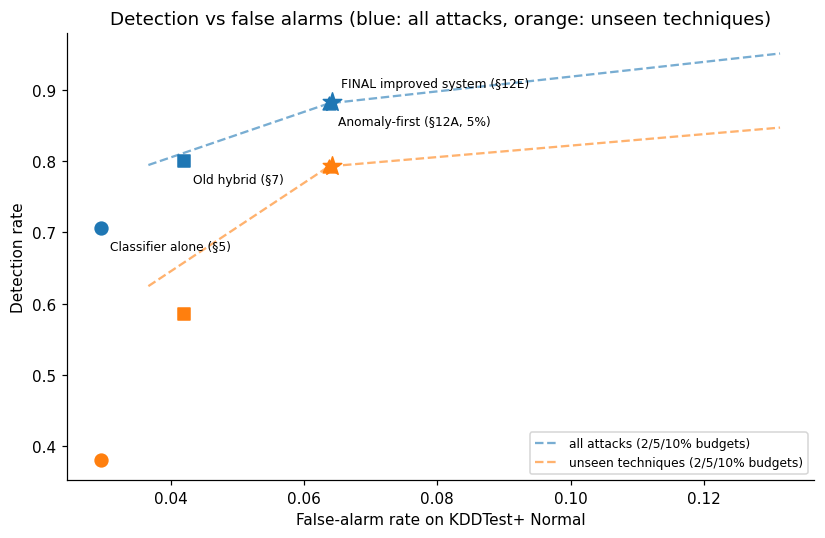

Claims vs evidence, updated with §12E:


,claim,evidence from this run,status
0,Detect anomalies and previously unseen attacks (primary goal),"Anomaly-first system at the 5% budget: attack detection 88.1%, unseen techniques 79.3%, test Normal false alarms 6.4% (2% budget: 79.4% / 62.5% / 3.7%; 10%: 95.1% / 84.7% / 13.1%). Classifier alone: 70.6% / 38.1% / 3.0%",Met; test false alarms run above the training budget because KDDTest+ Normal traffic differs from training
1,Normal-only anomaly score quality (no attack labels used),"kNN distance chosen on validation: ROC AUC 0.955, PR AUC 0.951",Met
2,Unknown-attack output and family naming,33.2% of alerts labelled Unknown attack; named families correct 93.7% of the time (confidence cutoff 0.85 from validation),Met
3,R2L / U2R detection (as Not normal),"R2L 54.6%, U2R 85.1% flagged at the 5% budget (classifier alone 29.5% / 46.3%)","Partially met: detection improves, many still look normal"
4,R2L / U2R exact family (second stage),"R2L recall 27.9% → 33.3%, U2R 38.8% → 41.8%; Normal false alarms 2.96% → 3.04%","Limitation: small gain; techniques never seen in training stay at 0% (httptunnel, snmpgetattack, snmpguess)"
5,Host and time based anomaly detection (UNSW-NB15),"held-out attacker hosts: host-minute AUC 0.952, PR AUC 0.801, recall 81.2%, false alarms 6.9%; on §9a windows AUC 0.9968 vs HMM 0.9880 and supervised flow booster 0.9939",Met for 3 of 4 attacker hosts; one host is hard
6,"Generalisation to later UNSW-NB15 traffic (shards 2-4, never used for fitting)","UNSW-NB15_2.csv: AUC 0.998, recall 100.0%, false alarms 5.1%; UNSW-NB15_3.csv: AUC 0.993, recall 100.0%, false alarms 10.8%; UNSW-NB15_4.csv: AUC 0.991, recall 100.0%, false alarms 10.4%",Met for ranking; false alarms drift above the 5% budget on later shards
7,Supervised and ensemble classification (secondary goal),"Gradient boosting (class-weighted): accuracy 80.24%, macro F1 0.686",Met
8,Clustering for unknown patterns,"k-means k=5, purity 0.730; normal-only scores catch 79.3% of test-only techniques",Met
9,HMMs for multi-stage behaviour,real UNSW order adds +0.0000 AUC; simulated chain 0.870 ordered vs 0.641 shuffled,Partially met: order only helps on simulated chains


In [27]:
# ---------- E6. One summary figure ----------
fig, ax = plt.subplots(figsize=(7.6, 5))
markers = {'Classifier alone (§5)': 'o', 'Old hybrid (§7)': 's', 'Anomaly-first (§12A, 5%)': '^',
           'FINAL improved system (§12E)': '*'}
for _, r in final_comparison[final_comparison.system.isin(markers)].iterrows():
    m = markers[r.system]
    ax.scatter(r.normal_fpr, r.attack_detection, marker=m, s=160 if m == '*' else 70, color='tab:blue', zorder=3)
    ax.scatter(r.normal_fpr, r.unseen_technique_detection, marker=m, s=160 if m == '*' else 70, color='tab:orange', zorder=3)
    offset = (6, 10) if m == '*' else (6, -14)          # keep the two overlapping 5% points readable
    ax.annotate(r.system, (r.normal_fpr, r.attack_detection), textcoords='offset points', xytext=offset, fontsize=8)
curve = anomaly_operating[anomaly_operating.system.str.startswith('Anomaly-first')]
ax.plot(curve.normal_fpr, curve.attack_detection, '--', color='tab:blue', alpha=.6, label='all attacks (2/5/10% budgets)')
ax.plot(curve.normal_fpr, curve.unseen_technique_detection, '--', color='tab:orange', alpha=.6,
        label='unseen techniques (2/5/10% budgets)')
ax.set(xlabel='False-alarm rate on KDDTest+ Normal', ylabel='Detection rate',
       title='Detection vs false alarms (blue: all attacks, orange: unseen techniques)')
ax.legend(fontsize=8, loc='lower right')
plt.tight_layout()
fig.savefig(OUTPUT / 'detection_vs_false_alarms.png', dpi=150)
plt.show()

# ---------- update the §12D claims table with the improvements ----------
fs = FINAL_SYSTEM
improved_claims = [
    ('FINAL anomaly-first system (§12E, all choices from training data)',
     f'attack detection {fs["attack_detection"]:.1%}, unseen techniques {fs["unseen_technique_detection"]:.1%}, '
     f'R2L {fs["R2L_detection"]:.1%}, U2R {fs["U2R_detection"]:.1%} flagged; test Normal false alarms {fs["normal_fpr"]:.1%}; '
     f'ROC AUC {fs["roc_auc"]:.3f}, PR AUC {fs["pr_auc"]:.3f}', 'Met (false alarms above the 5% training budget)'),
    ('Exact family names (§12E)',
     f'{fs["exact_name_rate_attacks"]:.1%} of attacks named correctly; R2L {fs["R2L_exact_name_rate"]:.1%} '
     f'(precision {fs["R2L_name_precision"]:.1%}), U2R {fs["U2R_exact_name_rate"]:.1%} (precision {fs["U2R_name_precision"]:.1%}); '
     f'five-class accuracy {fs["five_class_accuracy_unknown_wrong"]:.2%}, macro F1 {fs["five_class_macro_f1_unknown_wrong"]:.3f} '
     f'(Unknown counted wrong)',
     'Met' if fs['five_class_accuracy_unknown_wrong'] >= PRIMARY_ACCURACY else 'Partially met'),
    ('Train-test drift of Normal traffic (§12E)',
     f'most shifted feature {drift_table.iloc[0].feature} (KS {drift_table.iloc[0, 2]:.3f} train vs test, '
     f'{drift_table.iloc[0, 1]:.3f} within training); drift-robust variants did not win validation',
     'Limitation: needs recalibration on the deployment network'),
]
if ttl_comparison is not None:
    improved_claims.append((
        'UNSW host-and-time detection without TTL (honest headline)',
        f'AUC {NO_TTL_SUMMARY["host_minute_auc"]:.3f} (with TTL {HOST_SUMMARY["host_minute_auc"]:.3f}), recall '
        f'{NO_TTL_SUMMARY["host_minute_recall"]:.1%}, false alarms {NO_TTL_SUMMARY["host_minute_fpr"]:.1%}; §9a windows AUC '
        f'{NO_TTL_SUMMARY["pair_window_auc"]:.4f}',
        f'Partially met: {NO_TTL_SUMMARY["hosts_above_095"]} of {len(attack_hosts)} attacker hosts above AUC 0.95'))
claims_table = pd.concat([claims_table, pd.DataFrame(improved_claims, columns=claims_table.columns)], ignore_index=True)
print('Claims vs evidence, updated with §12E:')
with pd.option_context('display.max_colwidth', None):
    display(claims_table)

## 13. Results against the problem statement

The table below is generated from this run's numbers. Each claim is stated at the strength the evidence supports. All results files are exported to `outputs/final_ids/`.

In [28]:
r2l = primary_per_class.loc['R2L']
u2r = primary_per_class.loc['U2R']
aug = ablation.iloc[1]
rows = [
    ('Five-class classification (official KDDTest+)',
     f'{SELECTED_NAME}: accuracy {PRIMARY_ACCURACY:.2%}, macro F1 {PRIMARY_MACRO_F1:.3f}, '
     f'weighted F1 {f1_score(yte, primary_prediction, average="weighted"):.3f}',
     'Met (target ≥ 80%)' if PRIMARY_ACCURACY >= 0.80 else 'Below 80% target'),
    ('Attack vs normal detection (hybrid system)',
     f'accuracy {HYBRID["binary_accuracy"]:.2%}, attack recall {HYBRID["attack_recall"]:.2%}, '
     f'false alarms {HYBRID["normal_fpr"]:.2%} (classifier alone: {PRIMARY_BINARY["accuracy"]:.2%} / '
     f'{PRIMARY_BINARY["recall"]:.2%} / {PRIMARY_BINARY["normal_fpr"]:.2%})', 'Met'),
    ('Supervised and ensemble models compared',
     f'{len(comparison)} models incl. logistic regression, linear SVM, decision tree, random forest, '
     f'Extra Trees, gradient boosting, soft voting; selected by leave-attack-type-out validation', 'Met'),
    ('Evaluation under class imbalance',
     f'R2L precision {r2l.precision:.2%} / recall {r2l.recall:.2%}; U2R precision {u2r.precision:.2%} / '
     f'recall {u2r.recall:.2%}; per-class PR and ROC curves, Wilson intervals, per-technique recall',
     'Met (R2L/U2R recall remains the main limitation)'),
    ('Clustering to discover unknown attack patterns',
     f'k-means k={chosen_k}, purity {cluster_metrics["purity"]:.3f}, NMI {cluster_metrics["NMI"]:.3f}; '
     f'{SELECTED_DETECTOR} hybrid detects {HYBRID["novel_attack_detection"]:.1%} of test-only attack rows '
     f'(classifier alone {np.mean(base_alerts[novel_mask]):.1%})', 'Met'),
    ('Supervised models informed by EDA / unsupervised analysis',
     f'class weighting from EDA; hybrid recovers {int(recovered.sum())} of {int(missed.sum())} attacks the classifier '
     f'missed, {HYBRID["new_alerts_that_are_attacks"]:.1%} of its new alerts are real attacks; '
     f'feature-level variant: accuracy {aug.accuracy:.2%} vs {PRIMARY_ACCURACY:.2%}, macro F1 {aug.macro_f1:.3f} '
     f'vs {PRIMARY_MACRO_F1:.3f}',
     'Met (decision-level link)' if HYBRID['attack_recall'] > PRIMARY_BINARY['recall'] else 'Not improved'),
    ('HMM: NSL-KDD file order',
     f'file order {nsl_diagnostic["file_order_accuracy"]:.3f} vs shuffled {nsl_diagnostic["shuffled_order_accuracy"]:.3f} '
     f'vs emission-only {nsl_diagnostic["emission_only_accuracy"]:.3f}',
     'Answered: no sequence information'
     if abs(nsl_diagnostic['file_order_accuracy'] - nsl_diagnostic['shuffled_order_accuracy']) < 0.01
     else 'File order carries some signal'),
    ('HMM: controlled multi-stage chain (simulated)',
     f'stage accuracy ordered {SIMULATION["HMM ordered"]:.3f} vs emission-only {SIMULATION["Emission only"]:.3f} '
     f'vs shuffled {SIMULATION["HMM shuffled"]:.3f}',
     'Met: HMM uses stage order when it exists'
     if SIMULATION['HMM ordered'] > max(SIMULATION['Emission only'], SIMULATION['HMM shuffled']) + 0.02
     else 'Order not exploited'),
]
if order_effect is not None:
    rows.append(('HMM: real UNSW-NB15 sequences, held-out attacker hosts',
                 f'detection AUC {order_effect["hmm_auc"]:.4f}; shuffled {order_effect["shuffled_auc"]:.4f} '
                 f'(difference {order_effect["hmm_minus_shuffled_auc"]:+.4f}); per-flow baseline '
                 f'{order_effect["flow_baseline_auc"]:.4f}; category labelling macro F1 HMM '
                 f'{order_effect["category_hmm_macro_f1"]:.3f} vs emission-only '
                 f'{order_effect["category_emission_only_macro_f1"]:.3f} '
                 f'({order_effect["category_folds_hmm_better"]}/{len(attack_hosts)} folds)',
                 'Answered: order adds little to detection on this data'
                 if abs(order_effect['hmm_minus_shuffled_auc']) < 0.01
                 else ('Order improves detection' if order_effect['hmm_minus_shuffled_auc'] > 0
                       else 'Shuffled order scores higher')))
else:
    rows.append(('HMM: real UNSW-NB15 sequences', 'UNSW-NB15_1.csv not found in this run', 'Not run'))
if transfer_table is not None:
    cross = transfer_table[transfer_table.direction.str.contains('cross')]
    rows.append(('Integration of public datasets (shared schema)',
                 '; '.join(f'{d}: balanced accuracy {b:.3f}' for d, b in zip(cross.direction, cross.balanced_accuracy)),
                 'Met: pipeline integrated; cross-dataset transfer is weak'
                 if cross.balanced_accuracy.max() < 0.65 else 'Met: pipeline integrated; partial transfer'))
else:
    rows.append(('Integration of public datasets (shared schema)', 'UNSW-NB15_1.csv not found in this run', 'Not run'))
rows.append(('Risk classification and decision support',
             f'tiers Low/Medium/High/Critical; {RISK_SUMMARY["attacks_in_high_or_critical"]:.1%} of attacks rated '
             f'High/Critical vs {RISK_SUMMARY["normal_in_high_or_critical"]:.1%} of normal traffic; '
             f'{LATENCY["connections_per_second"]:,.0f} connections/s offline', 'Met (offline prototype)'))
rows.append(('Anomaly-first detection, primary goal (§12A, 5% budget)',
             f'attack detection {AF_SUMMARY["attack_detection"]:.2%}, unseen techniques {AF_SUMMARY["unseen_technique_detection"]:.2%}, '
             f'R2L {AF_SUMMARY["R2L_detection"]:.2%}, U2R {AF_SUMMARY["U2R_detection"]:.2%}, test Normal false alarms '
             f'{AF_SUMMARY["normal_fpr"]:.2%}; {AF_SCORE} ROC AUC {score_quality.set_index("score").loc[AF_SCORE, "roc_auc"]:.3f}',
             'Met (false alarms above the training budget on test Normal)'))
rows.append(('R2L/U2R second stage (§12B)',
             f'R2L recall {stage2_table.iloc[0].R2L_recall:.2%} → {stage2_table.iloc[1].R2L_recall:.2%}, U2R '
             f'{stage2_table.iloc[0].U2R_recall:.2%} → {stage2_table.iloc[1].U2R_recall:.2%}, Normal false alarms '
             f'{stage2_table.iloc[0].normal_fpr:.2%} → {stage2_table.iloc[1].normal_fpr:.2%}', 'Partially met (small gain)'))
if host_results is not None:
    rows.append(('UNSW-NB15 host-and-time anomaly detection (§12C)',
                 f'held-out attacker hosts: AUC {HOST_SUMMARY["host_minute_auc"]:.3f}, recall {HOST_SUMMARY["host_minute_recall"]:.2%}, '
                 f'false alarms {HOST_SUMMARY["host_minute_fpr"]:.2%}; §9a windows AUC {HOST_SUMMARY["pair_window_auc"]:.4f}',
                 'Met (normal-only, no attack labels in training)'))
rows.append(('FINAL improved anomaly-first system (§12E)',
             f'attack detection {FINAL_SYSTEM["attack_detection"]:.2%}, unseen techniques {FINAL_SYSTEM["unseen_technique_detection"]:.2%}, '
             f'test Normal false alarms {FINAL_SYSTEM["normal_fpr"]:.2%}; R2L exact name {FINAL_SYSTEM["R2L_exact_name_rate"]:.2%}, '
             f'U2R {FINAL_SYSTEM["U2R_exact_name_rate"]:.2%}; five-class accuracy {FINAL_SYSTEM["five_class_accuracy_unknown_wrong"]:.2%}, '
             f'macro F1 {FINAL_SYSTEM["five_class_macro_f1_unknown_wrong"]:.3f} (Unknown counted wrong)',
             'Met (false alarms above the training budget on test Normal)'))
if ttl_comparison is not None:
    rows.append(('UNSW-NB15 host-and-time detection without TTL (§12E, honest headline)',
                 f'AUC {NO_TTL_SUMMARY["host_minute_auc"]:.3f}, recall {NO_TTL_SUMMARY["host_minute_recall"]:.2%}, '
                 f'false alarms {NO_TTL_SUMMARY["host_minute_fpr"]:.2%}; with TTL AUC {HOST_SUMMARY["host_minute_auc"]:.3f}',
                 f'Partially met ({NO_TTL_SUMMARY["hosts_above_095"]} of {len(attack_hosts)} hosts above AUC 0.95)'))
requirements = pd.DataFrame(rows, columns=['requirement', 'evidence from this run', 'status'])
with pd.option_context('display.max_colwidth', None):
    display(requirements)

results = {
    'versions': VERSIONS, 'seed': SEED, 'data_manifest': DATA_MANIFEST,
    'selected_model': SELECTED_NAME, 'selected_detector': SELECTED_DETECTOR,
    'validation': validation_table.to_dict('records'), 'test_comparison': comparison.to_dict('records'),
    'primary_per_class': primary_per_class.reset_index(names='family').to_dict('records'),
    'primary_binary': PRIMARY_BINARY, 'minority': minority_rows, 'roc_pr': curve_metrics,
    'clusters': cluster_metrics, 'novel_attack_clusters': novel_clusters.to_dict('records'),
    'hybrid': hybrid_table.to_dict('records'), 'hybrid_selected': HYBRID,
    'hybrid_recovery_by_family': by_family.to_dict('records'), 'ablation': ablation.to_dict('records'),
    'nsl_order_diagnostic': nsl_diagnostic, 'simulation': simulation_results.to_dict('records'),
    'unsw_sequences': None if sequence_results is None else sequence_results.to_dict('records'),
    'unsw_order_effect': order_effect,
    'transfer': None if transfer_table is None else transfer_table.to_dict('records'),
    'risk_policy': RISK_POLICY, 'risk_summary': RISK_SUMMARY, 'latency': LATENCY,
    'requirements': requirements.to_dict('records'), 'runtime_seconds': time.time() - RUN_STARTED,
}
results.update({
    'anomaly_first_choice': pd.DataFrame(af_choice_rows).to_dict('records'), 'anomaly_score': AF_SCORE, 'naming_cutoff': UNKNOWN_CUTOFF,
    'anomaly_score_quality': score_quality.to_dict('records'), 'anomaly_operating_points': anomaly_operating.to_dict('records'),
    'anomaly_first_summary': AF_SUMMARY, 'stage2_threshold': STAGE2_THRESHOLD, 'stage2': stage2_table.to_dict('records'),
    'full_anomaly_first_system': FULL_SYSTEM, 'claims_vs_evidence': claims_table.to_dict('records'),
    'unsw_host_time': None if host_results is None else host_results.to_dict('records'),
    'unsw_host_time_vs_hmm': None if host_pair_results is None else host_pair_results.to_dict('records'),
    'unsw_extra_shards': None if host_shard_results is None else host_shard_results.to_dict('records'),
})
results.update({
    'drift': drift_table.to_dict('records'), 'robust_validation': pd.DataFrame(robust_rows).to_dict('records'),
    'robust_choice': list(ROBUST_CHOICE), 'robust_test_diagnostic': drift_test.to_dict('records'),
    'stage2_compare': stage2_compare.to_dict('records'), 'stage2_v2_test': stage2_table_v2.to_dict('records'),
    'u2r_share_cutoff': U2R_SHARE_CUTOFF, 'naming_validation': naming_table.reset_index().to_dict('records'),
    'final_config': FINAL_CONFIG, 'final_system': FINAL_SYSTEM, 'system_comparison': final_comparison.to_dict('records'),
    'final_risk_tiers': final_risk.to_dict(), 'claims_vs_evidence': claims_table.to_dict('records'),
    'unsw_no_ttl': None if ttl_comparison is None else nottl_folds.to_dict('records'),
    'unsw_no_ttl_shards': None if ttl_comparison is None else nottl_shards.to_dict('records'),
    'unsw_ttl_comparison': None if ttl_comparison is None else ttl_comparison.reset_index().to_dict('records'),
})


def json_default(value):
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, Path):
        return str(value)
    raise TypeError(type(value).__name__)


(OUTPUT / 'results.json').write_text(json.dumps(results, indent=2, default=json_default), encoding='utf-8')
export = test[['attack', 'risk']].rename(columns={'risk': 'true_family'}).copy()
export['classifier_prediction'] = primary_prediction
export['hybrid_prediction'] = hybrid_prediction
export['risk_tier'] = risk_output.risk_tier.to_numpy()
export['attack_probability'] = 1 - primary_scores[:, 0]
export['test_only_attack'] = novel_mask
export['anomaly_first_prediction'] = full_prediction
export['anomaly_percentile'] = anomaly_test
export['final_system_prediction'] = final_prediction
export['final_risk_tier'] = [RISK_POLICY[x] for x in final_prediction]
final_comparison.to_csv(OUTPUT / 'system_comparison_test.csv', index=False)
export.to_csv(OUTPUT / 'nsl_test_predictions.csv', index_label='test_row')
comparison.to_csv(OUTPUT / 'model_comparison_test.csv', index=False)
validation_table.to_csv(OUTPUT / 'model_selection_validation.csv', index=False)
attack_name_results.to_csv(OUTPUT / 'per_attack_results.csv', index=False)
print(f'Exported to {OUTPUT} | total runtime {time.time() - RUN_STARTED:.0f}s')

,requirement,evidence from this run,status
0,Five-class classification (official KDDTest+),"Gradient boosting (class-weighted): accuracy 80.24%, macro F1 0.686, weighted F1 0.786",Met (target ≥ 80%)
1,Attack vs normal detection (hybrid system),"accuracy 86.79%, attack recall 79.98%, false alarms 4.20% (classifier alone: 82.00% / 70.61% / 2.96%)",Met
2,Supervised and ensemble models compared,"9 models incl. logistic regression, linear SVM, decision tree, random forest, Extra Trees, gradient boosting, soft voting; selected by leave-attack-type-out validation",Met
3,Evaluation under class imbalance,"R2L precision 98.77% / recall 27.87%; U2R precision 66.67% / recall 38.81%; per-class PR and ROC curves, Wilson intervals, per-technique recall",Met (R2L/U2R recall remains the main limitation)
4,Clustering to discover unknown attack patterns,"k-means k=5, purity 0.730, NMI 0.406; Centroid distance hybrid detects 58.5% of test-only attack rows (classifier alone 38.1%)",Met
5,Supervised models informed by EDA / unsupervised analysis,"class weighting from EDA; hybrid recovers 1202 of 3771 attacks the classifier missed, 90.9% of its new alerts are real attacks; feature-level variant: accuracy 80.50% vs 80.24%, macro F1 0.653 vs 0.686",Met (decision-level link)
6,HMM: NSL-KDD file order,file order 0.723 vs shuffled 0.723 vs emission-only 0.723,Answered: no sequence information
7,HMM: controlled multi-stage chain (simulated),stage accuracy ordered 0.870 vs emission-only 0.704 vs shuffled 0.641,Met: HMM uses stage order when it exists
8,"HMM: real UNSW-NB15 sequences, held-out attacker hosts",detection AUC 0.9880; shuffled 0.9880 (difference +0.0000); per-flow baseline 0.9939; category labelling macro F1 HMM 0.178 vs emission-only 0.124 (4/4 folds),Answered: order adds little to detection on this data
9,Integration of public datasets (shared schema),NSL-KDD → UNSW-NB15 (cross-dataset): balanced accuracy 0.497; UNSW-NB15 → NSL-KDD test (cross-dataset): balanced accuracy 0.539,Met: pipeline integrated; cross-dataset transfer is weak


Exported to /home/bhavyam/Semester 5/Machine Learning /ML_Project/outputs/final_ids | total runtime 300s


## 14. Conclusions, limitations and future work

**Conclusions**
- Class-weighted gradient boosting, chosen by validation on unseen attack techniques, classifies the official test set into five families at the accuracy shown in §13, with strong DoS, Probe and Normal performance.
- The test set's difficulty comes from attack techniques that are rare or absent in training. Every supervised model misses many of them; adding samples (oversampling) does not help, because the problem is new techniques rather than too few examples.
- A detector trained only on normal traffic catches many of these unseen attacks. Combining it with the classifier at decision level raises attack detection substantially at a small cost in false alarms. Feeding its scores in as extra features instead barely changes accuracy and lowers macro F1 and R2L/U2R recall, so the decision-level combination is the useful link.
- The HMM captures stage order when it genuinely exists (simulated chain: ordered decoding clearly beats shuffled and emission-only decoding). NSL-KDD has no usable order. On real UNSW-NB15 traffic (§9) the comparison with shuffled windows and with a per-flow classifier shows how much flow order actually adds to detection; on this shard it adds little, because the few attacker hosts are already recognisable from individual flows.
- The shared-schema test (§11) measures whether a detector trained on one network carries over to another. Balanced accuracy near 0.5 in the cross-dataset rows means it does not, and a deployed system would need retraining on its own network's traffic.

- **Anomaly-first view (§12A–12D).** Making "is this normal?" the main question, answered by detectors trained only on Normal traffic, catches far more attacks and far more never-seen techniques than the classifier alone. The validation-chosen kNN distance score is the strongest single detector. The cost is more false alarms, and on `KDDTest+` they run above the budget set on training Normal, because test Normal traffic is distributed differently. The 2%/5%/10% table makes this trade-off explicit for an operator.
- About a third of alerts are reported as `Unknown attack` instead of being forced into a family; when the system does name a family it is usually right. This is the honest output for new techniques.
- The R2L/U2R second stage gives only a small gain in exact-family recall. R2L techniques that never appear in training stay undetected *as R2L*, although the anomaly score flags many of them as Not normal.
- On UNSW-NB15, host-and-time windows let a normal-only detector find held-out attacker hosts with no attack labels in training. On the §9a windows it ranks attacks about as well as the supervised HMM and the per-flow booster, and it keeps working on later capture days (shards 2–4), although false alarms drift upward there. One of the four attacker hosts is hard to separate.

- **Improvements (§12E).** The richer R2L/U2R second stage, with behaviour features and the distance to normal traffic, is the change that helped most: it clearly raises exact R2L recall and five-class macro F1, raises U2R recall slightly, and costs some R2L/U2R precision. R2L techniques with no training examples (SNMP guessing, `httptunnel`) are still not named. Tuning the naming cutoff for the whole pipeline names far more attacks correctly instead of reporting them as Unknown. The One-Class SVM and the drift-robust feature spaces did not beat the plain kNN distance on validation, so they are reported but not used.
- **Honest UNSW headline.** Without the TTL features, the host-and-time detector is clearly weaker and less consistent across attacker hosts. The without-TTL numbers in §12E-4 are the ones to quote.

**Limitations**
- R2L and U2R recall stays low: these attacks look like ordinary sessions at the connection level. Host logs or payload/content features would be needed.
- UNSW-NB15 has only a handful of attacker hosts and no campaign-level stage labels, so real multi-stage detection cannot be fully validated.
- Risk tiers are a policy, not calibrated harm estimates; throughput is offline and excludes packet capture.
- Drift between training and test Normal traffic (§12E-1) cannot be seen from training data alone, and no drift-robust variant fixed it, so the false-alarm budget is not met on test Normal. Normal-only thresholds are set on training Normal; when the normal traffic of a network changes (as between `KDDTrain+` and `KDDTest+`, or between UNSW-NB15 capture days), false alarms rise and thresholds need recalibration on recent normal traffic.
- UNSW-NB15 attacker hosts differ from benign hosts in TTL, a testbed artefact that makes host-level detection easier than on a real network, and there are only four attacker hosts.

**Future work:** content-level and host-based features for R2L/U2R; a continuous risk score combining class probabilities and severity weights; datasets with labelled multi-stage campaigns; streaming deployment.

**References:** NSL-KDD — Tavallaee et al., *A Detailed Analysis of the KDD CUP 99 Data Set* (2009), https://www.unb.ca/cic/datasets/nsl.html · UNSW-NB15 — Moustafa & Slay (2015), https://research.unsw.edu.au/projects/unsw-nb15-dataset · HMMs — Rabiner, *A Tutorial on Hidden Markov Models* (1989) · scikit-learn model evaluation, https://scikit-learn.org/stable/modules/model_evaluation.html